# Publication analyses

- **Part I.** Independent validation of NNLS deconvolution on GSE196902 and the GSE290585 reference/pool split: pure samples, mixtures, held-out tissues, detection limit in an 85 % blood background.
- **Part II.** Publication figures: blood-fixed complexity sweep, one-tissue recovery map, cfDNA-hard mixtures.
- **Part III.** NNLS deconvolution of four external mm10 datasets.

Input: `GSE196902_MM285_normal_processed.csv`, written by `publication_preprocessing.ipynb`.

Run top to bottom; parts reuse names such as `W`, `W_full`, `FIG_DIR` and `N_PER_CELL`.

In [1]:
# ---- Figure output -----------------------------------------------------------
SAVE_FIGURES = False    # True writes every figure to disk

# Part I. Independent validation of NNLS deconvolution: GSE196902

Deconvolves an **independent** MM285 dataset against the mouse methylation atlas.
GSE196902 contributed nothing to the atlas, so this measures real cross-dataset
generalisation rather than held-out performance within one dataset.

Two things live here:

1. **A reusable inference path**: align any MM285 sample to the deconvolution panel and
   run NNLS. This is the piece that generalises to real cfDNA.
2. **Validation**: pure samples first (the strictest test), then synthetic mixtures of
   increasing complexity.

Input: `GSE196902_MM285_normal_processed.csv`, written by `publication_preprocessing.ipynb`.

In [2]:
# ---- Setup -------------------------------------------------------------------
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, "../src")

import config
import data_loading
import deconv_data
import deconv_model
from utils import (
    build_label_map,
    extract_sample_labels,
    build_centroids,
    select_probes_from_centroids,
)

# src/visualization.py forces Agg at import; inline renders to an embedded PNG and needs no
# display server, so this stays headless-safe while letting figures show in the notebook.
%matplotlib inline


def _show_src(plot_fn, *args, **kwargs):
    """Run a deconv_model plot function and display its figure before src saves and closes it."""
    original = deconv_model._save_or_close

    def show_then_save(output_path=None, dpi=150):
        display(plt.gcf())
        original(output_path, dpi)

    deconv_model._save_or_close = show_then_save
    try:
        plot_fn(*args, **kwargs)
    finally:
        deconv_model._save_or_close = original

VAL_PATH = config.DATA_DIR / "processed" / "GSE196902_MM285_normal_processed.csv"
FIG_DIR  = config.FIGURES_DIR / "publication" / "validation"
FMT, DPI = config.FIGURE_FORMAT, config.FIGURE_DPI

if SAVE_FIGURES:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"figures -> {FIG_DIR.relative_to(config.PROJECT_ROOT)}")

figures -> figures/publication/validation


## I.1 Reference matrix W

Built from **all 268 GSE290585 samples**. No reference/pool split: that split exists only to
stop synthetic mixtures leaking into their own reference, and validation now comes from a
different GEO series entirely.

Rebuilt rather than loaded from `top_50_regions_df.csv`. The two are numerically identical,
but the line that writes that file is commented out in `run_pipeline.py`, so it is a frozen
artifact with nothing keeping it in sync with `config.py`.

In [3]:
# ---- Build W from the full atlas ---------------------------------------------
df_atlas_raw, _, _, _ = data_loading.load_all()

atlas_labels = extract_sample_labels(df_atlas_raw)
atlas_labels = atlas_labels[~atlas_labels.isin(data_loading.EXCLUDED_TISSUES)]
print(f"atlas samples used: {len(atlas_labels)} (excluded: {sorted(data_loading.EXCLUDED_TISSUES)})")

# merged tissue centroids over every remaining replicate
df_atlas_centroids = build_centroids(
    df_raw=df_atlas_raw,
    sample_cols=atlas_labels.index.tolist(),
    original_labels=atlas_labels,
    merge_groups=data_loading.MERGE_GROUPS,
)

# probe panel: top MAX_PER_TISSUE unique regions per tissue
panel_probes = select_probes_from_centroids(df_atlas_centroids)

W_full = df_atlas_centroids.set_index("probe_ID").loc[panel_probes]
print(f"\nW_full: {W_full.shape[0]} probes x {W_full.shape[1]} tissues")

atlas samples used: 240 (excluded: ['Mammary_Glands', 'Optic_Nerve', 'Sciatic_Nerve', 'Thymus'])



W_full: 1000 probes x 20 tissues


In [4]:
# ---- Validate W --------------------------------------------------------------
cond_number = deconv_data.validate_reference(W_full)

Condition number of W: 94.6

Per-tissue beta value summary (across selected probes):
                              mean       std       min       max
Eye_Retina                0.832799  0.139477  0.167157  0.973786
Brain_Cortex_Subcortical  0.842054  0.098701  0.448927  0.979264
Blood_Spleen              0.869258  0.103455  0.119894  0.976814
Skin_Ears_Tail            0.808759  0.108548  0.331568  0.975861
Adrenal                   0.835692  0.106930  0.286000  0.976167
Bile_Duct                 0.838123  0.068678  0.510167  0.975833
Cerebellum                0.843233  0.164169  0.137778  0.985111
Colon                     0.812228  0.103847  0.388455  0.975818
Diaphragm                 0.817050  0.081086  0.505500  0.969833
Femur                     0.798713  0.090799  0.242800  0.972000
Heart                     0.857983  0.075740  0.488000  0.979300
Kidney                    0.833935  0.099152  0.373917  0.979167
Liver                     0.844082  0.130390  0.238538  0.980308
Lung 

In [5]:
# ---- Cross-check against the saved atlas panel (optional sanity check) -------
# W_full should equal top_50_regions_df.csv transposed. A mismatch is not an error:
# it means config.py has changed since that file was last written by hand.

saved_path = config.DECONV_ATLAS_PROBES_PATH
if saved_path.exists():
    saved = pd.read_csv(saved_path, index_col=0).T
    probes  = W_full.index.intersection(saved.index)
    tissues = W_full.columns.intersection(saved.columns)
    if len(probes) and len(tissues):
        diff = (W_full.loc[probes, tissues] - saved.loc[probes, tissues]).abs().to_numpy().max()
        print(f"shared with saved panel: {len(probes)} probes x {len(tissues)} tissues")
        print(f"max |difference|: {diff:.2e}"
              + ("  — identical" if diff < 1e-9 else "  ⚠ config.py has changed since that file was written"))
    else:
        print("⚠ no overlap with the saved panel — probe selection has changed substantially")
else:
    print(f"saved panel not found at DATA_DIR/{saved_path.relative_to(config.DATA_DIR)}, skipping cross-check")

shared with saved panel: 1000 probes x 20 tissues
max |difference|: 1.11e-16  — identical


## I.2 Validation data and tissue mapping

The processed CSV carries duplicate tissue-named columns, so pandas re-reads them as
`Lung`, `Lung.1`, `Lung.2`, exactly the `<Tissue>.<n>` convention `extract_sample_labels`
already parses. No adapter needed.

**Mixtures may only contain tissues that exist in W.** `VAL_TO_ATLAS` below is the single
source of truth for that: labels absent from it are excluded from all mixture generation.

Two consequences worth keeping in view:

- `Spleen` maps to `Blood_Spleen`. GSE196902 has no true Blood samples, so this column is
  represented by spleen only.
- `BM`, `Breast`, `Prostate` and `Thymus` have no atlas counterpart (`Mammary_Glands` and
  `Thymus` are in `EXCLUDED_TISSUES`). They are held out of mixtures and reused in section I.6 as
  unknown-component material.

In [6]:
# ---- Load the validation matrix ----------------------------------------------
df_val = pd.read_csv(VAL_PATH)
df_val_indexed = df_val.set_index("probe_ID")
val_labels = extract_sample_labels(df_val)

print(f"df_val: {df_val.shape[0]} probes x {len(val_labels)} samples")
print(f"total NaN beta values: {int(df_val_indexed.isna().sum().sum()):,}")
print(f"\nvalidation labels:\n{val_labels.value_counts().sort_index().to_string()}")

df_val: 287050 probes x 56 samples
total NaN beta values: 664

validation labels:
original_tissue
BM           2
Brain        3
Breast       4
Colon        2
Liver        3
Lung        14
Pancreas     4
Prostate     4
Skin         7
Spleen       6
Thymus       7


In [7]:
# ---- Validation label -> atlas tissue ----------------------------------------
# Single source of truth for which tissues may appear in mixtures. Any label not a key
# here is excluded from mixture generation by construction.
VAL_TO_ATLAS = {
    "Brain":    "Brain_Cortex_Subcortical",
    "Colon":    "Colon",
    "Liver":    "Liver",
    "Lung":     "Lung",
    "Pancreas": "Pancreas",
    "Skin":     "Skin_Ears_Tail",
    "Spleen":   "Blood_Spleen",
    # BM, Breast, Prostate, Thymus -> no atlas counterpart, deliberately absent
}

# every mapped target must actually exist in W, or mixtures would reference a missing column
unknown = sorted(set(VAL_TO_ATLAS.values()) - set(W_full.columns))
assert not unknown, f"VAL_TO_ATLAS maps to tissues absent from W: {unknown}"

mixable_labels  = val_labels[val_labels.isin(VAL_TO_ATLAS)]
heldout_labels  = val_labels[~val_labels.isin(VAL_TO_ATLAS)]
atlas_tissues   = sorted(set(VAL_TO_ATLAS[t] for t in mixable_labels.unique()))

print(f"mixable samples : {len(mixable_labels)}  -> {len(atlas_tissues)} distinct atlas tissues")
print(f"held out        : {len(heldout_labels)}  ({sorted(heldout_labels.unique())})")

print("\nreplicates per atlas tissue:")
print(mixable_labels.map(VAL_TO_ATLAS).value_counts().sort_index().to_string())

mixable samples : 39  -> 7 distinct atlas tissues
held out        : 17  (['BM', 'Breast', 'Prostate', 'Thymus'])

replicates per atlas tissue:
original_tissue
Blood_Spleen                 6
Brain_Cortex_Subcortical     3
Colon                        2
Liver                        3
Lung                        14
Pancreas                     4
Skin_Ears_Tail               7


In [8]:
# ---- Probe overlap: panel vs validation --------------------------------------
# Computed ONCE and reused everywhere downstream. Both W and every sample vector must be
# indexed by this same list in this same order (see the note in section I.3).
#
# Panel probes carrying a NaN in ANY validation sample are dropped here rather than handled
# further down. NNLS cannot accept NaN, and removing them once leaves a single aligned W
# shared by every sample and every mixture, which is what keeps residuals comparable across
# samples (section I.6 depends on that). The alternative, a different probe subset per sample,
# would make residuals incomparable for the sake of a handful of probes.

val_probe_set = set(df_val_indexed.index)
present       = [p for p in W_full.index if p in val_probe_set]

panel_block   = df_val_indexed.loc[present]
nan_probes    = set(panel_block.index[panel_block.isna().any(axis=1)])
shared_probes = [p for p in present if p not in nan_probes]

W = W_full.loc[shared_probes]

print(f"panel probes:            {len(W_full)}")
print(f"  present in validation: {len(present)}")
print(f"  dropped (NaN present): {len(nan_probes)}")
print(f"  usable:                {len(shared_probes)}")
print(f"\nW (aligned): {W.shape[0]} probes x {W.shape[1]} tissues")
print(f"condition number: {cond_number:.1f} (full panel) -> {np.linalg.cond(W.values):.1f} (aligned)")

assert not df_val_indexed.loc[shared_probes].isna().any().any(), \
    "NaN survived the probe filter — downstream NNLS would fail"

panel probes:            1000
  present in validation: 1000
  dropped (NaN present): 11
  usable:                989

W (aligned): 989 probes x 20 tissues
condition number: 94.6 (full panel) -> 94.6 (aligned)


## I.3 Inference helpers

The reusable core: point these at any MM285 sample (validation, or real cfDNA) and get
proportions back.

**Why `align_sample_to_W` reindexes rather than filters.** `W` is ordered by the differential
ranking that produced the panel, grouped by tissue. A new sample arrives in its own probe
order. Selecting the panel probes with a boolean mask returns the *right probes in the wrong
order*, so row *i* of `W` stops corresponding to element *i* of the sample vector. NNLS still
converges and still returns proportions summing to 1; they are simply wrong, with nothing in
the output to indicate it. Reindexing both sides by one shared index makes the correspondence
structural instead of assumed.

In [9]:
# ---- Alignment and inference -------------------------------------------------

def align_sample_to_W(sample: pd.Series, W: pd.DataFrame, min_overlap: float = 0.5,
                      verbose: bool = True) -> tuple:
    """
    Align one sample's beta vector to the reference panel.

    Both sides are reindexed by the SAME shared probe index in the SAME order, so row i of
    W always corresponds to element i of y. Filtering instead of reindexing would silently
    scramble that correspondence.

    Parameters
    ----------
    sample : pd.Series
        Beta values indexed by probe_ID. NaNs are dropped.
    W : pd.DataFrame
        Reference matrix (probes x tissues).
    min_overlap : float
        Minimum fraction of panel probes the sample must cover, else raise.
    verbose : bool
        Warn when panel probes are missing from the sample.

    Returns
    -------
    W_sub : pd.DataFrame   reference restricted to shared probes
    y     : np.ndarray     sample vector on the same probes, same order
    """
    sample = sample.dropna()
    shared = W.index.intersection(sample.index)
    frac   = len(shared) / len(W.index)

    if frac < min_overlap:
        raise ValueError(
            f"Only {len(shared)}/{len(W.index)} panel probes usable for this sample "
            f"({frac:.1%}) — below min_overlap={min_overlap:.0%}. "
            f"Deconvolving this few probes would not be meaningful."
        )
    if verbose and len(shared) < len(W.index):
        warnings.warn(
            f"{len(W.index) - len(shared)} of {len(W.index)} panel probes missing or NaN "
            f"in sample; deconvolving on {len(shared)}."
        )

    return W.loc[shared], sample.loc[shared].to_numpy(dtype=float)


def deconvolve_sample(sample: pd.Series, W: pd.DataFrame, min_overlap: float = 0.5,
                      verbose: bool = True) -> tuple:
    """
    Deconvolve a single sample. Returns (proportions Series, NNLS residual).

    This is the entry point for a one-off sample, a real cfDNA sample included.
    """
    W_sub, y = align_sample_to_W(sample, W, min_overlap, verbose)
    props, residual = deconv_model.deconvolve_single(W_sub.to_numpy(), y)
    return pd.Series(props, index=W_sub.columns, name=sample.name), residual


def deconvolve_matrix(df_samples: pd.DataFrame, W: pd.DataFrame, min_overlap: float = 0.5,
                      nan_policy: str = "drop_probes", verbose: bool = True) -> tuple:
    """
    Deconvolve many samples sharing one probe index.

    Aligns once, then delegates to deconv_model.deconvolve_batch.

    NNLS rejects NaN outright, so missing betas must be resolved before solving rather
    than surfacing as an opaque error from scipy.

    Parameters
    ----------
    df_samples : pd.DataFrame
        Probes as index, one column per sample.
    nan_policy : {"drop_probes", "per_sample", "raise"}
        "drop_probes": drop every probe that is NaN in ANY sample, so all samples share
            one aligned W. Residuals stay comparable across samples. Default.
        "per_sample":  deconvolve each sample on its own complete probes. Uses the most
            data per sample, but each sample then has a different feature space, so
            residuals are NOT comparable between samples.
        "raise":       refuse to proceed if any NaN is present.

    Returns
    -------
    df_estimated : pd.DataFrame   samples x tissues
    residuals    : pd.Series      NNLS residual per sample
    """
    if nan_policy not in {"drop_probes", "per_sample", "raise"}:
        raise ValueError(f"unknown nan_policy: {nan_policy!r}")

    shared = W.index.intersection(df_samples.index)
    block  = df_samples.loc[shared]
    n_nan  = int(block.isna().sum().sum())

    if n_nan and nan_policy == "raise":
        raise ValueError(
            f"{n_nan} NaN beta values across {int(block.isna().any(axis=1).sum())} probes. "
            f"Set nan_policy='drop_probes' or 'per_sample' to handle them."
        )

    if n_nan and nan_policy == "per_sample":
        if verbose:
            print(f"{n_nan} NaN values — deconvolving per sample on each sample's own probes "
                  f"(residuals are not comparable between samples)")
        props = {c: deconvolve_sample(df_samples[c], W, min_overlap, verbose=False)
                 for c in df_samples.columns}
        df_estimated = pd.DataFrame(
            {c: p for c, (p, _) in props.items()}
        ).T.reindex(columns=W.columns, fill_value=0.0)
        residuals = pd.Series({c: r for c, (_, r) in props.items()}, name="residual")
        return df_estimated, residuals.reindex(df_samples.columns)

    if n_nan:   # drop_probes
        keep = block.index[~block.isna().any(axis=1)]
        if verbose:
            print(f"{n_nan} NaN values across {len(shared) - len(keep)} probes — dropped "
                  f"({len(keep)}/{len(shared)} probes retained)")
        shared = keep

    frac = len(shared) / len(W.index)
    if frac < min_overlap:
        raise ValueError(
            f"Only {len(shared)}/{len(W.index)} panel probes usable ({frac:.1%}) — "
            f"below min_overlap={min_overlap:.0%}."
        )
    if verbose and len(shared) < len(W.index):
        warnings.warn(f"{len(W.index) - len(shared)} panel probes unusable; using {len(shared)}.")

    W_sub = W.loc[shared]
    X     = df_samples.loc[shared].to_numpy(dtype=float).T      # (n_samples, n_probes)

    df_estimated, residuals = deconv_model.deconvolve_batch(W_sub, X)
    df_estimated.index = df_samples.columns                      # restore sample names
    return df_estimated, pd.Series(residuals, index=df_samples.columns, name="residual")


print("helpers defined: align_sample_to_W, deconvolve_sample, deconvolve_matrix")

helpers defined: align_sample_to_W, deconvolve_sample, deconvolve_matrix


In [10]:
# ---- Smoke test: one sample --------------------------------------------------
# Simplest possible use of the inference path, and the template for a real cfDNA sample.

example_col = mixable_labels.index[0]

props, residual = deconvolve_sample(df_val_indexed[example_col], W)

print(f"sample: {example_col}   true tissue: {VAL_TO_ATLAS[mixable_labels[example_col]]}")
print(f"residual: {residual:.4f}\n")
print(props[props > 0.01].sort_values(ascending=False).to_string())

sample: Brain   true tissue: Brain_Cortex_Subcortical
residual: 1.7936

Brain_Cortex_Subcortical    1.0


## I.4 Stage 1: pure samples

The strictest test, and the one to read first. A synthetic k=1 mixture is arithmetically
identical to the sample itself (one replicate at weight 1.0), so deconvolving the samples
directly *is* the k=1 case.

A pure Lung sample should come back close to 100 % Lung. Whatever the gap is here is the
floor for everything in section I.5: if pure samples do not recover, mixtures cannot.

Failure here means batch effect or reference mismatch, **not** a mixture-generation bug.
Worth separating before reading anything into the mixture results.

In [11]:
# ---- Deconvolve every mixable sample -----------------------------------------
df_pure = df_val_indexed[mixable_labels.index]

df_pure_est, pure_residuals = deconvolve_matrix(df_pure, W)

# ground truth: one-hot on the mapped atlas tissue
df_pure_true = pd.DataFrame(0.0, index=df_pure_est.index, columns=df_pure_est.columns)
for col, lab in mixable_labels.items():
    df_pure_true.loc[col, VAL_TO_ATLAS[lab]] = 1.0

# recovery = proportion assigned to the correct tissue.
# The index is fixed first so every column aligns on sample name rather than position.
recovery = pd.DataFrame(index=df_pure_est.index)
recovery["true_tissue"] = mixable_labels.map(VAL_TO_ATLAS)
recovery["recovered"]   = [
    df_pure_est.loc[c, t] for c, t in zip(recovery.index, recovery["true_tissue"])
]
recovery["top_call"]  = df_pure_est.idxmax(axis=1)
recovery["top_value"] = df_pure_est.max(axis=1)
recovery["residual"]  = pure_residuals
recovery["correct"]   = recovery["true_tissue"] == recovery["top_call"]

print(f"top-1 accuracy: {recovery['correct'].mean():.1%}  "
      f"({recovery['correct'].sum()}/{len(recovery)})")
print(f"median recovery of true tissue: {recovery['recovered'].median():.3f}\n")
print(recovery.groupby("true_tissue").agg(
    n=("recovered", "size"),
    median_recovery=("recovered", "median"),
    accuracy=("correct", "mean"),
    median_residual=("residual", "median"),
).sort_values("median_recovery").to_string())

Deconvolved 39 mixtures
  Mean residual: 1.7961
  Max residual:  2.7789
top-1 accuracy: 92.3%  (36/39)
median recovery of true tissue: 0.989

                           n  median_recovery  accuracy  median_residual
true_tissue                                                             
Blood_Spleen               6         0.391739       0.5         2.280412
Skin_Ears_Tail             7         0.857353       1.0         1.591066
Pancreas                   4         0.973574       1.0         1.630082
Colon                      2         0.976081       1.0         2.416017
Lung                      14         0.995045       1.0         2.121678
Brain_Cortex_Subcortical   3         1.000000       1.0         1.766137
Liver                      3         1.000000       1.0         1.668471


In [12]:
# ---- Recovery split by DNA preservation --------------------------------------
# Preservation is confounded with tissue in this dataset: Liver is 3/3 FFPE, Lung 7/14,
# everything else mostly FF. If a tissue validates poorly, this is the first thing to check:
# "atlas does not generalise" and "FFPE degradation" are otherwise indistinguishable.

meta_path = config.DATA_DIR / "raw" / "GSE196902_family.soft"

records, current = [], {}
with open(meta_path, "r", encoding="utf-8", errors="replace") as f:
    for line in f:
        line = line.strip()
        if line.startswith("^SAMPLE"):
            if current:
                records.append(current)
            current = {"GSM": line.split("=", 1)[1].strip()}
        elif line.startswith("!Sample_title"):
            current["title"] = line.split("=", 1)[1].strip()
        elif line.startswith("!Sample_characteristics_ch1"):
            value = line.split("=", 1)[1].strip()
            if ": " in value:
                key, val = value.split(": ", 1)
                current[key] = val
if current:
    records.append(current)

meta_val = pd.DataFrame(records)
meta_val = meta_val[meta_val["tissue type"] == "Normal"]

title_to_tissue = dict(zip(meta_val["title"], meta_val["tissue"]))
title_to_pres   = dict(zip(meta_val["title"], meta_val["sample preservation"]))

# The CSV columns were written sorted by (tissue, title), so reproducing that sort recovers
# which GEO title each column came from. That assumption is verified rather than trusted:
# if the preprocessing notebook ever changes its ordering, this fails loudly instead of
# silently attaching the wrong preservation status to every sample.
titles_sorted = sorted(title_to_tissue, key=lambda t: (title_to_tissue[t], t))

assert len(titles_sorted) == len(val_labels), (
    f"metadata has {len(titles_sorted)} normal samples but the matrix has {len(val_labels)}"
)
assert [title_to_tissue[t] for t in titles_sorted] == val_labels.tolist(), (
    "column order does not match a (tissue, title) sort — preservation mapping unreliable"
)

col_to_title = dict(zip(val_labels.index, titles_sorted))
recovery["preservation"] = [title_to_pres[col_to_title[c]] for c in recovery.index]

print("recovery by preservation:")
print(recovery.groupby("preservation").agg(
    n=("recovered", "size"),
    median_recovery=("recovered", "median"),
    accuracy=("correct", "mean"),
).to_string())

print("\nby tissue x preservation:")
print(recovery.groupby(["true_tissue", "preservation"]).agg(
    n=("recovered", "size"),
    median_recovery=("recovered", "median"),
).to_string())

recovery by preservation:
               n  median_recovery  accuracy
preservation                               
FF            27         0.973381  0.925926
FFPE          12         0.998721  0.916667

by tissue x preservation:
                                       n  median_recovery
true_tissue              preservation                    
Blood_Spleen             FF            4         0.391739
                         FFPE          2         0.410621
Brain_Cortex_Subcortical FF            3         1.000000
Colon                    FF            2         0.976081
Liver                    FFPE          3         1.000000
Lung                     FF            7         0.993548
                         FFPE          7         0.999707
Pancreas                 FF            4         0.973574
Skin_Ears_Tail           FF            7         0.857353


## I.5 Stage 2: synthetic mixtures, k = 1…4

Mixtures are generated by `deconv_data.generate_synthetic_mixtures`, the same function the
`src/` benchmark uses, given the validation matrix instead of the atlas pool. Nothing about
the mixing logic differs.

`min_pool_replicates` is set to **2** rather than the default 3, or `Colon` (2 replicates)
would be dropped from mixtures entirely.

`df_proportions` is reindexed onto `W.columns` after generation so ground truth and estimates
share a column space (required by the metric and plotting functions).

In [13]:
# ---- Generate and evaluate mixtures across k ---------------------------------
K_VALUES     = [1, 2, 3, 4]
N_MIXTURES   = config.DECONV_N_MIXTURES
MIN_POOL_REP = 2          # Colon has only 2 replicates

eligible = deconv_data.get_eligible_tissues(
    pool_cols=mixable_labels.index.tolist(),
    original_labels=mixable_labels,
    label_map=VAL_TO_ATLAS,
    min_pool_replicates=MIN_POOL_REP,
)

results = {}
for k in K_VALUES:
    print("\n" + "=" * 60)
    print(f"k = {k}")
    print("=" * 60)

    X_mix, df_true = deconv_data.generate_synthetic_mixtures(
        df_raw=df_val,
        pool_cols=mixable_labels.index.tolist(),
        original_labels=mixable_labels,
        label_map=VAL_TO_ATLAS,
        selected_probes=shared_probes,
        eligible_tissues=eligible,
        n_mixtures=N_MIXTURES,
        k_min=k,
        k_max=k,
        dirichlet_alpha=config.DECONV_DIRICHLET_ALPHA,
        random_state=config.DECONV_MIXTURE_SEED + k,
    )

    # align ground truth onto W's column space (absent tissues -> 0)
    df_true = df_true.reindex(columns=W.columns, fill_value=0.0)

    df_est, residuals = deconv_model.deconvolve_batch(W, X_mix)

    results[k] = {
        "true":      df_true,
        "est":       df_est,
        "residuals": residuals,
        "mixture":   deconv_model.compute_per_mixture_metrics(df_true, df_est),
        "tissue":    deconv_model.compute_per_tissue_metrics(df_true, df_est),
    }

Tissues eligible for mixture generation: 7/7

k = 1


Generated 1000 synthetic mixtures
  Probes per mixture: 989
  Tissues per mixture: 1–1
  Dirichlet alpha: 1.0
  Eligible tissues: 7


Deconvolved 1000 mixtures
  Mean residual: 1.8214
  Max residual:  2.7789

k = 2


Generated 1000 synthetic mixtures
  Probes per mixture: 989
  Tissues per mixture: 2–2
  Dirichlet alpha: 1.0
  Eligible tissues: 7


Deconvolved 1000 mixtures
  Mean residual: 1.5689
  Max residual:  2.7720

k = 3


Generated 1000 synthetic mixtures
  Probes per mixture: 989
  Tissues per mixture: 3–3
  Dirichlet alpha: 1.0
  Eligible tissues: 7


Deconvolved 1000 mixtures
  Mean residual: 1.4561
  Max residual:  2.6840

k = 4


Generated 1000 synthetic mixtures
  Probes per mixture: 989
  Tissues per mixture: 4–4
  Dirichlet alpha: 1.0
  Eligible tissues: 7


Deconvolved 1000 mixtures
  Mean residual: 1.3409
  Max residual:  2.3923


In [14]:
# ---- Cross-k summary ----------------------------------------------------------
summary = pd.DataFrame({
    k: {
        "median_MAE":   r["mixture"]["mae"].median(),
        "MAE_present":  r["mixture"]["mae_present"].median(),
        "MAE_absent":   r["mixture"]["mae_absent"].median(),
        "mean_r":       r["mixture"]["pearson_r"].mean(),
        "mean_residual": r["residuals"].mean(),
    }
    for k, r in results.items()
}).T
summary.index.name = "k"

print("Validation performance by mixture complexity:\n")
print(summary.round(4).to_string())
print(f"\nReference: {W.shape[0]} probes x {W.shape[1]} tissues | "
      f"{len(eligible)} eligible tissues | {N_MIXTURES} mixtures per k")

Validation performance by mixture complexity:

   median_MAE  MAE_present  MAE_absent  mean_r  mean_residual
k                                                            
1      0.0009       0.0086      0.0005  0.9281         1.8214
2      0.0071       0.0489      0.0028  0.9258         1.5689
3      0.0118       0.0511      0.0055  0.8977         1.4561
4      0.0160       0.0517      0.0077  0.8794         1.3409

Reference: 989 probes x 20 tissues | 7 eligible tissues | 1000 mixtures per k


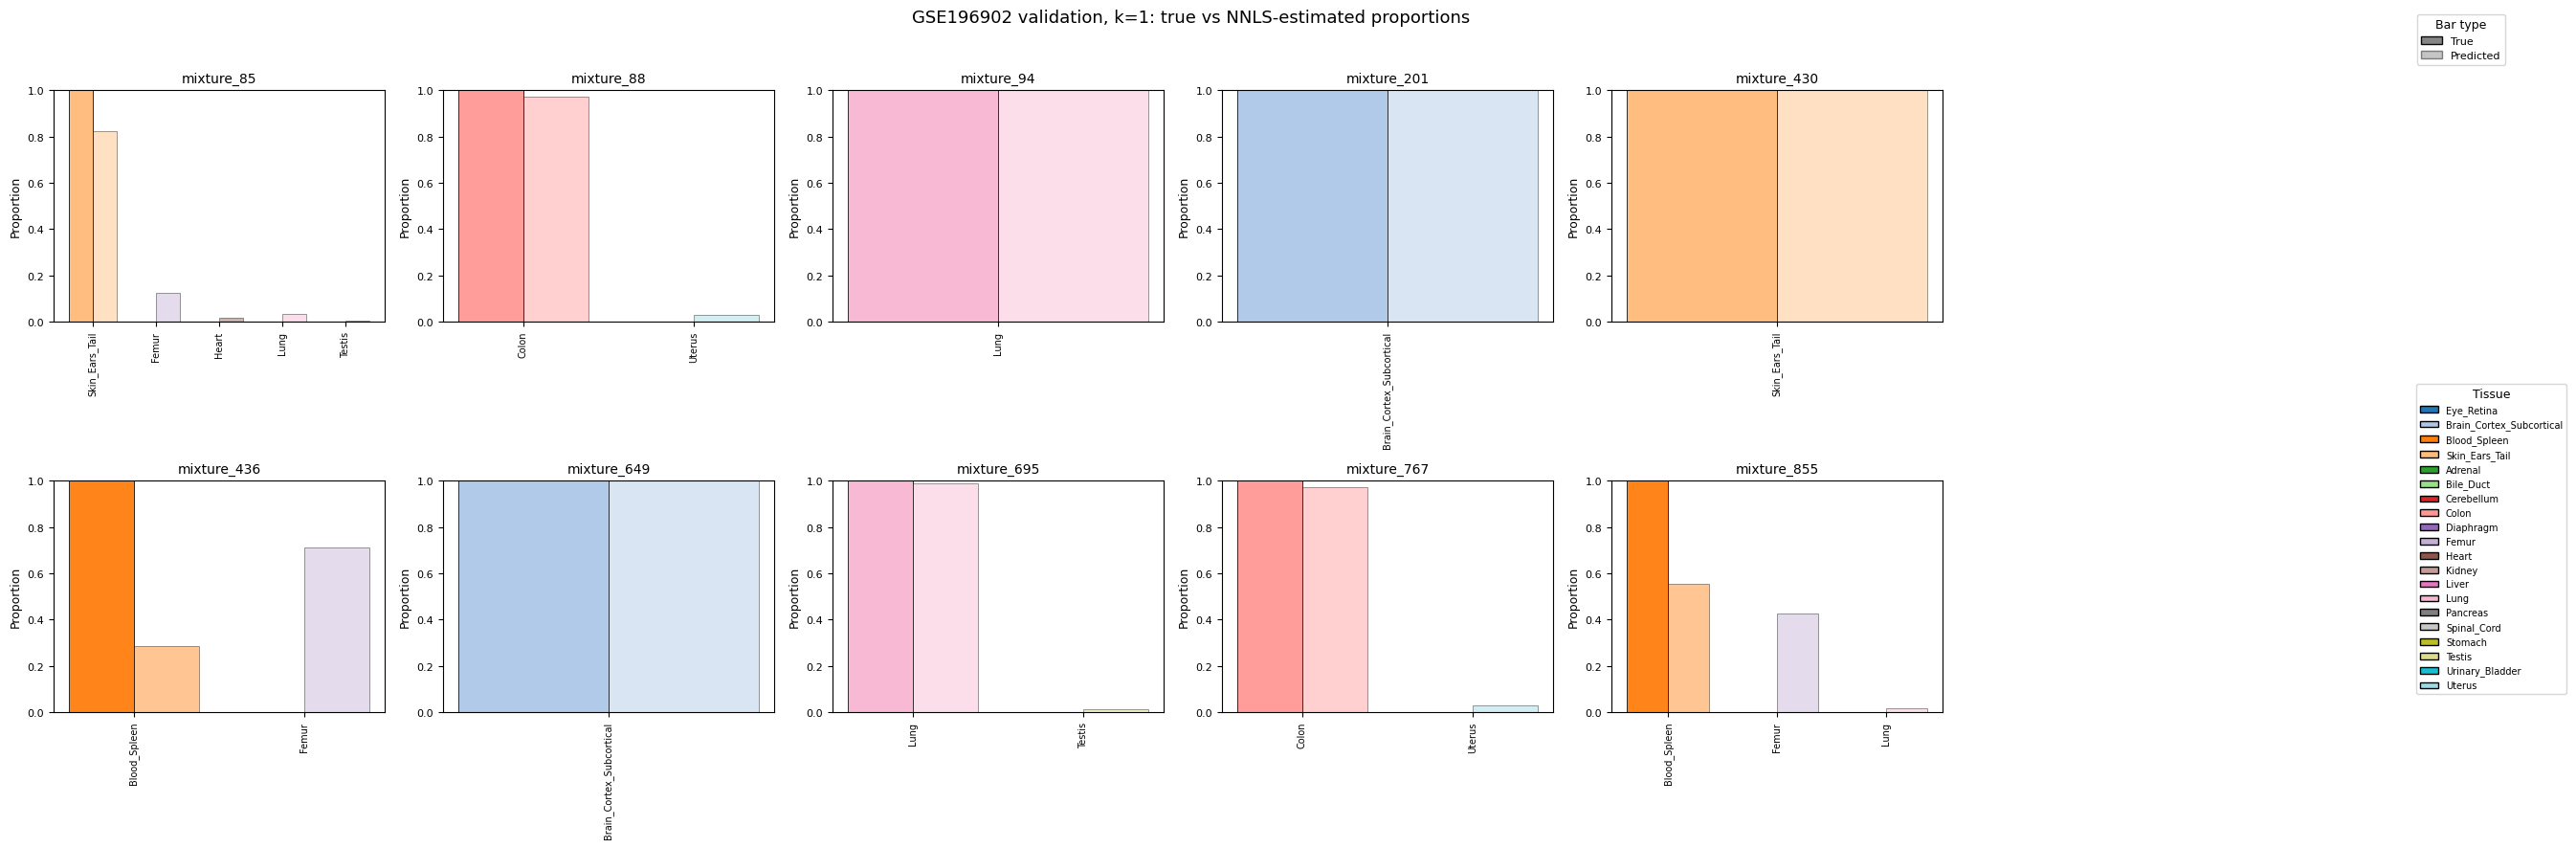

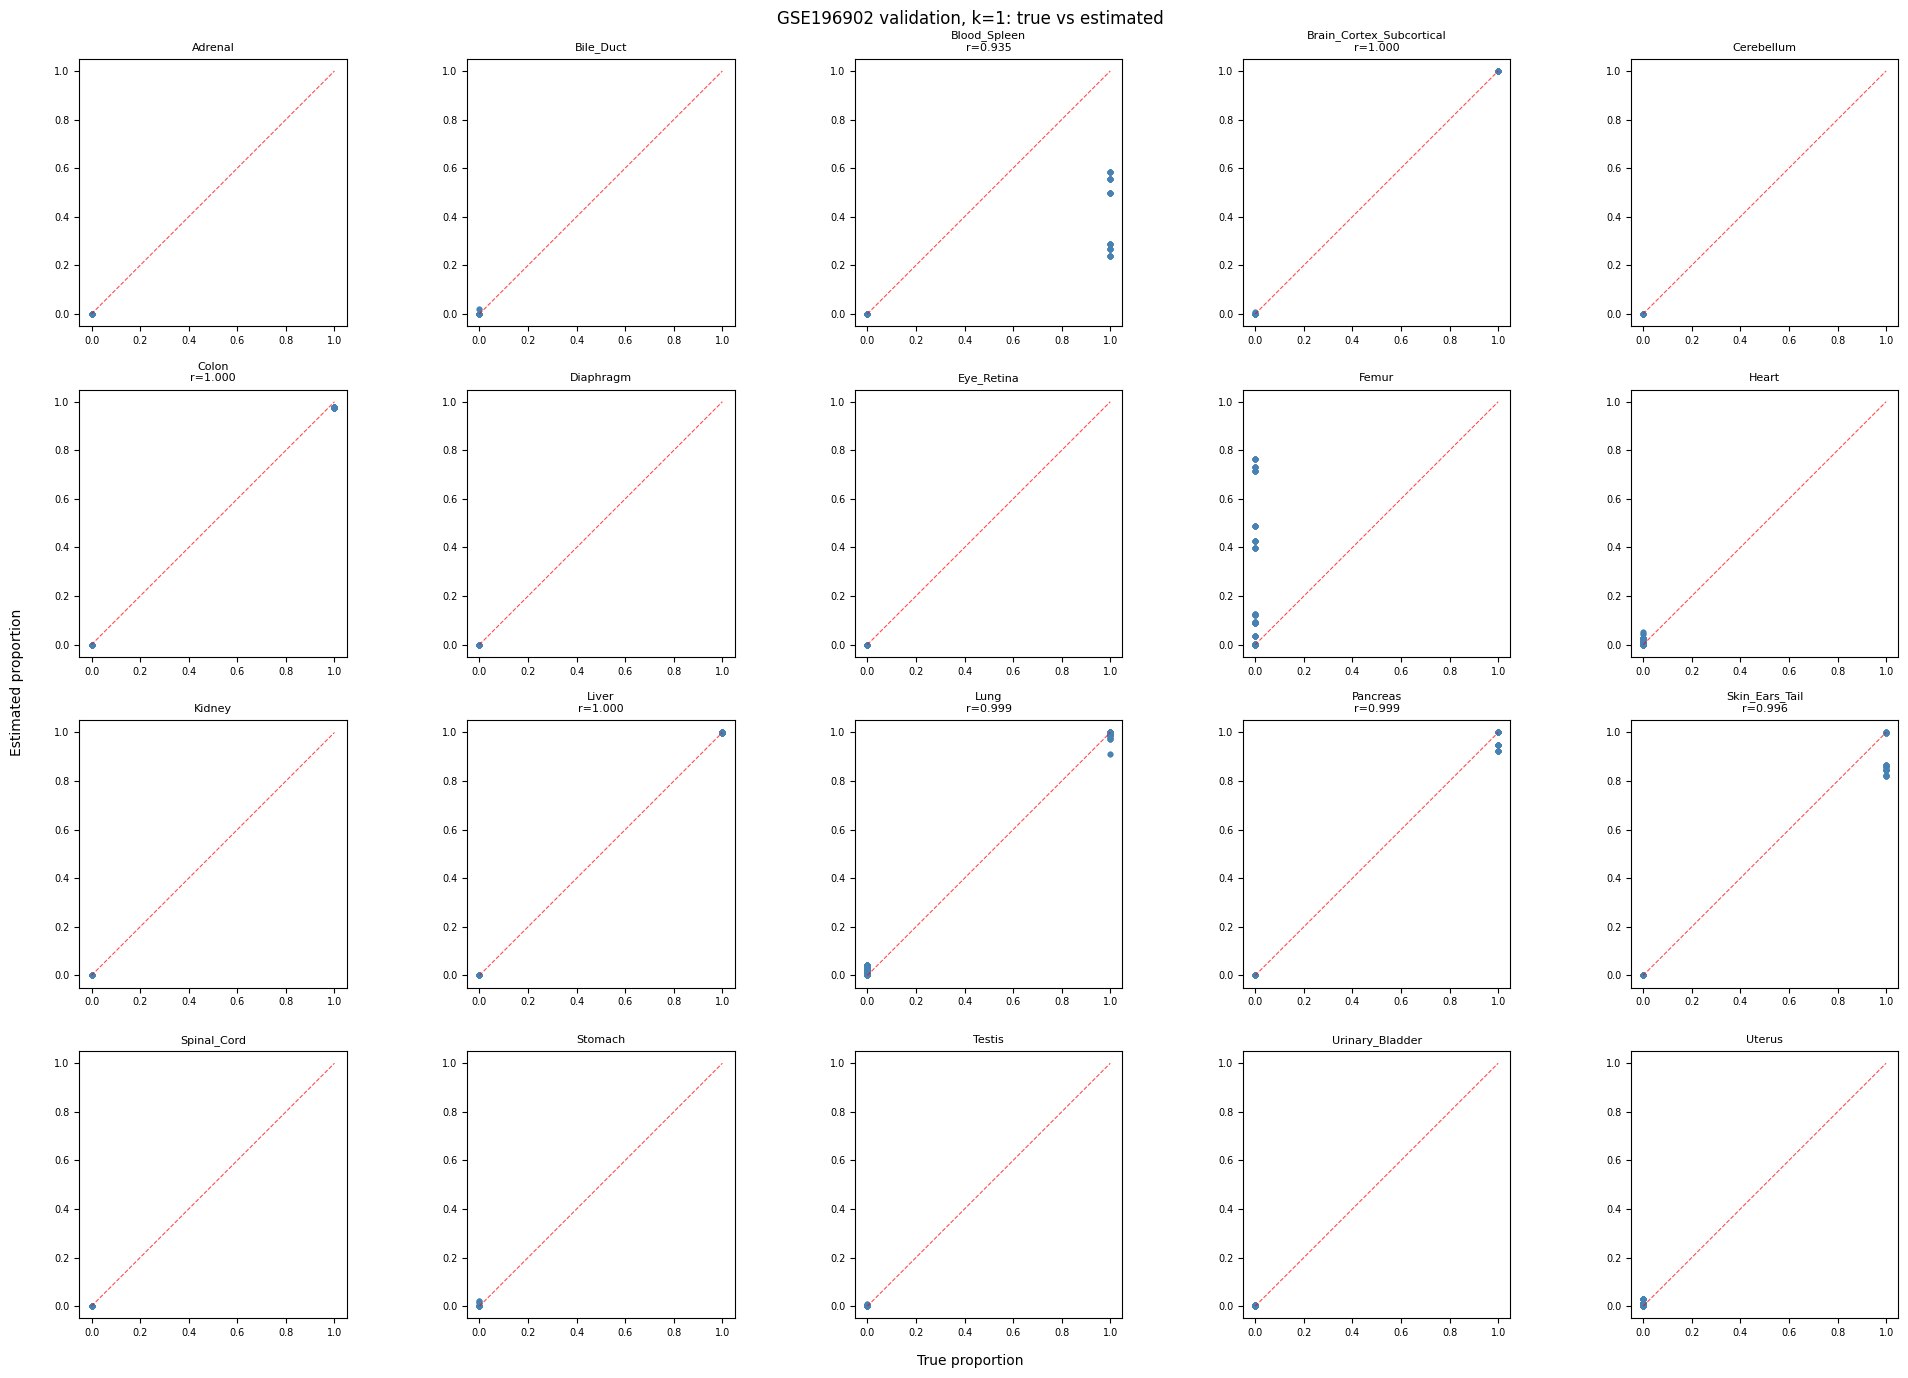

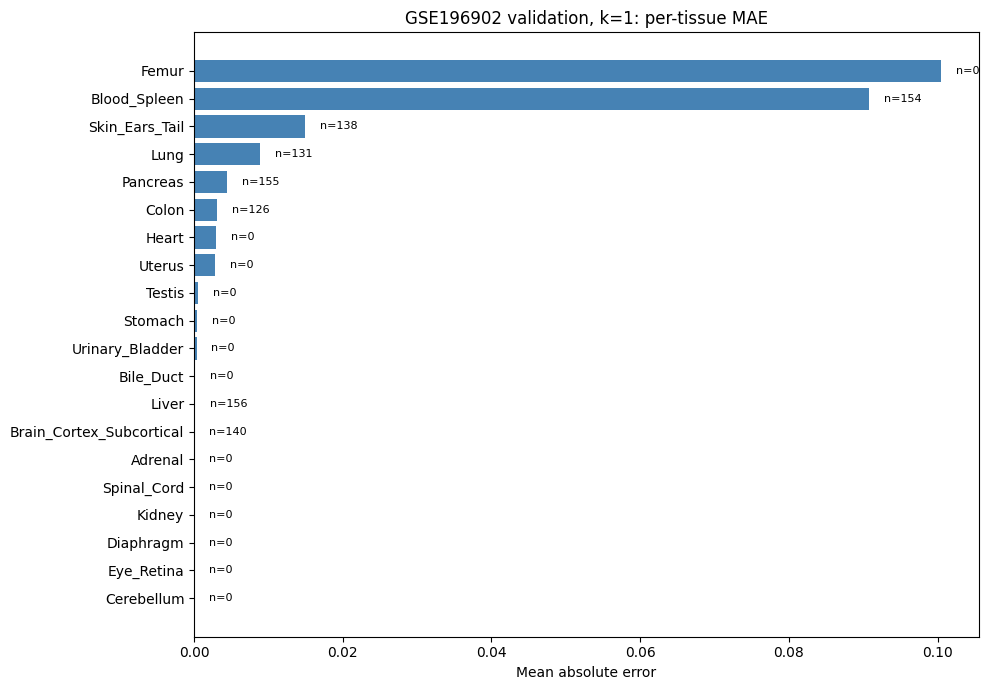

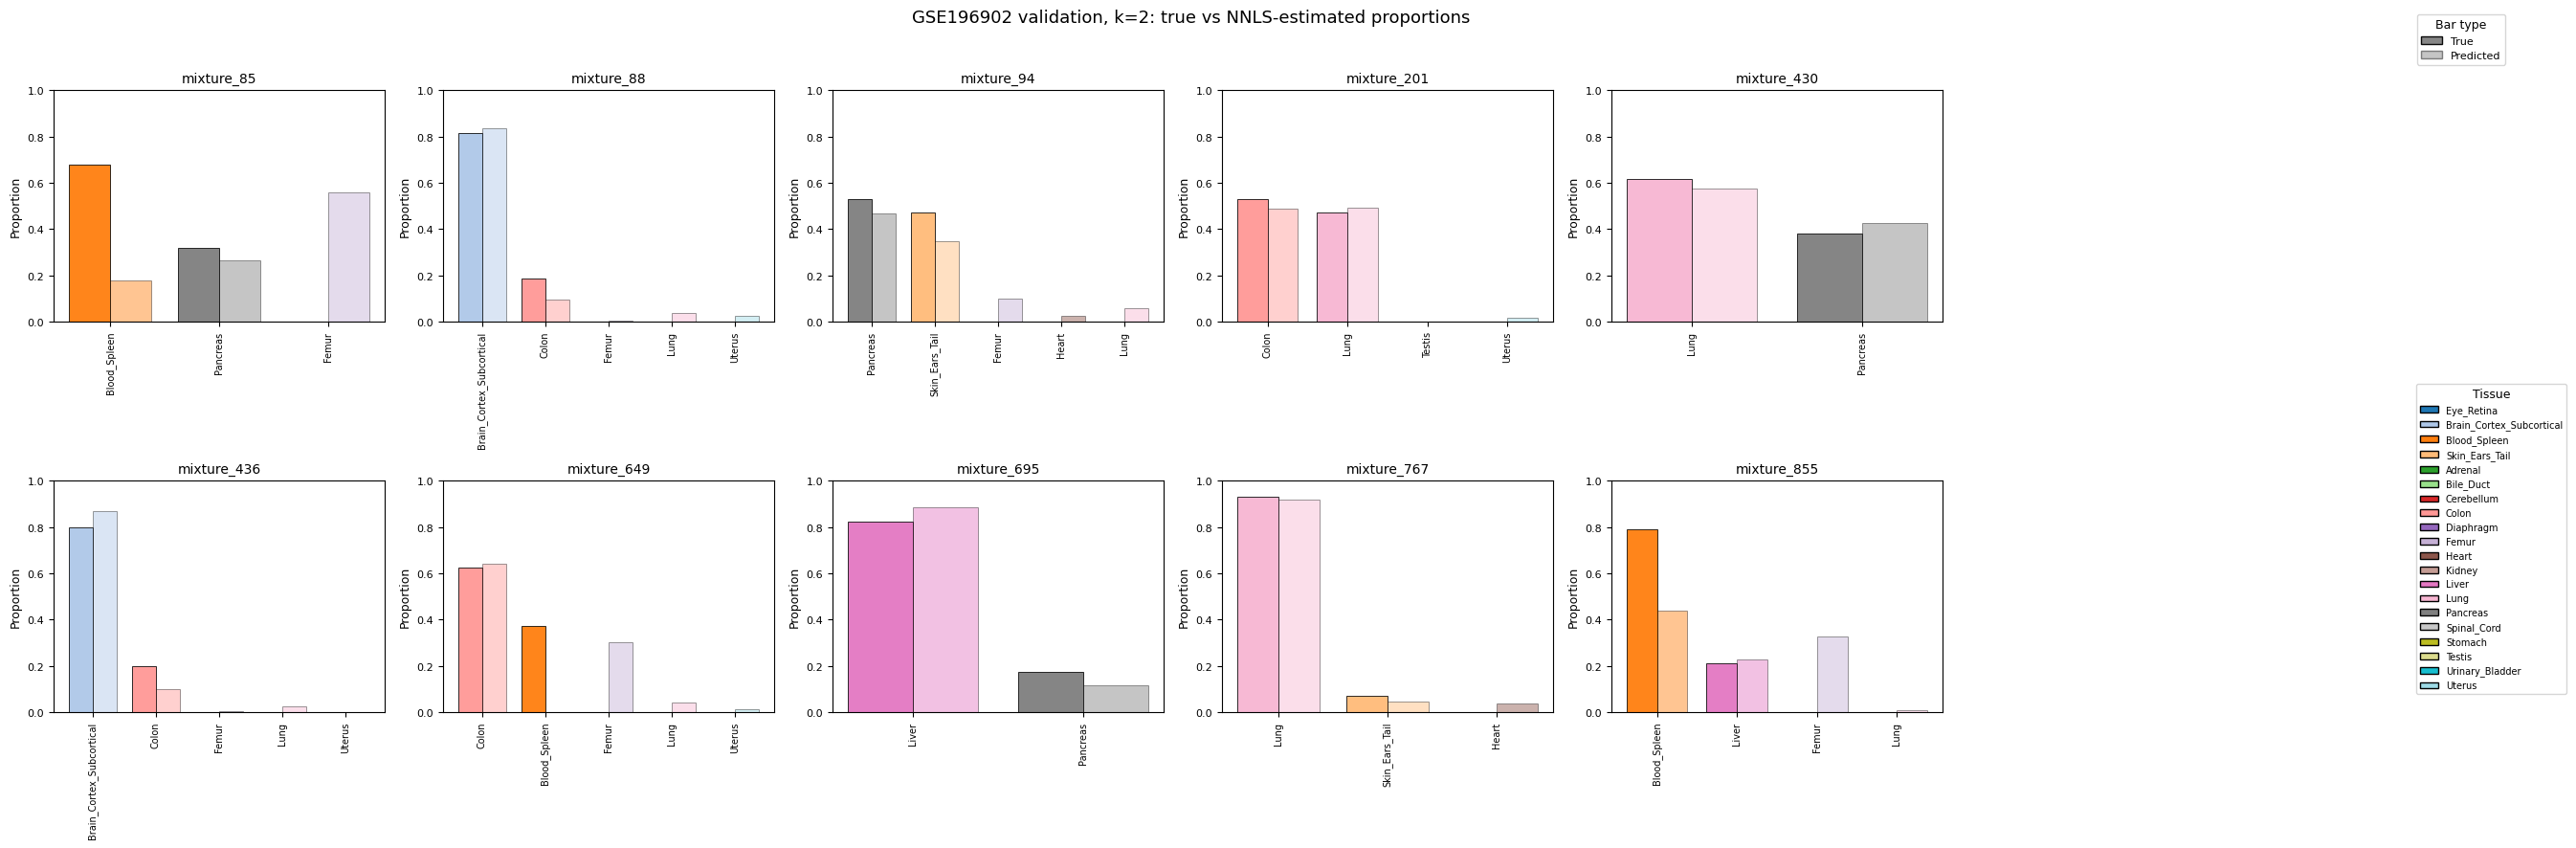

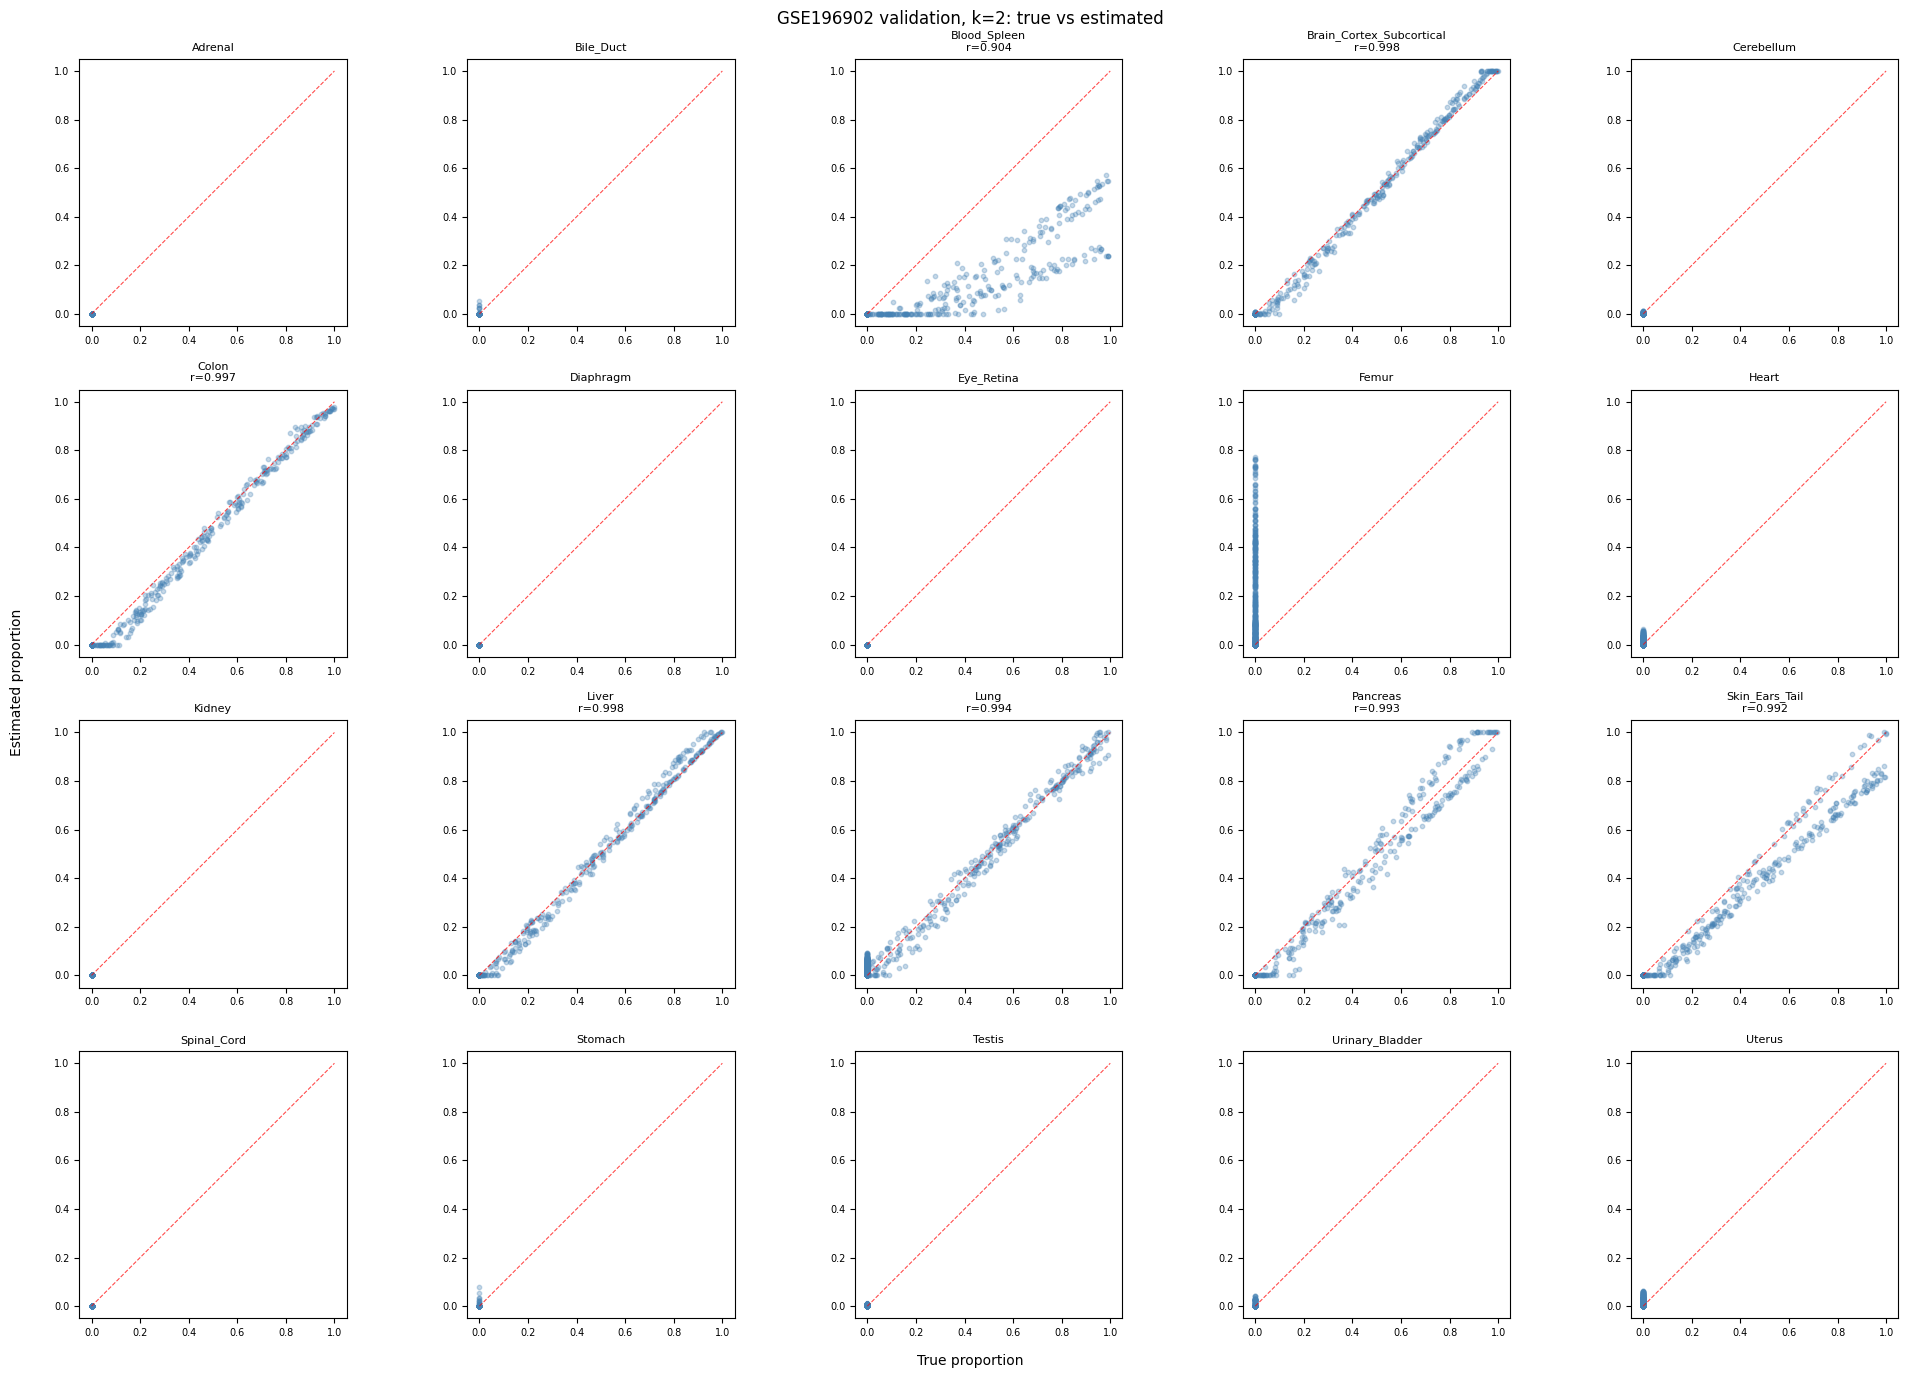

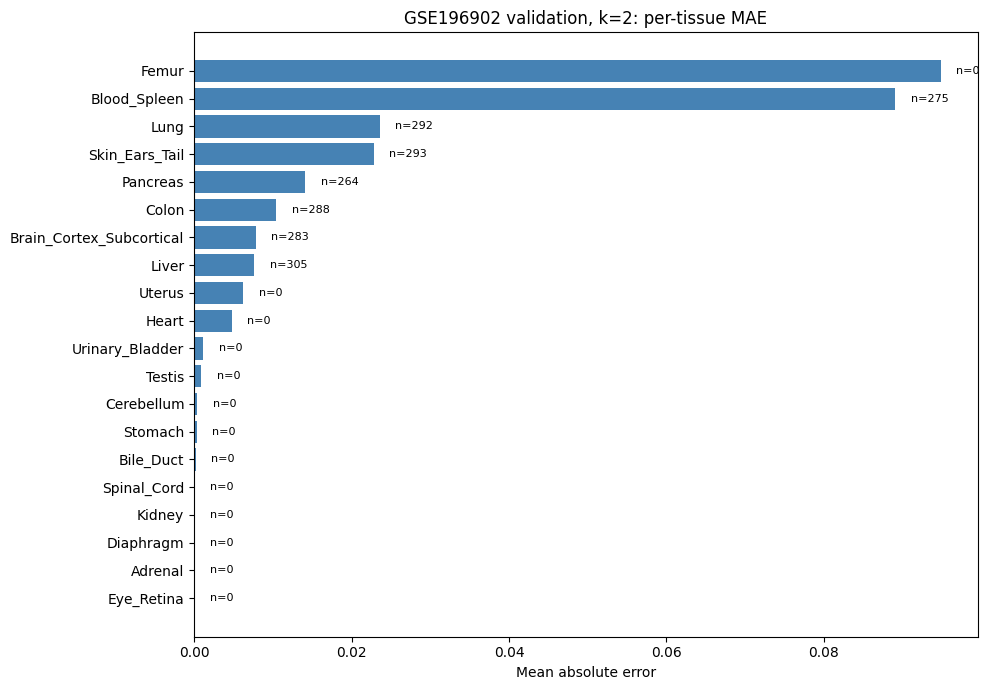

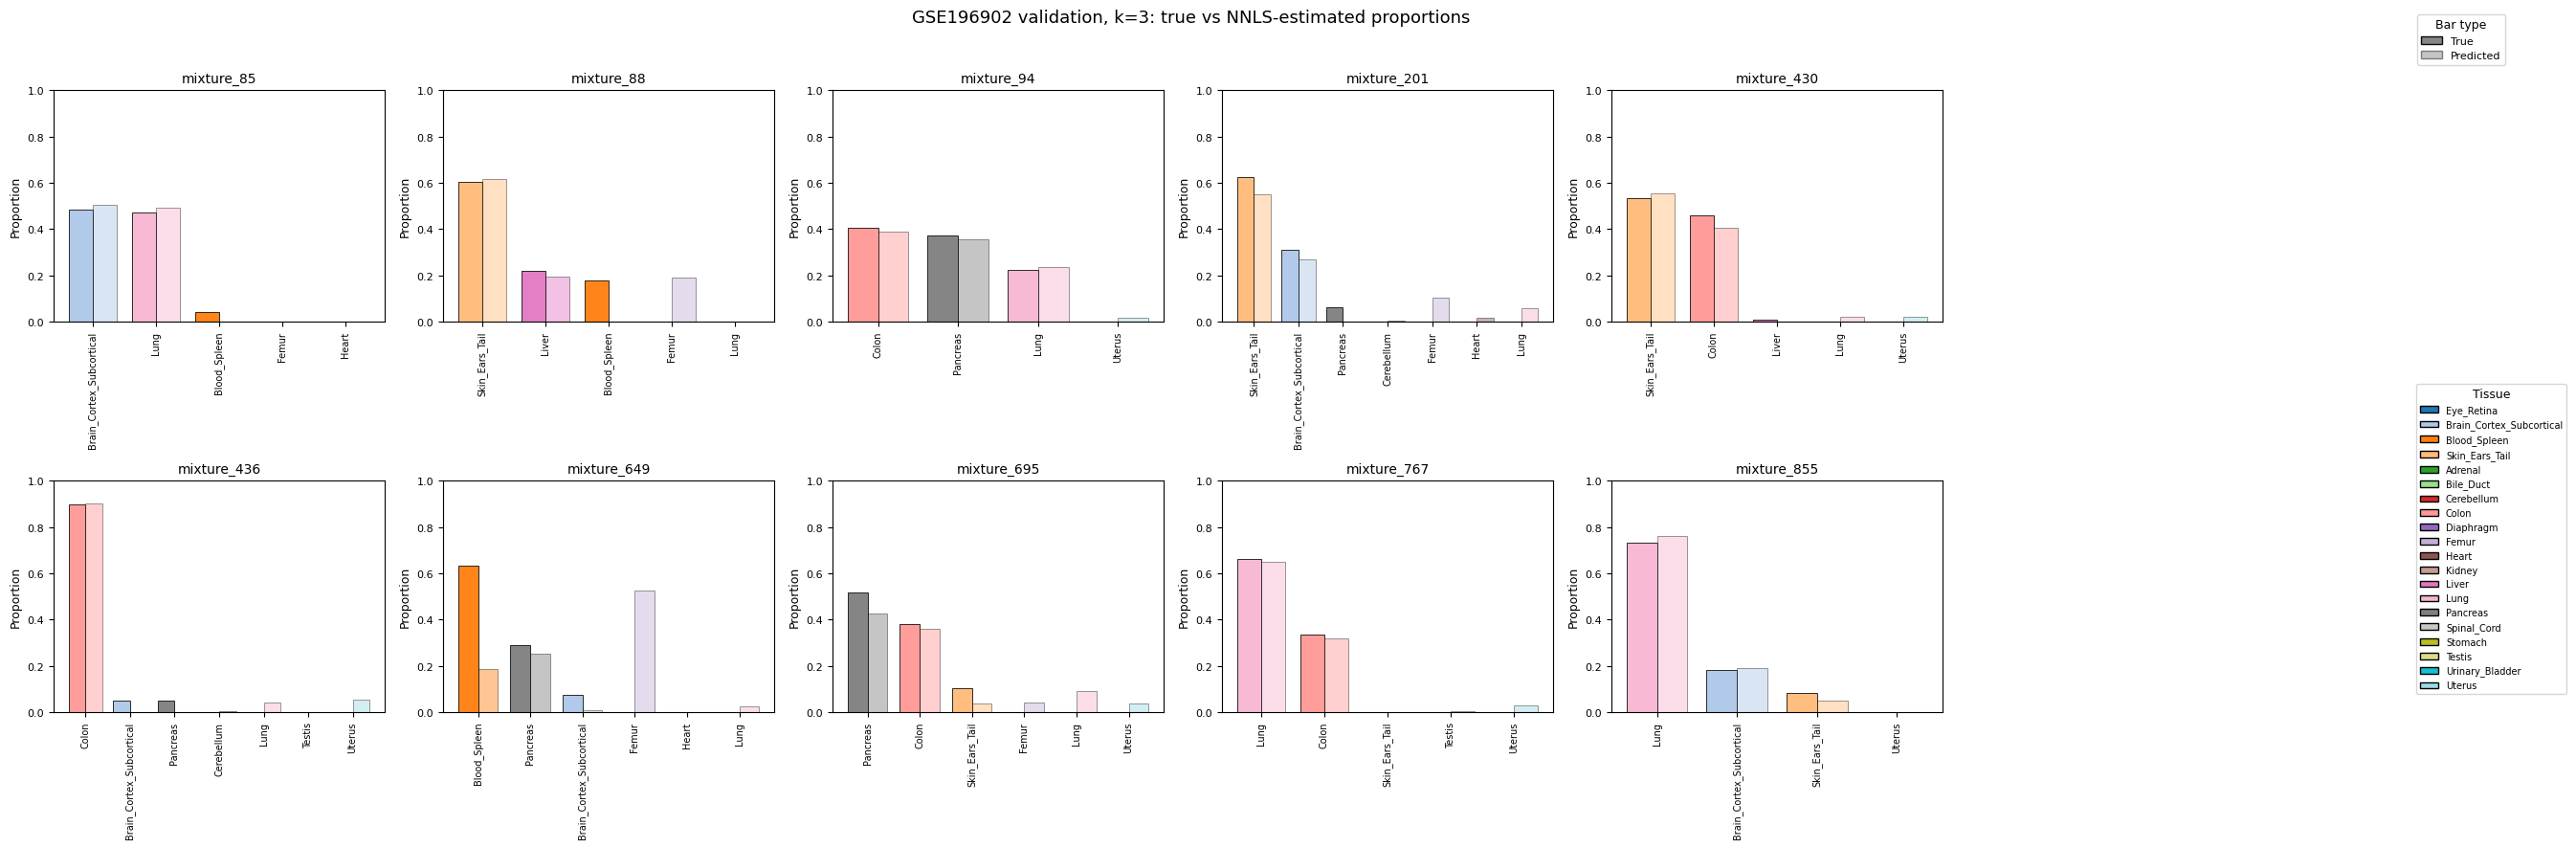

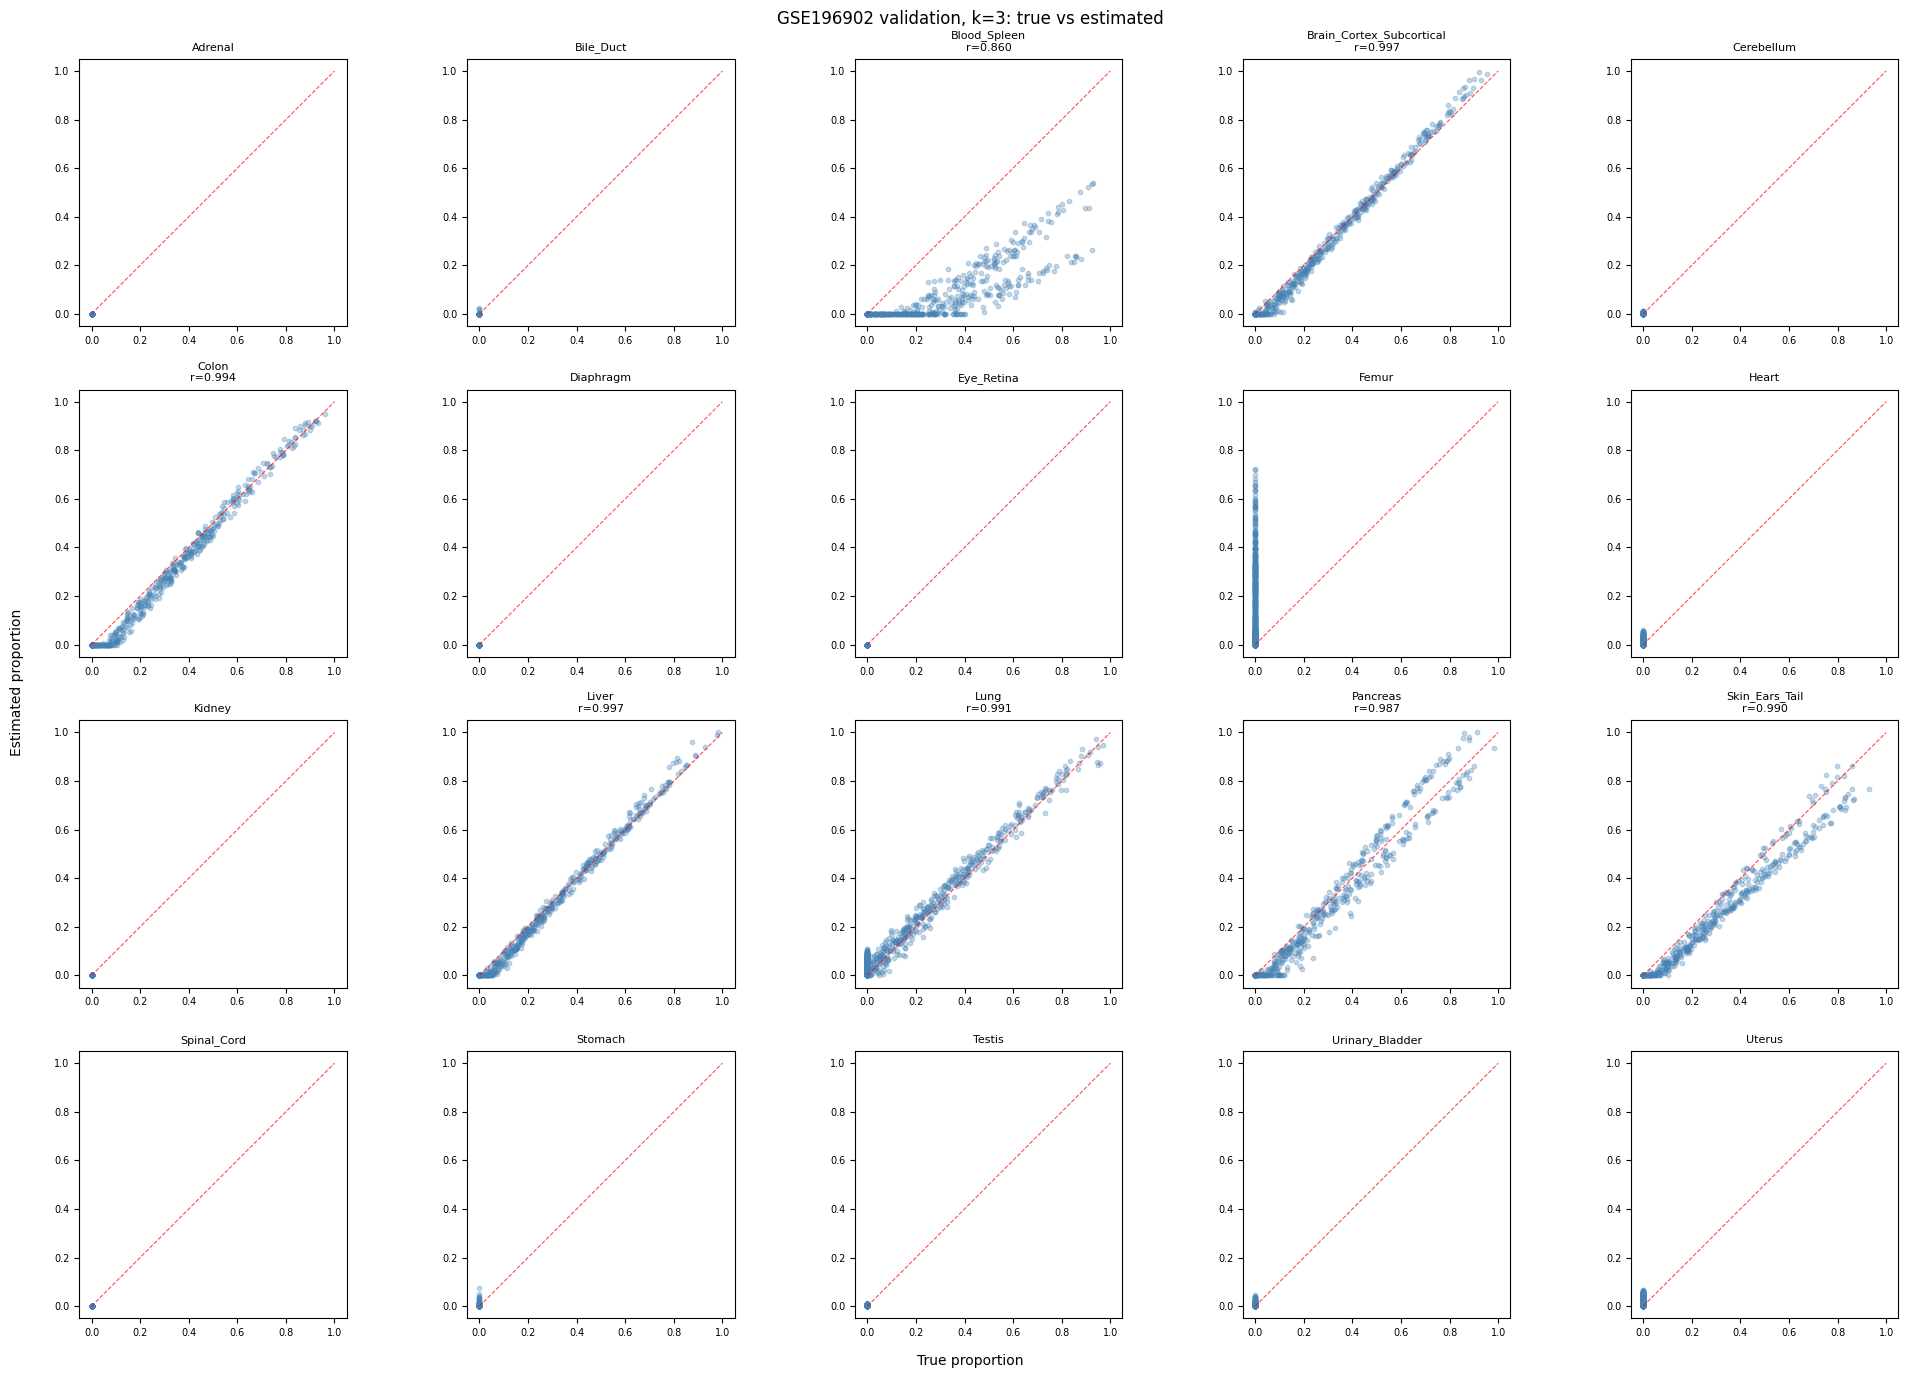

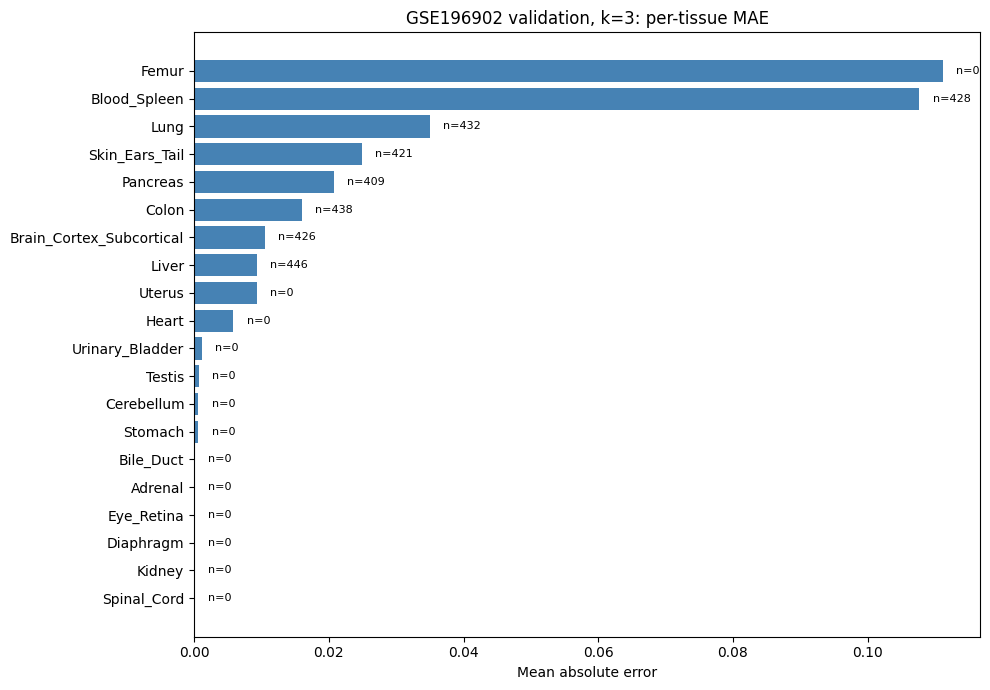

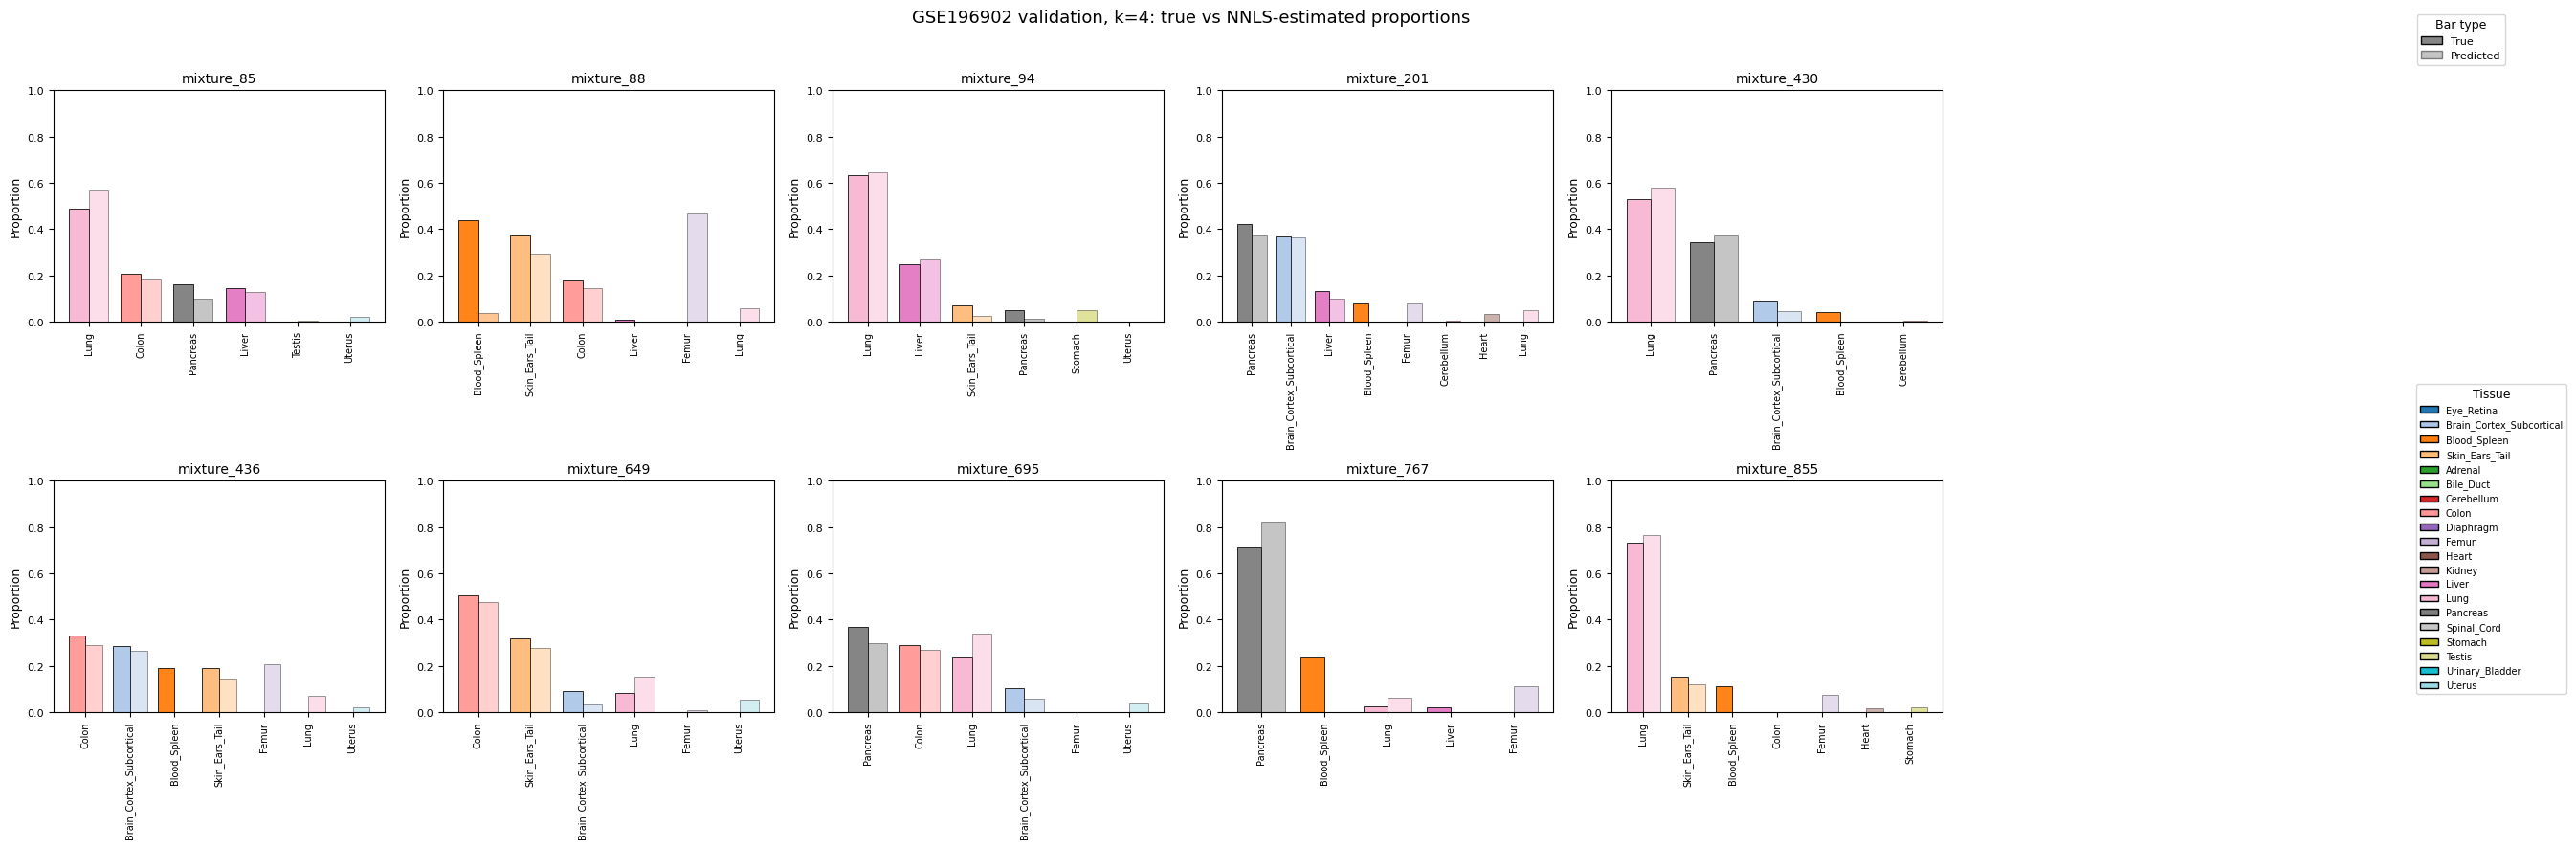

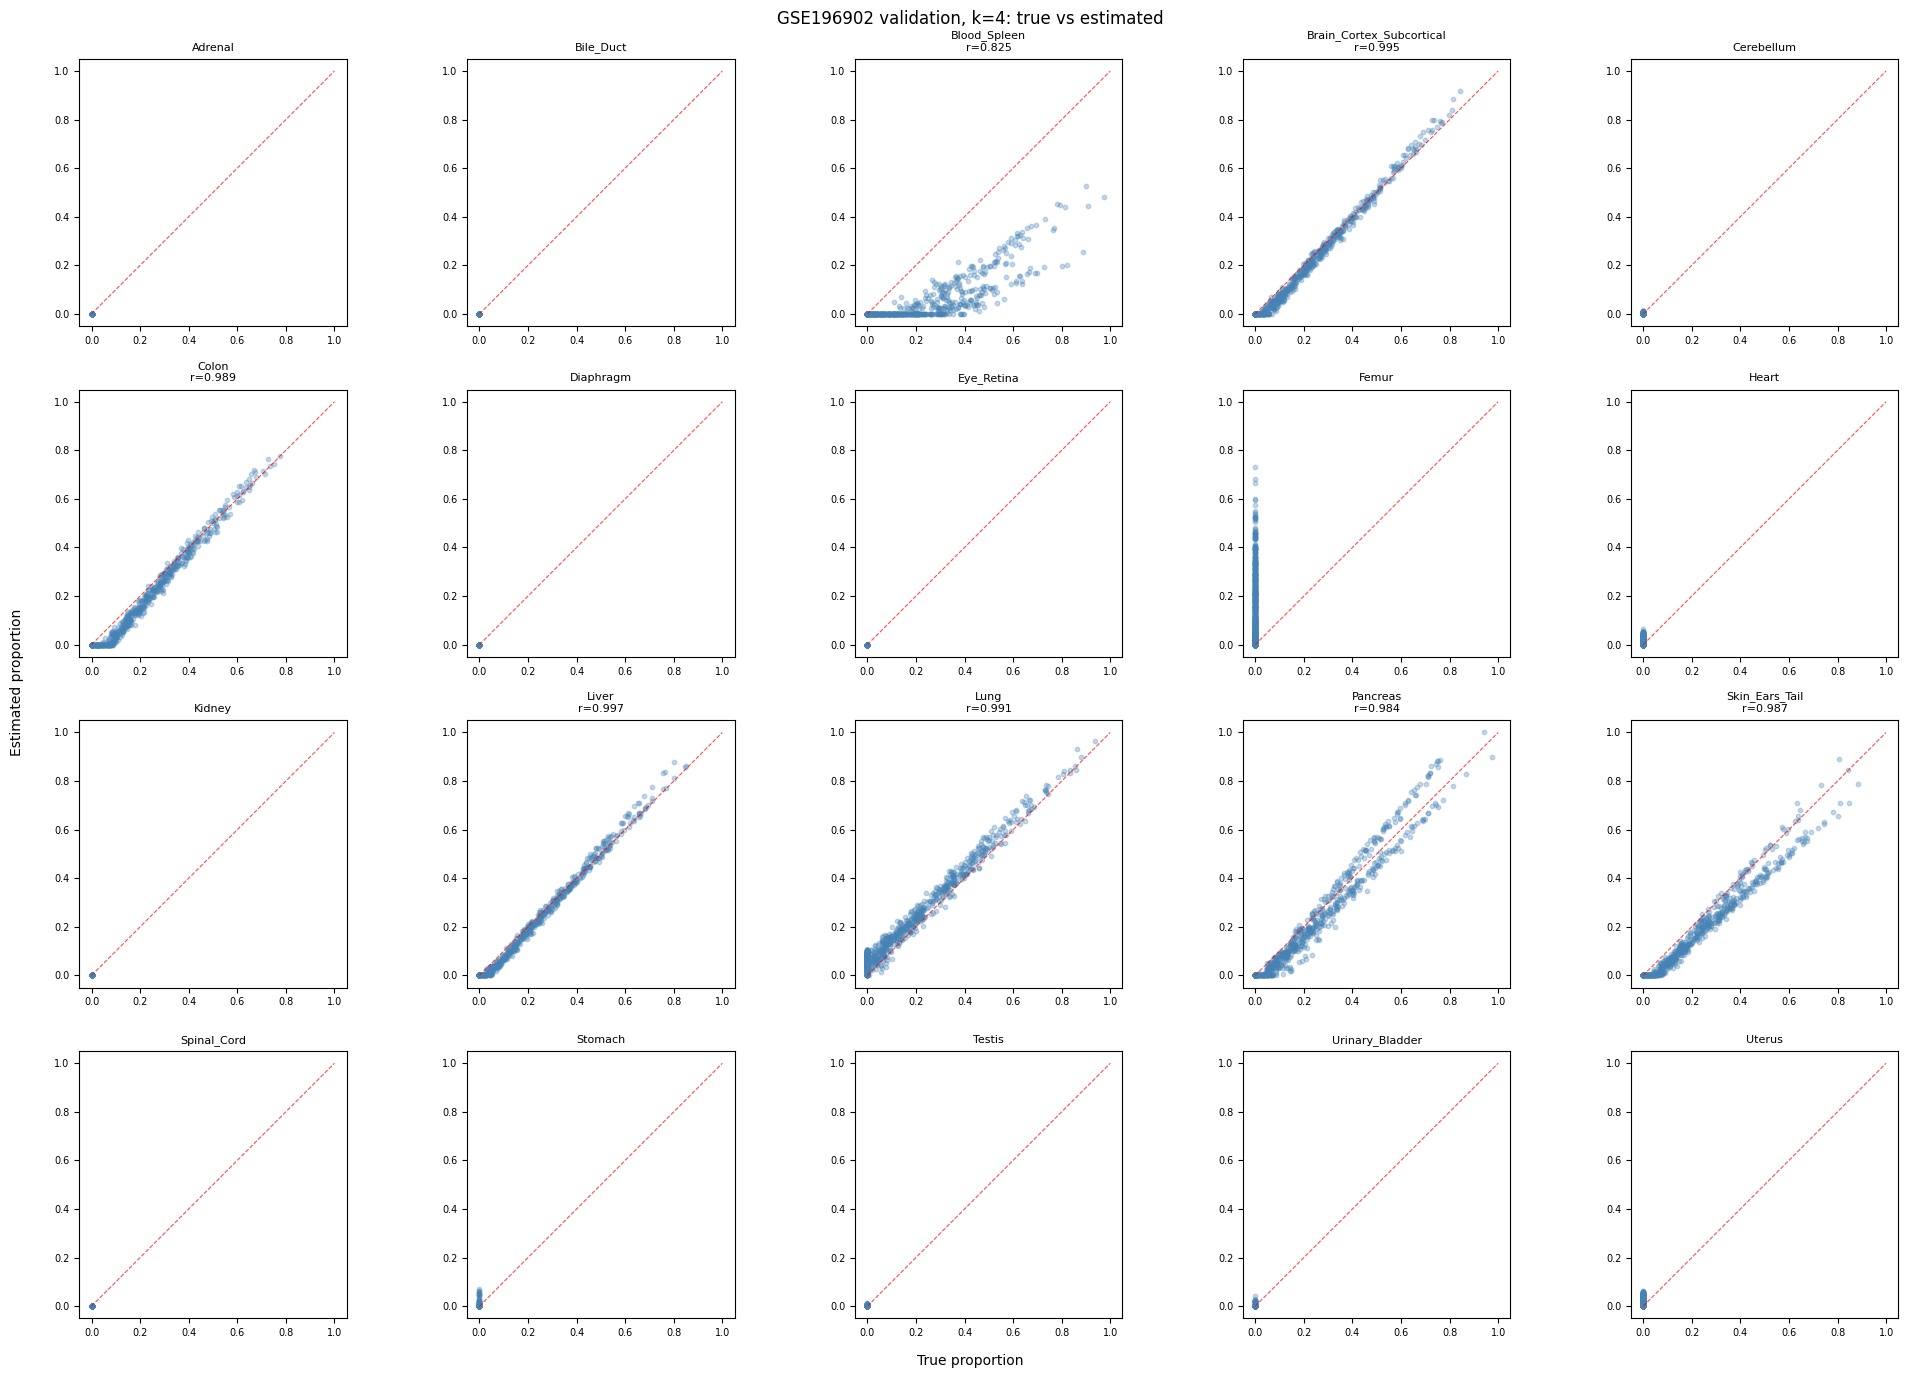

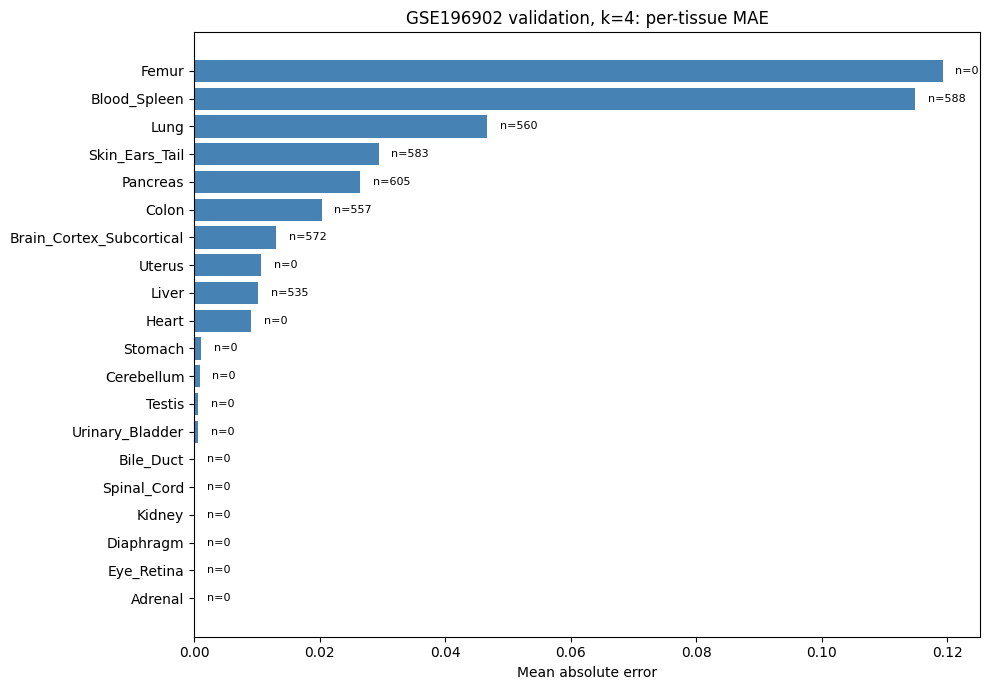

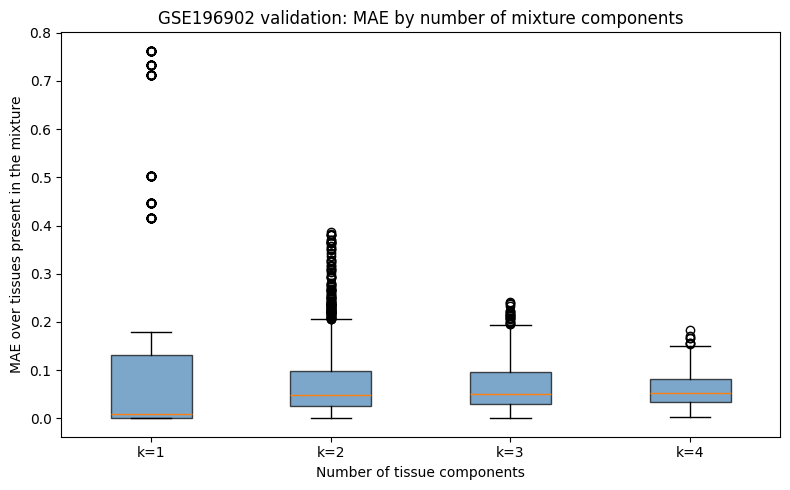

figures -> figures/publication/validation


In [15]:
# ---- Per-k plots ---------------------------------------------------------------
for k, r in results.items():
    ids = deconv_model.select_random_k_mixtures(
        df_proportions=r["true"],
        k_min=k,
        n_plots=config.DECONV_BARPLOT_N_PLOTS,
        random_seed=config.DECONV_BARPLOT_SEED,
    )
    _show_src(
        deconv_model.plot_selected_mixture_barplots,
        df_proportions=r["true"],
        df_estimated=r["est"],
        mixture_ids=ids,
        title=f"GSE196902 validation, k={k}: true vs NNLS-estimated proportions",
        output_path=FIG_DIR / f"k{k}_barplots.{FMT}" if SAVE_FIGURES else None,
        dpi=DPI,
    )
    _show_src(
        deconv_model.plot_true_vs_estimated_scatter,
        r["true"], r["est"],
        title=f"GSE196902 validation, k={k}: true vs estimated",
        output_path=FIG_DIR / f"k{k}_scatter.{FMT}" if SAVE_FIGURES else None,
        dpi=DPI,
    )
    _show_src(
        deconv_model.plot_per_tissue_mae,
        r["tissue"],
        title=f"GSE196902 validation, k={k}: per-tissue MAE",
        output_path=FIG_DIR / f"k{k}_per_tissue_mae.{FMT}" if SAVE_FIGURES else None,
        dpi=DPI,
    )

# MAE vs component count, pooled across k
pooled = pd.concat([r["mixture"] for r in results.values()], ignore_index=True)
_show_src(
    deconv_model.plot_mae_by_components,
    pooled,
    title="GSE196902 validation: MAE by number of mixture components",
    output_path=FIG_DIR / f"mae_by_k.{FMT}" if SAVE_FIGURES else None,
    dpi=DPI,
)

print(f"figures -> {FIG_DIR.relative_to(config.PROJECT_ROOT)}")

## I.6 Held-out tissues: the unknown-component case

`BM`, `Breast` and `Prostate` have no counterpart in W. Every result below is wrong by
construction; that is the point.

The question is **where NNLS puts the mass** when the true tissue is absent, and whether the
residual is elevated enough to detect that from the output alone. Directly relevant to real
cfDNA, where unknown components are guaranteed and there is no ground truth to check against.

Compare these residuals against the pure-sample residuals from section I.4: if the distributions
overlap, residual alone cannot flag an unknown component.

In [16]:
# ---- Deconvolve the held-out tissues ------------------------------------------
df_heldout = df_val_indexed[heldout_labels.index]
df_heldout_est, heldout_residuals = deconvolve_matrix(df_heldout, W)

heldout = pd.DataFrame({
    "true_tissue": heldout_labels,
    "top_call":    df_heldout_est.idxmax(axis=1),
    "top_value":   df_heldout_est.max(axis=1),
    "residual":    heldout_residuals,
})

print("Where NNLS assigns mass when the true tissue is absent from W:\n")
print(heldout.to_string())

print("\nmean attribution per held-out tissue (top 5 atlas tissues each):")
for lab in sorted(heldout_labels.unique()):
    cols = heldout_labels[heldout_labels == lab].index
    mean_props = df_heldout_est.loc[cols].mean().sort_values(ascending=False)
    top = ", ".join(f"{t} {v:.2f}" for t, v in mean_props.head(5).items())
    print(f"  {lab:<10} (n={len(cols)}): {top}")

print("\nresidual comparison — can residual alone flag an unknown component?")
print(f"  pure samples (tissue IS in W):    median {pure_residuals.median():.4f}  "
      f"[{pure_residuals.min():.4f}, {pure_residuals.max():.4f}]")
print(f"  held out    (tissue NOT in W):    median {heldout_residuals.median():.4f}  "
      f"[{heldout_residuals.min():.4f}, {heldout_residuals.max():.4f}]")
overlap = heldout_residuals.min() < pure_residuals.max()
print(f"  distributions overlap: {overlap}"
      + ("  -> residual alone is NOT a reliable flag" if overlap
         else "  -> residual separates the two cleanly"))

Deconvolved 17 mixtures
  Mean residual: 2.7823
  Max residual:  3.7541
Where NNLS assigns mass when the true tissue is absent from W:

           true_tissue         top_call  top_value  residual
BM                  BM            Femur   0.998589  1.247521
BM.1                BM            Femur   1.000000  1.252611
Breast          Breast   Skin_Ears_Tail   0.317091  2.692113
Breast.1        Breast        Diaphragm   0.301531  1.780703
Breast.2        Breast            Heart   0.236704  1.814788
Breast.3        Breast            Heart   0.229592  2.507610
Prostate      Prostate  Urinary_Bladder   0.335691  3.000788
Prostate.1    Prostate  Urinary_Bladder   0.361671  3.157007
Prostate.2    Prostate  Urinary_Bladder   0.271704  2.993006
Prostate.3    Prostate  Urinary_Bladder   0.314520  2.872187
Thymus          Thymus     Blood_Spleen   0.668612  3.436624
Thymus.1        Thymus     Blood_Spleen   0.680564  3.470100
Thymus.2        Thymus     Blood_Spleen   0.680480  3.754061
Thymus.3  

## I.7 Sensitivity in an 85 % blood background

A **limit of detection**: the smallest proportion at which a tissue that really is present
gets recovered. This is a *per-component* question: every `(tissue, p_true, p_est)` triple is
pooled and scored, rather than aggregated per mixture.

Each point on a detection curve **is** one entry of `SPIKE_LEVELS_BLOOD`: for every
`(k, target, level)` the sweep builds `N_PER_CELL` mixtures with the target held at exactly
that level, deconvolves them, and records the fraction where `p_est > ε`. So the ladder runs
in 1 % steps from 1 % to 14 %, giving one data point per percentage tick.

Two failure modes, measured together:

| | | |
|---|---|---|
| **Dropout** | tissue present at low % → estimated ≈ 0 | `P(p_est > ε \| p_true = x)` |
| **Hallucination** | tissue truly absent → given non-zero mass | `P(p_est > ε \| p_true = 0)` |

They trade off: any ε that flatters detection also inflates false positives, so both are
reported at every threshold. The tissues that can never appear in a mixture act as a built-in
negative control for the hallucination rate.

cfDNA is dominated by blood, and a dominant component changes the problem: the non-blood tissues
have to be found inside a small remainder, and blood's own signature leaks onto its collinear
neighbours. Blood is therefore fixed at exactly **85 %** of every mixture, the same level as
Scenario A/B in Part II.

**Where blood comes from.** GSE196902 has no whole blood (its `Blood_Spleen` material is spleen
only), so blood is always drawn from the **GSE290585 pool half**, for both cohorts. The target and
the other non-blood tissues come from the cohort being tested.

**Which W.** Because blood comes from the pool half, W must be built from the **reference half
only**: `W_ref`, from the split below. The probe panel is also selected from the reference half
only, so pool samples never influence which probes exist. The full-atlas W of section I.1 contains
those pool replicates, which would be leakage. Both cohorts use the same `W_ref`, restricted to the
probes that are non-NaN in the GSE196902 samples used, so the two cohorts share one W and one probe
list and **are directly comparable**.

**Geometry.** Blood takes 85 %, so the target and the other k−1 non-blood tissues share the
remaining 15 %. A one-tissue mixture (k = 1) can only sit at exactly 15 %, so the ladder runs
1–14 % and k = 2, 3, 4 non-blood tissues (target included). `Blood_Spleen` is the background, not
a target, which leaves six targets: Brain, Colon, Liver, Lung, Pancreas, Skin.

In [17]:
# ---- Detection settings --------------------------------------------------------
N_PER_CELL   = 200                      # detection trials per (k, target, level)
EPSILONS     = [0.005, 0.01, 0.02]      # detection thresholds; 0.02 matches deconv_regimes
eps_main     = EPSILONS[-1]             # the one used for headline tables and plots
LOD_TARGET   = 0.80                     # detection rate defining the limit of detection
FPR_BUDGET   = 0.05                     # for the calibrated-threshold view

In [18]:
# ---- Sensitivity plot helpers ---------------------------------------------------
# No existing function in deconv_model covers a detection curve.
#
# All axes are linear percentages: the spike ladder is evenly spaced in absolute terms,
# so a log axis would only distort it.

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

def _pct_axis(ax, levels, minor=1, major=2):
    """Linear percentage x-axis over the spike ladder, one tick per percentage."""
    lo, hi = min(levels) * 100, max(levels) * 100
    ax.set_xlim(lo - 0.5, hi + 0.5)
    ax.xaxis.set_major_locator(MultipleLocator(major))
    ax.xaxis.set_minor_locator(MultipleLocator(minor))


def _finish(fig, output_path, dpi):
    """Show inline, then save and close, or close without saving. Headless-safe."""
    display(fig)
    if SAVE_FIGURES and output_path is not None:
        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(output_path, dpi=dpi, bbox_inches="tight")
        print(f"saved -> {Path(output_path).relative_to(config.PROJECT_ROOT)}")
    plt.close(fig)


print("plot helpers defined (linear percentage axes)")

plot helpers defined (linear percentage axes)


In [19]:
# ---- Reporting and LOD as reusable functions ------------------------------------
# Parameterised so the identical analysis runs on both cohorts.

import contextlib, io, zlib


def stable_seed(*parts) -> int:
    """Deterministic seed from any tuple of values.

    Deliberately NOT hash() - Python randomises string hashing per process, so seeds
    derived from hash() differ between kernel restarts. crc32 is stable across processes.
    """
    return zlib.crc32("|".join(map(str, parts)).encode()) % (2**31)

def compute_lod(levels, rates, threshold: float = None) -> float:
    """
    Smallest proportion at which detection reaches `threshold`, linearly interpolated
    between the two bracketing spike levels. NaN if the curve never gets there.
    """
    threshold = LOD_TARGET if threshold is None else threshold
    levels = np.asarray(levels, dtype=float)
    rates  = np.asarray(rates,  dtype=float)
    order  = np.argsort(levels)
    levels, rates = levels[order], rates[order]

    if rates[-1] < threshold:
        return np.nan                       # never reaches the threshold
    if rates[0] >= threshold:
        return levels[0]                    # already above it at the lowest level tested

    i = int(np.argmax(rates >= threshold))  # first index at or above threshold
    x0, x1, y0, y1 = levels[i-1], levels[i], rates[i-1], rates[i]
    return x1 if y1 == y0 else x0 + (threshold - y0) * (x1 - x0) / (y1 - y0)


def lod_table(df, rate_col):
    """LOD per (target, k) as a tissues x k frame."""
    out = {}
    for (tgt, k), g in df.groupby(["target", "k"]):
        out[(tgt, k)] = compute_lod(g["level"].to_numpy(), g[rate_col].to_numpy())
    s = pd.Series(out)
    s.index = pd.MultiIndex.from_tuples(s.index, names=["target", "k"])
    return s.unstack("k")


def report_spike_results(res, never_present, label):
    """Detection table, hallucination floor, LOD at fixed and calibrated thresholds."""
    df_sens = res["df_sens"]
    print("=" * 72); print(f"{label}"); print("=" * 72)

    piv = df_sens.pivot_table(index="level", columns="k", values=f"det_{eps_main}")
    print(f"\nDetection rate  P(p_est > {eps_main} | p_true = level), pooled over targets\n")
    print((piv * 100).round(1).to_string())

    fpr = df_sens.groupby("k")[[f"fpr_{e}" for e in EPSILONS]].mean()
    print(f"\n\nFalse-positive rate on the {len(never_present)} never-present tissues:")
    print((fpr * 100).round(2).to_string())

    # The curve has a FLOOR equal to the hallucination rate: below the point where a tissue is
    # genuinely detectable, "detections" are absent-tissue noise clearing the threshold.
    # Monotonicity only means anything above that floor.
    floor = fpr[f"fpr_{eps_main}"]
    lo = df_sens["level"].min()
    print(f"\n\nFloor check — detection at the smallest spike ({lo:.0%}) vs the "
          f"hallucination rate:")
    for k in piv.columns:
        d = piv.loc[lo, k]
        print(f"  k={k}:  detection {d*100:5.1f}%   |   FPR {floor[k]*100:5.1f}%   -> "
              f"{'indistinguishable from noise' if d <= floor[k] * 1.5 else 'above the floor'}")

    print("\nMonotonicity above the floor (a violation there implicates the generator):")
    for k in piv.columns:
        above = piv[k][piv[k] > floor[k] * 1.5]
        print(f"  k={k}: {'OK' if above.is_monotonic_increasing else 'VIOLATED'}  "
              f"({len(above)}/{len(piv)} levels above floor)")

    lod = lod_table(df_sens, f"det_{eps_main}")
    print(f"\n\nLimit of detection at a FIXED threshold (eps = {eps_main})")
    print(f"smallest proportion detected in >= {LOD_TARGET:.0%} of mixtures; NaN = never reached\n")
    print((lod * 100).round(2).to_string())
    print("\nmedian LOD across tissues, by k:")
    print((lod.median() * 100).round(2).to_string())

    # A tissue already "detected" at the SMALLEST spike is not being detected; it is absorbing
    # mass belonging to other tissues. Its LOD is an artifact.
    sink = df_sens[df_sens["level"] == lo].pivot_table(
        index="target", columns="k", values=f"det_{eps_main}")
    print(f"\n\nSink check — detection at the smallest spike ({lo:.0%}):\n")
    print((sink * 100).round(1).to_string())
    flagged = sink.max(axis=1)[sink.max(axis=1) > 0.5].index.tolist()
    print(f"\nWARNING mass sinks — LOD is NOT interpretable for: {flagged}"
          if flagged else "\nno mass sinks flagged")

    # A fixed eps is not comparable across k, because the hallucination rate itself grows with
    # k. Calibrating eps per k to a fixed false-positive budget holds that constant.
    eps_cal = {k: float(np.quantile(v, 1 - FPR_BUDGET))
               for k, v in res["spike_absent"].items()}
    print(f"\n\nCalibrated thresholds ({FPR_BUDGET:.0%} false-positive budget):")
    for k, e in eps_cal.items():
        print(f"  k={k}: eps = {e:.4f}   (fixed: {eps_main})")

    raw = res["df_raw"].copy()
    raw["det_cal"] = [pe > eps_cal[k] for k, pe in zip(raw["k"], raw["p_est"])]
    df_cal = (raw.groupby(["target", "k", "p_true"])["det_cal"].mean()
              .reset_index().rename(columns={"p_true": "level"}))
    lod_cal = lod_table(df_cal, "det_cal")
    print(f"\nLOD at a {FPR_BUDGET:.0%} FPR budget (%):")
    print((lod_cal * 100).round(2).to_string())

    return lod, lod_cal


print("reporting functions defined")

reporting functions defined


In [20]:
# ---- Reference / pool split of the atlas ------------------------------------------
atlas_label_map = build_label_map(data_loading.MERGE_GROUPS)

reference_cols, pool_cols = deconv_data.split_reference_pool(
    atlas_labels,
    reference_fraction=config.DECONV_REFERENCE_FRACTION,
    random_state=config.DECONV_SPLIT_SEED,
)
assert not (set(reference_cols) & set(pool_cols)), "reference and pool overlap — leakage!"

# Centroids AND probe panel from the reference half only. Selecting probes on the full atlas
# would let pool samples influence which probes exist, which is leakage even though W's
# values would come only from the reference half.
ref_centroids = build_centroids(
    df_raw=df_atlas_raw, sample_cols=reference_cols,
    original_labels=atlas_labels, merge_groups=data_loading.MERGE_GROUPS,
)
ref_panel = select_probes_from_centroids(ref_centroids, suppress_warnings=True)
W_ref     = ref_centroids.set_index("probe_ID").loc[ref_panel]
atlas_merged = atlas_labels.map(lambda x: atlas_label_map.get(x, x))

print(f"\nreference centroids: {ref_centroids.shape[1] - 1} tissues from {len(reference_cols)} samples")
print(f"reference-only probe panel: {len(ref_panel)} probes")
print(f"  shared with the full-atlas panel: {len(set(ref_panel) & set(W.index))}")
print(f"  unique to the reference panel:    {len(set(ref_panel) - set(W.index))}")
print(f"\nW_ref: {W_ref.shape[0]} probes x {W_ref.shape[1]} tissues")
print(f"condition number: {np.linalg.cond(W_ref.values):.1f}   "
      f"(full-atlas W: {np.linalg.cond(W.values):.1f})")

Reference samples: 116
Pool samples:      124



reference centroids: 20 tissues from 116 samples
reference-only probe panel: 1000 probes
  shared with the full-atlas panel: 852
  unique to the reference panel:    148

W_ref: 1000 probes x 20 tissues
condition number: 95.1   (full-atlas W: 94.6)


In [21]:
# ---- Blood-background sweep configuration -------------------------------------------
BLOOD_TISSUE_SENS  = "Blood_Spleen"
BLOOD_LEVEL_SENS   = 0.85                                        # fixed in every mixture
SPIKE_LEVELS_BLOOD = [round(0.01 * i, 2) for i in range(1, 15)]  # 1%, 2%, ... 14%
K_RANGE_BLOOD      = [2, 3, 4]      # NON-blood tissues per mixture, target included
K_SHOW             = 3              # the k shown in the combined two-cohort figure
TARGETS_BLOOD      = [t for t in atlas_tissues if t != BLOOD_TISSUE_SENS]

# Same identity colours as the recovery map in II.7 (Blues / Oranges).
COHORT_COLOURS = {"GSE290585": "#2171B5", "GSE196902": "#D94801"}

BOTH_BLOOD_PATH = FIG_DIR / f"detection_blood_both.{FMT}"

assert max(SPIKE_LEVELS_BLOOD) < 1 - BLOOD_LEVEL_SENS, \
    "the largest spike must leave room for the other non-blood tissues"
assert len(TARGETS_BLOOD) - 1 >= max(K_RANGE_BLOOD) - 1, "not enough tissues for the largest k"
assert K_SHOW in K_RANGE_BLOOD

print(f"blood fixed at {BLOOD_LEVEL_SENS:.0%}; target ladder {SPIKE_LEVELS_BLOOD[0]:.0%}"
      f"-{SPIKE_LEVELS_BLOOD[-1]:.0%}; k (non-blood) = {K_RANGE_BLOOD}")
print(f"targets ({len(TARGETS_BLOOD)}): {TARGETS_BLOOD}")
print(f"per cohort: {len(K_RANGE_BLOOD)} k x {len(TARGETS_BLOOD)} targets x "
      f"{len(SPIKE_LEVELS_BLOOD)} levels x {N_PER_CELL} = "
      f"{len(K_RANGE_BLOOD) * len(TARGETS_BLOOD) * len(SPIKE_LEVELS_BLOOD) * N_PER_CELL:,} NNLS solves")

blood fixed at 85%; target ladder 1%-14%; k (non-blood) = [2, 3, 4]
targets (6): ['Brain_Cortex_Subcortical', 'Colon', 'Liver', 'Lung', 'Pancreas', 'Skin_Ears_Tail']
per cohort: 3 k x 6 targets x 14 levels x 200 = 50,400 NNLS solves


In [22]:
# ---- Shared W and lookups for the blood sweep ----------------------------------------
# One W and one probe list for BOTH cohorts: the reference-half W_ref from the split above, restricted
# to panel probes that exist in GSE196902 and are non-NaN in the GSE196902 samples actually mixed.
# Mirrors the SHARED list in II.2.

val_target_labels = mixable_labels[mixable_labels.map(VAL_TO_ATLAS).isin(TARGETS_BLOOD)]

present_blood = [p for p in ref_panel if p in set(df_val_indexed.index)]
blk           = df_val_indexed.loc[present_blood, val_target_labels.index]
nan_blood     = set(blk.index[blk.isna().any(axis=1)])
shared_blood  = [p for p in present_blood if p not in nan_blood]

W_blood = W_ref.loc[shared_blood]                    # reindex, never a boolean mask

# GSE290585 pool half: the six targets AND blood. GSE196902: the six targets only.
atlas_blood_cols   = [c for c in pool_cols
                      if atlas_merged[c] in TARGETS_BLOOD + [BLOOD_TISSUE_SENS]]
lookup_blood_atlas = deconv_data._build_pool_lookup(
    df_atlas_raw, atlas_blood_cols, atlas_labels[atlas_blood_cols], atlas_label_map, shared_blood)
lookup_blood_val   = deconv_data._build_pool_lookup(
    df_val, val_target_labels.index.tolist(), val_target_labels, VAL_TO_ATLAS, shared_blood)

never_present_blood = [t for t in W_blood.columns
                       if t not in TARGETS_BLOOD + [BLOOD_TISSUE_SENS]]

assert list(W_blood.index) == shared_blood, "W row order does not match the shared probe list"
assert not W_blood.isna().any().any(), "W carries NaN"
assert BLOOD_TISSUE_SENS not in lookup_blood_val, "blood must not come from GSE196902"
for name, lk in [("GSE290585 pool", lookup_blood_atlas), ("GSE196902", lookup_blood_val)]:
    missing = [t for t in TARGETS_BLOOD if t not in lk]
    assert not missing, f"{name}: targets missing from the lookup: {missing}"
    for t, arr in lk.items():
        assert arr.shape[1] == len(shared_blood), f"{name}/{t}: probe count mismatch"
        assert np.isfinite(arr).all(), f"{name}/{t}: NaN in mixture material"

print(f"reference-half panel probes : {len(ref_panel)}")
print(f"  present in GSE196902      : {len(present_blood)}")
print(f"  minus NaN in used samples : {len(shared_blood)}   <- shared by both cohorts")
print(f"W_blood: {W_blood.shape[0]} probes x {W_blood.shape[1]} tissues   "
      f"cond={np.linalg.cond(W_blood.values):.1f}")
print(f"never-present tissues (FPR control): {len(never_present_blood)}/{len(W_blood.columns)}\n")

print(f"{'tissue':<28}{'GSE290585 pool':>16}{'GSE196902':>12}")
print("-" * 56)
for t in TARGETS_BLOOD + [BLOOD_TISSUE_SENS]:
    n_val = lookup_blood_val[t].shape[0] if t in lookup_blood_val else "not used"
    print(f"{t:<28}{lookup_blood_atlas[t].shape[0]:>16}{n_val:>12}")

reference-half panel probes : 1000
  present in GSE196902      : 1000
  minus NaN in used samples : 996   <- shared by both cohorts
W_blood: 996 probes x 20 tissues   cond=95.0
never-present tissues (FPR control): 13/20

tissue                        GSE290585 pool   GSE196902
--------------------------------------------------------
Brain_Cortex_Subcortical                  13           3
Colon                                      6           2
Liver                                     13           3
Lung                                       5          14
Pancreas                                   4           4
Skin_Ears_Tail                            16           7
Blood_Spleen                              12    not used


In [23]:
# ---- Spike-in generator with a fixed blood background --------------------------------
# Blood fixed at blood_level and drawn from its own lookup, so it can come from a different
# cohort than the target. Same mechanics as generate_blood_fixed_mixtures in II.3.

def generate_spike_in_blood_mixtures(
    lookup_target: dict,
    lookup_blood: dict,
    target_tissue: str,
    spike_level: float,
    k: int,
    all_tissue_columns,
    eligible_tissues: list,
    blood_tissue: str = BLOOD_TISSUE_SENS,
    blood_level: float = BLOOD_LEVEL_SENS,
    n_mixtures: int = 200,
    dirichlet_alpha: float = 1.0,
    random_state: int = 0,
) -> tuple:
    """
    Generate mixtures with blood fixed and one tissue held at an exact known proportion.

    For each mixture:
      1. blood_tissue is fixed at exactly blood_level (replicate from lookup_blood).
      2. target_tissue is fixed at exactly spike_level (replicate from lookup_target).
      3. k-1 other non-blood tissues are drawn from eligible_tissues.
      4. They share (1 - blood_level - spike_level) via Dirichlet(alpha).

    k counts NON-blood tissues, target included, and must be >= 2: with k = 1 the target would
    be forced to exactly 1 - blood_level and could not be swept.

    Returns
    -------
    X_mixtures : np.ndarray            (n_mixtures, n_probes)
    df_proportions : pd.DataFrame      (n_mixtures, len(all_tissue_columns))
    """
    remaining = 1.0 - blood_level
    if not 0.0 < spike_level < remaining:
        raise ValueError(f"spike_level must be in (0, {remaining:.2f}), got {spike_level}")
    if k < 2:
        raise ValueError("k must be >= 2 - with k = 1 the target is fixed at 1 - blood_level")

    background = [t for t in eligible_tissues if t != target_tissue]
    if len(background) < k - 1:
        raise ValueError(f"k={k} needs {k-1} other tissues besides {target_tissue}, "
                         f"only {len(background)} available.")

    rng  = np.random.RandomState(random_state)
    cols = list(all_tissue_columns)
    ti   = {t: i for i, t in enumerate(cols)}

    n_probes = lookup_blood[blood_tissue].shape[1]
    X = np.zeros((n_mixtures, n_probes))
    P = np.zeros((n_mixtures, len(cols)))

    for m in range(n_mixtures):
        # blood, fixed level
        breps = lookup_blood[blood_tissue]
        vec   = blood_level * breps[rng.randint(len(breps))]
        P[m, ti[blood_tissue]] = blood_level

        # target at exactly the requested level
        reps = lookup_target[target_tissue]
        vec += spike_level * reps[rng.randint(len(reps))]
        P[m, ti[target_tissue]] = spike_level

        # the other non-blood tissues share what is left
        chosen   = rng.choice(background, size=k - 1, replace=False)
        bg_props = (remaining - spike_level) * rng.dirichlet(np.full(k - 1, dirichlet_alpha))
        for j, t in enumerate(chosen):
            reps_t = lookup_target[t]
            vec   += bg_props[j] * reps_t[rng.randint(len(reps_t))]
            P[m, ti[t]] = bg_props[j]

        X[m] = vec

    df_proportions = pd.DataFrame(
        P, columns=cols, index=[f"spike_{i}" for i in range(n_mixtures)]
    )
    return X, df_proportions


# sanity check before the full sweep
Xc, Pc = generate_spike_in_blood_mixtures(
    lookup_blood_val, lookup_blood_atlas, TARGETS_BLOOD[0], 0.05, 3,
    W_blood.columns, TARGETS_BLOOD, n_mixtures=50, random_state=0)
assert np.allclose(Pc[BLOOD_TISSUE_SENS], BLOOD_LEVEL_SENS), "blood not held at the fixed level"
assert np.allclose(Pc[TARGETS_BLOOD[0]], 0.05),              "target not held at the exact level"
assert np.allclose(Pc.sum(axis=1), 1.0),                     "proportions do not sum to 1"
assert ((Pc > 0).sum(axis=1) == 4).all(),                    "wrong component count (3 + blood)"
assert (Pc[never_present_blood] == 0).all().all(),           "mass on a never-present tissue"
print("generator sanity check passed")

generator sanity check passed


In [24]:
# ---- Blood-background sweep ------------------------------------------------------------
# The returned dict is what report_spike_results reads.

def run_spike_sweep_blood(lookup_target, lookup_blood, W, tissues, never_present, seed_tag,
                          levels=None, k_range=None, n_per_cell=None, epsilons=None):
    """
    Run the spike-in ladder against a fixed blood background for one mixture source.

    Returns
    -------
    dict with keys:
      df_sens      per (k, target, level) detection and FPR rates
      df_raw       per-component (k, target, p_true, p_est)
      spike_absent {k: array of p_est on never-present tissues}
    """
    levels     = SPIKE_LEVELS_BLOOD if levels     is None else levels
    k_range    = K_RANGE_BLOOD      if k_range    is None else k_range
    n_per_cell = N_PER_CELL         if n_per_cell is None else n_per_cell
    epsilons   = EPSILONS           if epsilons   is None else epsilons

    rows, raw_pairs = [], []
    absent = {k: [] for k in k_range}

    for k in k_range:
        for target in tissues:
            for lvl in levels:
                X, _ = generate_spike_in_blood_mixtures(
                    lookup_target, lookup_blood, target_tissue=target, spike_level=lvl, k=k,
                    all_tissue_columns=W.columns, eligible_tissues=tissues,
                    n_mixtures=n_per_cell,
                    random_state=stable_seed(seed_tag, k, target, round(lvl, 6)),
                )
                with contextlib.redirect_stdout(io.StringIO()):
                    est, res = deconv_model.deconvolve_batch(W, X)

                p_est    = est[target].to_numpy()
                absent_k = est[never_present].to_numpy().ravel()
                absent[k].append(absent_k)

                row = {"k": k, "target": target, "level": lvl, "n": n_per_cell,
                       "median_p_est": float(np.median(p_est)),
                       "mean_p_est":   float(p_est.mean()),
                       "mean_residual": float(res.mean())}
                for eps in epsilons:
                    row[f"det_{eps}"] = float((p_est > eps).mean())
                    row[f"fpr_{eps}"] = float((absent_k > eps).mean())
                rows.append(row)
                raw_pairs.append(pd.DataFrame({"k": k, "target": target,
                                               "p_true": lvl, "p_est": p_est}))
        absent[k] = np.concatenate(absent[k])
        print(f"  k={k} done")

    return {"df_sens": pd.DataFrame(rows),
            "df_raw": pd.concat(raw_pairs, ignore_index=True),
            "spike_absent": absent}


print("GSE290585 pool half, 85% blood:")
res_blood_atlas = run_spike_sweep_blood(
    lookup_blood_atlas, lookup_blood_atlas, W_blood, TARGETS_BLOOD, never_present_blood,
    seed_tag="blood|GSE290585")

print("\nGSE196902, 85% blood from the GSE290585 pool half:")
res_blood_val = run_spike_sweep_blood(
    lookup_blood_val, lookup_blood_atlas, W_blood, TARGETS_BLOOD, never_present_blood,
    seed_tag="blood|GSE196902")

GSE290585 pool half, 85% blood:


  k=2 done


  k=3 done


  k=4 done

GSE196902, 85% blood from the GSE290585 pool half:


  k=2 done


  k=3 done


  k=4 done


In [25]:
# ---- Blood-background results per cohort --------------------------------------------
BLOOD_RUNS = [
    ("GSE290585 pool + 85% blood", res_blood_atlas),
    ("GSE196902 + 85% blood",      res_blood_val),
]

lod_blood = {}
for label, res in BLOOD_RUNS:
    lod_blood[label], _ = report_spike_results(res, never_present_blood, label)
    print()

GSE290585 pool + 85% blood

Detection rate  P(p_est > 0.02 | p_true = level), pooled over targets

k         2     3     4
level                  
0.01   11.6  12.7  13.2
0.02   18.0  20.5  24.4
0.03   40.5  46.3  50.0
0.04   67.8  76.2  78.4
0.05   82.0  84.8  84.9
0.06   88.5  90.9  92.0
0.07   92.5  92.4  92.7
0.08   93.7  93.6  94.0
0.09   95.2  94.4  95.1
0.10   96.2  95.8  96.0
0.11   96.1  95.9  95.2
0.12   96.0  95.5  95.7
0.13   96.7  95.5  96.2
0.14   95.9  96.7  97.0


False-positive rate on the 13 never-present tissues:
   fpr_0.005  fpr_0.01  fpr_0.02
k                               
2      12.67      8.20      4.61
3      13.28      8.62      4.72
4      13.77      8.93      4.95


Floor check — detection at the smallest spike (1%) vs the hallucination rate:
  k=2:  detection  11.6%   |   FPR   4.6%   -> above the floor
  k=3:  detection  12.7%   |   FPR   4.7%   -> above the floor
  k=4:  detection  13.2%   |   FPR   4.9%   -> above the floor

Monotonicity above the floo

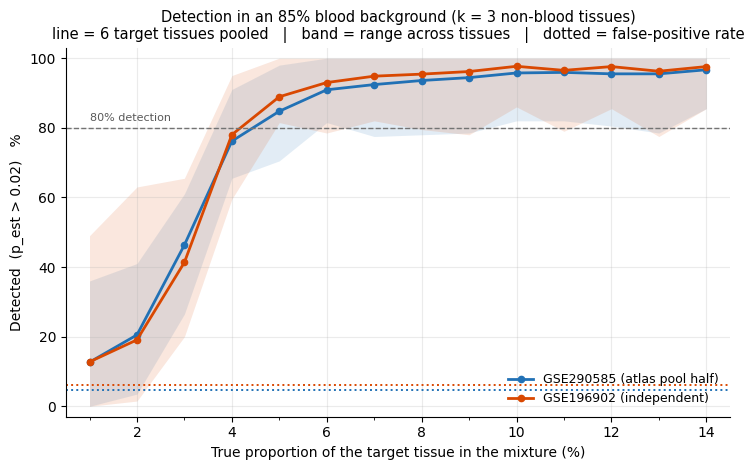


LOD at 80% detection, eps = 0.02, k = 3 (%; NaN = not reached by 14%)

                          GSE290585 pool + 85% blood  GSE196902 + 85% blood
target                                                                     
Brain_Cortex_Subcortical                        4.67                   4.58
Colon                                           5.15                   3.98
Liver                                           3.63                   3.70
Lung                                            5.86                   4.73
Pancreas                                        3.75                   3.90
Skin_Ears_Tail                                  4.85                   4.79


In [26]:
# ---- Combined figure: both cohorts, one panel -------------------------------------------
# One k, one line per cohort. The line pools all six targets; the band is the range across
# targets, so a single weak tissue stays visible. The dotted line is that cohort's false-positive
# rate on never-present tissues - detection below it is not distinguishable from noise.

def plot_detection_two_cohorts(results, k, eps, colours, output_path=None, dpi=150,
                               title=None):
    """Detection rate vs target share for several cohorts at one k.

    Parameters
    ----------
    results : dict
        cohort label -> sweep result (run_spike_sweep_blood output).
    colours : dict
        cohort label -> line colour.
    """
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    for label, res in results.items():
        df = res["df_sens"][res["df_sens"]["k"] == k]
        by_tissue = df.pivot_table(index="level", columns="target", values=f"det_{eps}")
        pooled    = df.groupby("level")[f"det_{eps}"].mean()
        x         = pooled.index.to_numpy() * 100
        c         = colours[label]

        ax.fill_between(x, by_tissue.min(axis=1) * 100, by_tissue.max(axis=1) * 100,
                        color=c, alpha=0.13, linewidth=0)
        ax.plot(x, pooled.to_numpy() * 100, "o-", color=c, lw=2.0, ms=4.5, label=label)
        ax.axhline(df[f"fpr_{eps}"].mean() * 100, ls=":", color=c, lw=1.4)

    ax.axhline(LOD_TARGET * 100, ls="--", c="0.45", lw=1)
    ax.text(SPIKE_LEVELS_BLOOD[0] * 100, LOD_TARGET * 100 + 2, f"{LOD_TARGET:.0%} detection",
            fontsize=8, color="0.35")
    _pct_axis(ax, SPIKE_LEVELS_BLOOD)
    ax.set_ylim(-3, 103)
    ax.set_xlabel("True proportion of the target tissue in the mixture (%)")
    ax.set_ylabel(f"Detected  (p_est > {eps})   %")
    ax.legend(frameon=False, fontsize=9, loc="lower right")
    ax.grid(alpha=.25)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if title:
        ax.set_title(title, fontsize=10.5)
    fig.tight_layout()
    _finish(fig, output_path, dpi)


plot_detection_two_cohorts(
    {"GSE290585 (atlas pool half)": res_blood_atlas,
     "GSE196902 (independent)":     res_blood_val},
    k=K_SHOW, eps=eps_main,
    colours={"GSE290585 (atlas pool half)": COHORT_COLOURS["GSE290585"],
             "GSE196902 (independent)":     COHORT_COLOURS["GSE196902"]},
    output_path=BOTH_BLOOD_PATH, dpi=DPI,
    title=(f"Detection in an {BLOOD_LEVEL_SENS:.0%} blood background "
           f"(k = {K_SHOW} non-blood tissues)\n"
           "line = 6 target tissues pooled   |   band = range across tissues   |   "
           "dotted = false-positive rate"),
)

# headline numbers behind the figure
print(f"\nLOD at {LOD_TARGET:.0%} detection, eps = {eps_main}, k = {K_SHOW} (%; NaN = not reached by "
      f"{SPIKE_LEVELS_BLOOD[-1]:.0%})\n")
print(pd.DataFrame({lab: lod[K_SHOW] * 100 for lab, lod in lod_blood.items()}).round(2).to_string())

### Reading these results

**The LOD here is a floor set by biology and reference quality, not by assay noise.** The
mixtures carry replicate-to-centroid deviation (real biological and batch variation) but no
array measurement noise is added on top. A real cfDNA assay adds sequencing/hybridisation
noise, fragmentation bias and unknown components, all of which push the detection limit
upward. Treat these numbers as a best case.

**Check the floor and sink lines before trusting any LOD.** Detection cannot fall below the
hallucination rate, so a curve sitting near its FPR is not measuring detection. A tissue
already "detected" at the smallest spike is absorbing mass rather than being found, and its
LOD is an artifact.

`Colon` has 2 replicates in GSE196902 and `Brain_Cortex_Subcortical` and `Liver` have 3. Their
curves rest on very few distinct biological samples, so per-tissue LODs for those are
correspondingly uncertain.

---

## I.8 Limit-of-detection summary

One table per cohort, collecting the per-k LOD tables printed in section I.7, with the blood sweep
extended to k = 6 (the section I.7 figure stays on k = 2–4). For every tissue: the best, median and
worst LOD across k, the k range it covers, and how many k reached the detection target. Both runs
share `W_ref` and one probe list. Written to `results/deconvolution/lod_summary.csv`.

**What a LOD is here.** The smallest true share at which a tissue is detected in ≥ 80 % of the 200
mixtures for that (k, level) cell, where *detected* means its estimated share exceeds ε. It says
nothing about whether the amount is right.

**Two thresholds.** *Fixed* uses ε = 0.02 everywhere. *Calibrated* sets ε per k so that only 5 % of
never-present tissues clear it. The calibrated value is the headline: at a fixed ε the
false-positive floor rises with k, so noise starts counting as detection and the fixed LOD drifts
down with k for reasons unrelated to the target.

**k** counts the non-blood tissues only (2–6); blood is always there on top.

**Flags.** `mass sink`: the tissue is already "detected" in > 50 % of mixtures at the smallest spike
(the rule `report_spike_results` uses), so its LOD is an artifact. `never reached 80 %`: no k
reached the target within the ladder. `partial`: some k did not.

In [27]:
# ---- Blood sweep extended to k = 6 - for the summary tables only ---------------------
# Builds NEW result objects and calls no plot function, so res_blood_atlas / res_blood_val and
# the section I.7 figure stay on k = 2-4. Seeds are stable per (seed_tag, k, target, level), so
# running k = 5-6 here gives exactly what a single k = 2-6 sweep would have given.

K_EXTRA_BLOOD = [5, 6]
assert max(K_EXTRA_BLOOD) <= len(TARGETS_BLOOD), "k exceeds the number of non-blood targets"


def merge_sweeps(*results):
    """Concatenate sweep results that cover disjoint k ranges into one result dict."""
    ks = [k for r in results for k in r["spike_absent"]]
    assert len(ks) == len(set(ks)), f"k ranges overlap: {sorted(ks)}"
    return {"df_sens":      pd.concat([r["df_sens"] for r in results], ignore_index=True),
            "df_raw":       pd.concat([r["df_raw"]  for r in results], ignore_index=True),
            "spike_absent": {k: v for r in results for k, v in r["spike_absent"].items()}}


print("GSE290585 pool half, 85% blood, k = 5-6:")
ext_blood_atlas = run_spike_sweep_blood(
    lookup_blood_atlas, lookup_blood_atlas, W_blood, TARGETS_BLOOD, never_present_blood,
    seed_tag="blood|GSE290585", k_range=K_EXTRA_BLOOD)        # same tag as section I.7

print("\nGSE196902, 85% blood from the GSE290585 pool half, k = 5-6:")
ext_blood_val = run_spike_sweep_blood(
    lookup_blood_val, lookup_blood_atlas, W_blood, TARGETS_BLOOD, never_present_blood,
    seed_tag="blood|GSE196902", k_range=K_EXTRA_BLOOD)        # same tag as section I.7

res_blood_atlas_k6 = merge_sweeps(res_blood_atlas, ext_blood_atlas)
res_blood_val_k6   = merge_sweeps(res_blood_val,   ext_blood_val)

for name, r in [("GSE290585", res_blood_atlas_k6), ("GSE196902", res_blood_val_k6)]:
    d = r["df_sens"]
    assert not d.duplicated(["k", "target", "level"]).any(), f"{name}: duplicate sweep cells"
    print(f"{name}: k = {sorted(int(k) for k in d['k'].unique())}, {len(d)} (k, target, level) cells")
print(f"section I.7 objects untouched: k = {sorted(int(k) for k in res_blood_atlas['df_sens']['k'].unique())}")

GSE290585 pool half, 85% blood, k = 5-6:


  k=5 done


  k=6 done

GSE196902, 85% blood from the GSE290585 pool half, k = 5-6:


  k=5 done


  k=6 done
GSE290585: k = [2, 3, 4, 5, 6], 420 (k, target, level) cells
GSE196902: k = [2, 3, 4, 5, 6], 420 (k, target, level) cells
section I.7 objects untouched: k = [2, 3, 4]


In [28]:
# ---- Per-tissue LOD summary for one run ------------------------------------------------
# The LOD tables come from report_spike_results (section I.7), run silently, so this summary can
# never disagree with the per-k tables printed above. Only the aggregation over k is new.

LOD_SINK_RULE = 0.5     # as in report_spike_results: detected in > 50% of mixtures at the smallest spike


def lod_summary(res, never_present, cohort, background, w_note):
    """Best / median / worst LOD over k per tissue, at the calibrated and the fixed threshold.

    Returns one row per tissue. LODs are in %; NaN means the detection target was not reached
    within the spike ladder at that k, and is ignored by the median / best / worst.
    """
    with contextlib.redirect_stdout(io.StringIO()):
        lod_fixed, lod_cal = report_spike_results(res, never_present, f"{cohort} / {background}")

    df_sens = res["df_sens"]
    lo      = df_sens["level"].min()
    sink    = (df_sens[df_sens["level"] == lo]
               .pivot_table(index="target", columns="k", values=f"det_{eps_main}")
               .max(axis=1))
    ks = sorted(lod_cal.columns)

    rows = []
    for tissue in lod_cal.index:
        cal, fixed = lod_cal.loc[tissue] * 100, lod_fixed.loc[tissue] * 100
        n_cal, n_fixed = int(cal.notna().sum()), int(fixed.notna().sum())

        flags = []
        if sink.get(tissue, 0.0) > LOD_SINK_RULE:
            flags.append("mass sink")
        if n_cal == 0:
            flags.append(f"never reached {LOD_TARGET:.0%}")
        elif n_cal < len(ks):
            flags.append("partial")

        rows.append({
            "cohort": cohort, "background": background, "W": w_note,
            "k_range": f"{ks[0]}-{ks[-1]}", "tissue": tissue,
            "lod_cal_median":   cal.median(),   "lod_cal_best":   cal.min(),   "lod_cal_worst":   cal.max(),
            "lod_fixed_median": fixed.median(), "lod_fixed_best": fixed.min(), "lod_fixed_worst": fixed.max(),
            "k_reached_cal":   f"{n_cal}/{len(ks)}",
            "k_reached_fixed": f"{n_fixed}/{len(ks)}",
            "flag": "; ".join(flags),
        })
    return pd.DataFrame(rows)


print("lod_summary defined")

lod_summary defined


In [29]:
# ---- Build, show and write the summary --------------------------------------------------

LOD_RUNS = [
    # (result, never-present tissues, cohort, background, W used)
    (res_blood_atlas_k6, never_present_blood, "GSE290585", "85% blood", "reference-half W_ref (shared probes)"),
    (res_blood_val_k6,   never_present_blood, "GSE196902", "85% blood", "reference-half W_ref (shared probes)"),
]
# All-NaN rows (target never reached) make numpy warn on the median; the value is NaN either way.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    df_lod = pd.concat([lod_summary(*run) for run in LOD_RUNS], ignore_index=True)

SHOW = ["tissue", "lod_cal_median", "lod_cal_best", "lod_cal_worst",
        "lod_fixed_median", "lod_fixed_best", "lod_fixed_worst",
        "k_reached_cal", "k_reached_fixed", "flag"]
HEADERS = ["tissue", "cal median", "cal best", "cal worst",
           "fixed median", "fixed best", "fixed worst",
           "k reached (cal)", "k reached (fixed)", "flag"]

blocks = list(df_lod.groupby(["cohort", "background", "W", "k_range"], sort=False))
for (cohort, background, w_note, k_range), g in blocks:
    print(f"\n{cohort}  |  background: {background}  |  k = {k_range}  |  {w_note}")
    print(f"LOD (%) at {LOD_TARGET:.0%} detection - calibrated ({FPR_BUDGET:.0%} FPR budget) and fixed "
          f"(eps = {eps_main})\n")
    print(g[SHOW].set_axis(HEADERS, axis=1).to_string(
        index=False, float_format=lambda v: f"{v:.2f}", na_rep="-"))


# ---- results/deconvolution/lod_summary.csv ------------------------------------------------
LOD_OUT_DIR = config.DECONV_OUTPUT_DIR
LOD_OUT_DIR.mkdir(parents=True, exist_ok=True)

csv_path = LOD_OUT_DIR / "lod_summary.csv"
df_lod.round(3).to_csv(csv_path, index=False)


print(f"\nwritten -> {csv_path.relative_to(config.PROJECT_ROOT)}")


GSE290585  |  background: 85% blood  |  k = 2-6  |  reference-half W_ref (shared probes)
LOD (%) at 80% detection - calibrated (5% FPR budget) and fixed (eps = 0.02)

                  tissue  cal median  cal best  cal worst  fixed median  fixed best  fixed worst k reached (cal) k reached (fixed) flag
Brain_Cortex_Subcortical        4.92      4.50       5.44          4.91        4.67         5.53             5/5               5/5     
                   Colon        4.81      4.47       5.05          4.81        4.50         5.22             5/5               5/5     
                   Liver        3.54      3.49       3.61          3.57        3.52         3.73             5/5               5/5     
                    Lung        5.83      5.47       9.33          5.86        5.47         9.33             5/5               5/5     
                Pancreas        3.61      3.47       3.95          3.61        3.45         4.04             5/5               5/5     
          Skin_E

# Part II. Publication figures

## Blood-fixed complexity sweep

Four tissues (Lung, Liver, Colon, Brain) recovered against a **fixed 85 % blood background**, at
increasing mixture complexity k = 1…4, run on two mixture sources.

| | Lung / Liver / Colon / Brain from | Blood from |
|---|---|---|
| **Scenario A** | GSE290585, pool half | GSE290585, pool half |
| **Scenario B** | GSE196902 | GSE290585, pool half |

Blood is never taken from GSE196902: it has no whole-blood samples, only Spleen and Thymus.
Both scenarios therefore borrow blood from the GSE290585 pool half, and
differ *only* in where the four non-blood tissues come from.

### Leakage safety

One `split_reference_pool` call, same seed and fraction as `run_deconvolution.py`:

- **reference half** → centroids → probe selection → **W**. Used only to build the matrix.
- **pool half** → the only source of GSE290585 material ever mixed, blood included.

GSE196902 needs no split: it contributed nothing to W or the probe panel, so all of it is usable
as mixture material.

### Geometry note

Blood takes exactly 0.85, so the non-blood tissues share exactly **0.15**. At k=1 the single
tissue takes all of it, so every k=1 point sits at x = 0.15: a vertical stripe, by construction,
not a bug. Higher k splits that 0.15 further, pushing the anchor tissue toward 0. The x-axis
therefore spans [0, 0.15] and k is confounded with position along it.

In [30]:
# ---- Configuration -----------------------------------------------------------
BLOOD        = "Blood_Spleen"
TISSUES_4    = ["Lung", "Liver", "Colon", "Brain_Cortex_Subcortical"]
BLOOD_LEVEL  = 0.85                 # fixed in every mixture
K_VALUES     = [1, 2, 3, 4]         # number of NON-blood tissues
N_PER_CELL   = 1000                 # mixtures per (tissue, k) cell
DIR_ALPHA    = 1.0

BASE_SEED    = 20260908             # deterministic; see cell_seed() below

# Colour per k, in K_VALUES order. Any matplotlib colour spec works: hex, named
# colours ("crimson"), or RGB tuples. Edit freely - this is the only place colour
# is decided.
# Colorblind-friendly (Okabe-Ito inspired)
K_PALETTE    = ["#0072B2", "#D55E00", "#CC79A7", "#F0E442"]

# GSE196902 label -> atlas tissue. Restricted to the four of interest:
# Spleen/Thymus are deliberately absent (blood comes from GSE290585 instead),
# as are Skin and Pancreas, which are outside this experiment.
VAL_TO_ATLAS_4 = {
    "Brain":  "Brain_Cortex_Subcortical",
    "Colon":  "Colon",
    "Liver":  "Liver",
    "Lung":   "Lung",
}

print(f"blood fixed at {BLOOD_LEVEL:.0%}, non-blood tissues share {1-BLOOD_LEVEL:.0%}")
print(f"k values: {K_VALUES}   |   {N_PER_CELL} mixtures per (tissue, k) cell")
print(f"total: {len(TISSUES_4)} tissues x {len(K_VALUES)} k x 2 scenarios x {N_PER_CELL} "
      f"= {len(TISSUES_4)*len(K_VALUES)*2*N_PER_CELL:,} mixtures")

blood fixed at 85%, non-blood tissues share 15%
k values: [1, 2, 3, 4]   |   1000 mixtures per (tissue, k) cell
total: 4 tissues x 4 k x 2 scenarios x 1000 = 32,000 mixtures


In [31]:
# ---- Imports -----------------------------------------------------------------
import sys, io, zlib, contextlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
import config
import data_loading

# Figure output: same convention as config.FIGURE_FORMAT / config.FIGURE_DPI in src/.
# SAVE_FIGURES is set in the first cell of the notebook.
FIG_FORMAT   = config.FIGURE_FORMAT   # "pdf" (vector, for papers) or "png" (raster)
FIG_DPI      = config.FIGURE_DPI      # only affects raster formats; ignored for pdf
FIG_DIR      = config.FIGURES_DIR / "publication"
if SAVE_FIGURES:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
import deconv_data
import deconv_model
from utils import (extract_sample_labels, build_centroids,
                   select_probes_from_centroids, build_label_map)

# src/visualization.py forces Agg at import; inline renders to an embedded PNG and needs no
# display server, so this stays headless-safe while letting panels show in the notebook.
%matplotlib inline

warnings.filterwarnings("ignore", category=UserWarning)


def cell_seed(scenario: str, tissue: str, k: int) -> int:
    """Deterministic per-cell seed.

    Deliberately NOT hash(): Python randomises string hashing per process, so seeds derived
    from hash() differ between kernel restarts. crc32 is stable across processes.
    """
    return (BASE_SEED + zlib.crc32(f"{scenario}|{tissue}|{k}".encode())) % (2**31)


assert cell_seed("A", "Lung", 1) == cell_seed("A", "Lung", 1)
print("imports ready | seeding is deterministic across processes")

imports ready | seeding is deterministic across processes


---

## II.1 Load both datasets in full

Nothing is pre-filtered here. Both cohorts are loaded whole so they are available for later work
in this notebook; the restriction to four tissues happens only at mixture-generation time.

In [32]:
# ---- GSE290585 (atlas cohort) ------------------------------------------------
# Same call run_pipeline.py / run_deconvolution.py use, so identical preprocessing:
# same EXCLUDED_TISSUES and MERGE_GROUPS.
with contextlib.redirect_stdout(io.StringIO()):
    df_atlas, _, _, _ = data_loading.load_all()

atlas_labels = extract_sample_labels(df_atlas)
atlas_labels = atlas_labels[~atlas_labels.isin(data_loading.EXCLUDED_TISSUES)]
atlas_map    = build_label_map(data_loading.MERGE_GROUPS)
atlas_merged = atlas_labels.map(lambda x: atlas_map.get(x, x))

print(f"GSE290585: {len(atlas_labels)} samples, "
      f"{atlas_merged.nunique()} merged tissues, {len(df_atlas):,} probes")
print(f"  excluded at load: {sorted(data_loading.EXCLUDED_TISSUES)}")

GSE290585: 240 samples, 20 merged tissues, 288,655 probes
  excluded at load: ['Mammary_Glands', 'Optic_Nerve', 'Sciatic_Nerve', 'Thymus']


In [33]:
# ---- GSE196902 (independent cohort) ------------------------------------------
# Loaded whole, including Spleen/Thymus/BM/Breast/Prostate. Only Lung/Liver/Colon/Brain
# are used for mixtures below.
df_val     = pd.read_csv(config.DATA_DIR / "processed" /
                         "GSE196902_MM285_normal_processed.csv")
df_val_idx = df_val.set_index("probe_ID")
val_labels = extract_sample_labels(df_val)

print(f"GSE196902: {len(val_labels)} samples, {len(df_val):,} probes")
print(f"  all labels: {sorted(val_labels.unique())}")
print(f"  used here : {sorted(VAL_TO_ATLAS_4)}  "
      f"(Spleen/Thymus dropped - blood comes from GSE290585)")

GSE196902: 56 samples, 287,050 probes
  all labels: ['BM', 'Brain', 'Breast', 'Colon', 'Liver', 'Lung', 'Pancreas', 'Prostate', 'Skin', 'Spleen', 'Thymus']
  used here : ['Brain', 'Colon', 'Liver', 'Lung']  (Spleen/Thymus dropped - blood comes from GSE290585)


---

## II.2 Split, reference matrix, shared probe list

One split. Reference half builds W and never gets mixed; pool half is the only GSE290585 material
that ever enters a mixture.

In [34]:
# ---- The split and W ---------------------------------------------------------
ref_cols, pool_cols = deconv_data.split_reference_pool(
    atlas_labels,
    reference_fraction=config.DECONV_REFERENCE_FRACTION,
    random_state=config.DECONV_SPLIT_SEED,
)
assert not (set(ref_cols) & set(pool_cols)), "reference and pool overlap - leakage"

# probe selection sees reference-half centroids only
with contextlib.redirect_stdout(io.StringIO()):
    cen_ref = build_centroids(df_raw=df_atlas, sample_cols=ref_cols,
                              original_labels=atlas_labels,
                              merge_groups=data_loading.MERGE_GROUPS)
    panel = select_probes_from_centroids(cen_ref, suppress_warnings=True)
    W_full = deconv_data.build_reference_matrix(
        df_raw=df_atlas, reference_cols=ref_cols,
        original_labels=atlas_labels, selected_probes=panel)

print(f"split      : {len(ref_cols)} reference / {len(pool_cols)} pool")
print(f"panel      : {len(panel)} probes, selected on reference-half centroids only")
print(f"W_full     : {W_full.shape[0]} probes x {W_full.shape[1]} tissues")
print(f"             cond={np.linalg.cond(W_full.values):.1f}")

missing = [t for t in TISSUES_4 + [BLOOD] if t not in W_full.columns]
assert not missing, f"tissues absent from W: {missing}"

Reference samples: 116
Pool samples:      124


split      : 116 reference / 124 pool
panel      : 1000 probes, selected on reference-half centroids only
W_full     : 1000 probes x 20 tissues
             cond=95.1


In [35]:
# ---- Shared probe list: usable in BOTH scenarios ------------------------------
# Scenario B needs panel probes that exist in GSE196902 and are non-NaN in the samples we
# actually mix (the four tissues only - a NaN in a Spleen sample is irrelevant here).
# Scenario A then uses this SAME list, so A and B differ only in mixture source, not in
# feature count.

val_mixable = val_labels[val_labels.isin(VAL_TO_ATLAS_4)]

present     = [p for p in panel if p in set(df_val_idx.index)]
used_block  = df_val_idx.loc[present, val_mixable.index]
nan_probes  = set(used_block.index[used_block.isna().any(axis=1)])
SHARED      = [p for p in present if p not in nan_probes]

W = W_full.loc[SHARED]                       # reindex, never a boolean mask

assert list(W.index) == SHARED, "W row order does not match the shared probe list"
assert not W.isna().any().any(), "W carries NaN"

print(f"panel probes                  : {len(panel)}")
print(f"  present in GSE196902        : {len(present)}")
print(f"  minus NaN in used samples   : {len(SHARED)}   <- shared list, used by BOTH scenarios")
print(f"\nW (both scenarios): {W.shape[0]} probes x {W.shape[1]} tissues")

NON_PARTICIPATING = [t for t in W.columns if t not in TISSUES_4 + [BLOOD]]
print(f"participating tissues     : {len(TISSUES_4) + 1}  ({', '.join(TISSUES_4)}, {BLOOD})")
print(f"non-participating (must=0): {len(NON_PARTICIPATING)}")

panel probes                  : 1000
  present in GSE196902        : 1000
  minus NaN in used samples   : 997   <- shared list, used by BOTH scenarios

W (both scenarios): 997 probes x 20 tissues
participating tissues     : 5  (Lung, Liver, Colon, Brain_Cortex_Subcortical, Blood_Spleen)
non-participating (must=0): 15


In [36]:
# ---- Pool lookups ------------------------------------------------------------
# All three are masked to SHARED, in SHARED's order, so every mixture vector lines up with
# W row-for-row.

lookup_atlas = deconv_data._build_pool_lookup(
    df_atlas, pool_cols, atlas_labels, atlas_map, SHARED)          # GSE290585 pool half
lookup_val = deconv_data._build_pool_lookup(
    df_val, val_mixable.index.tolist(), val_mixable, VAL_TO_ATLAS_4, SHARED)   # GSE196902

for name, lk in [("GSE290585 pool", lookup_atlas), ("GSE196902", lookup_val)]:
    for t in sorted(lk):
        if t in TISSUES_4 + [BLOOD]:
            assert lk[t].shape[1] == len(SHARED), f"{name}/{t}: probe count mismatch"

print("replicates available as mixture material\n")
print(f"{'tissue':<28}{'GSE290585 pool':>16}{'GSE196902':>12}")
print("-" * 56)
for t in TISSUES_4:
    print(f"{t:<28}{lookup_atlas[t].shape[0]:>16}{lookup_val.get(t, np.empty((0,0))).shape[0]:>12}")
print(f"{BLOOD:<28}{lookup_atlas[BLOOD].shape[0]:>16}{'not used':>12}")

assert BLOOD not in lookup_val, "blood must not come from GSE196902"

replicates available as mixture material

tissue                        GSE290585 pool   GSE196902
--------------------------------------------------------
Lung                                       5          14
Liver                                     13           3
Colon                                      6           2
Brain_Cortex_Subcortical                  13           3
Blood_Spleen                              12    not used


---

## II.3 Mixture generator

Blood pinned at exactly 85 %; the anchor tissue is always present; k−1 further tissues are drawn
from the remaining three. The leftover 15 % is split across those k tissues by Dirichlet.

Nothing in `src/` does this: `deconv_regimes.generate_blood_dominant_mixtures` draws blood from a
*range* and picks non-blood tissues unforced from the full eligible set. The replicate-sampling
mechanic below is the same one used throughout the project.

In [37]:
# ---- Generator ---------------------------------------------------------------
def generate_blood_fixed_mixtures(lookup_nonblood, lookup_blood, anchor, k, candidates,
                                  all_tissue_columns, blood_tissue=BLOOD,
                                  blood_level=BLOOD_LEVEL, n_mixtures=N_PER_CELL,
                                  dirichlet_alpha=DIR_ALPHA, random_state=0):
    """Mixtures with blood at a fixed level and one anchor tissue always present.

    lookup_nonblood : tissue -> (n_replicates, n_probes) for the non-blood tissues
    lookup_blood    : tissue -> (n_replicates, n_probes) containing blood_tissue
                      (a separate lookup so blood can come from a different cohort)
    anchor          : tissue guaranteed present in every mixture
    k               : number of NON-blood tissues (anchor + k-1 drawn from candidates)
    """
    others = [t for t in candidates if t != anchor]
    if k - 1 > len(others):
        raise ValueError(f"k={k} needs {k-1} others, only {len(others)} available")

    rng  = np.random.RandomState(random_state)
    cols = list(all_tissue_columns)
    ti   = {t: i for i, t in enumerate(cols)}
    n_probes  = lookup_blood[blood_tissue].shape[1]
    remaining = 1.0 - blood_level

    X = np.zeros((n_mixtures, n_probes))
    P = np.zeros((n_mixtures, len(cols)))

    for m in range(n_mixtures):
        # blood, fixed level, replicate drawn from its own cohort
        breps = lookup_blood[blood_tissue]
        vec   = blood_level * breps[rng.randint(len(breps))]
        P[m, ti[blood_tissue]] = blood_level

        # anchor + k-1 others share the remainder
        extra  = [str(t) for t in rng.choice(others, size=k - 1, replace=False)] if k > 1 else []
        chosen = [anchor] + extra
        props  = remaining * rng.dirichlet(np.full(k, dirichlet_alpha))
        for j, t in enumerate(chosen):
            reps = lookup_nonblood[t]
            vec += props[j] * reps[rng.randint(len(reps))]
            P[m, ti[t]] = props[j]

        X[m] = vec

    # index matches deconvolve_batch's ("mixture_i") so true/est align under
    # pandas arithmetic - otherwise (est - true) silently returns all NaN
    return X, pd.DataFrame(P, columns=cols,
                           index=[f"mixture_{i}" for i in range(n_mixtures)])


# sanity check before the full sweep
Xc, Pc = generate_blood_fixed_mixtures(
    lookup_atlas, lookup_atlas, "Lung", 3, TISSUES_4, W.columns,
    n_mixtures=50, random_state=0)
assert np.allclose(Pc[BLOOD], BLOOD_LEVEL),            "blood not held at the fixed level"
assert np.allclose(Pc.sum(axis=1), 1.0),               "proportions do not sum to 1"
assert (Pc["Lung"] > 0).all(),                         "anchor tissue not always present"
assert ((Pc > 0).sum(axis=1) == 4).all(),              "wrong component count (3 + blood)"
assert (Pc[NON_PARTICIPATING] == 0).all().all(),       "mass assigned to a non-participating tissue"
print("generator sanity check passed")

generator sanity check passed


---

## II.4 Run both scenarios

32 cells: 4 anchor tissues × 4 k values × 2 scenarios, 1000 mixtures each.

In [38]:
# ---- Sweep -------------------------------------------------------------------
SCENARIOS = {
    "A": dict(label="Scenario A — all five tissues from GSE290585 (pool half)",
              lookup_nonblood=lookup_atlas),
    "B": dict(label="Scenario B — four tissues from GSE196902, blood from GSE290585",
              lookup_nonblood=lookup_val),
}

results = {}      # (scenario, tissue, k) -> dict(true=, est=)

for scen, cfg in SCENARIOS.items():
    for tissue in TISSUES_4:
        for k in K_VALUES:
            X, P = generate_blood_fixed_mixtures(
                lookup_nonblood=cfg["lookup_nonblood"],
                lookup_blood=lookup_atlas,               # blood ALWAYS from GSE290585 pool
                anchor=tissue, k=k, candidates=TISSUES_4,
                all_tissue_columns=W.columns,
                n_mixtures=N_PER_CELL,
                random_state=cell_seed(scen, tissue, k),
            )
            with contextlib.redirect_stdout(io.StringIO()):
                E, resid = deconv_model.deconvolve_batch(W, X)
            results[(scen, tissue, k)] = dict(true=P, est=E, resid=resid)
    print(f"scenario {scen} done")

print(f"\n{len(results)} cells, {len(results) * N_PER_CELL:,} mixtures total")

scenario A done


scenario B done

32 cells, 32,000 mixtures total


In [39]:
# ---- Verification ------------------------------------------------------------
for (scen, tissue, k), r in results.items():
    P = r["true"]
    tag = f"{scen}/{tissue}/k={k}"
    assert np.allclose(P[BLOOD], BLOOD_LEVEL),          f"{tag}: blood not fixed"
    assert np.allclose(P.sum(axis=1), 1.0),             f"{tag}: proportions do not sum to 1"
    assert (P[tissue] > 0).all(),                       f"{tag}: anchor not always present"
    assert (P[NON_PARTICIPATING] == 0).all().all(),     f"{tag}: non-participating tissue non-zero"
    assert ((P > 0).sum(axis=1) == k + 1).all(),        f"{tag}: wrong component count"

print("all cells: blood fixed, anchor always present, only the 5 tissues ever non-zero\n")

# k=1 geometry and the replicate ceiling
print(f"k=1 check — every point should sit at x = {1-BLOOD_LEVEL:.2f} exactly\n")
print(f"{'scenario':<10}{'tissue':<28}{'x values':>10}{'distinct pts':>14}{'ceiling':>10}")
print("-" * 74)
for scen, cfg in SCENARIOS.items():
    for tissue in TISSUES_4:
        r  = results[(scen, tissue, 1)]
        xs = r["true"][tissue].to_numpy()
        ys = r["est"][tissue].to_numpy()
        n_rep   = cfg["lookup_nonblood"][tissue].shape[0]
        ceiling = n_rep * lookup_atlas[BLOOD].shape[0]
        print(f"{scen:<10}{tissue:<28}{len(np.unique(xs.round(10))):>10}"
              f"{len(np.unique(ys.round(10))):>14}{ceiling:>10}")
        assert np.allclose(xs, 1 - BLOOD_LEVEL), "k=1 x values are not all identical"

all cells: blood fixed, anchor always present, only the 5 tissues ever non-zero

k=1 check — every point should sit at x = 0.15 exactly

scenario  tissue                        x values  distinct pts   ceiling
--------------------------------------------------------------------------
A         Lung                                 1            51        60
A         Liver                                1           156       156
A         Colon                                1            72        72
A         Brain_Cortex_Subcortical             1           151       156
B         Lung                                 1           147       168
B         Liver                                1            36        36
B         Colon                                1            24        24
B         Brain_Cortex_Subcortical             1            36        36


---

## II.5 Figures

One row of four panels per scenario, coloured by k. No panel for blood: its true proportion is
constant, so there is nothing to scatter it against.

Axis limits run to 15 %, not 100 %, because that is the whole range the non-blood tissues can
occupy.

In [40]:
# ---- Plotting ----------------------------------------------------------------
# The figure is drawn by deconv_model.plot_true_vs_estimated_scatter itself - the same
# function behind eval_scatter_per_tissue.png and the k*_scatter.png family. We then
# reach into the PathCollection it created and recolour its points by k. Same artist,
# recoloured; not a redraw. Every visual property (alpha, marker size, the red dashed
# identity line, square aspect, r-in-title, tick sizes, sup-labels, no grid) therefore
# comes from src and cannot drift.
#
# src closes the figure via _save_or_close(); we patch that to a no-op so it survives.
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors

# to_rgba is not optional: np.vstack on raw hex strings yields an (n, 1) string array
# rather than (n, 4) RGBA, which set_facecolors would then misread.
assert len(K_PALETTE) >= len(K_VALUES), "K_PALETTE needs one colour per k"
K_COLOURS = {k: mcolors.to_rgba(c) for k, c in zip(K_VALUES, K_PALETTE)}


def build_pooled(scen, tissues=TISSUES_4, ks=K_VALUES):
    """Stack the k-blocks into one true/est pair, plus the k each row came from.

    Row order is identical across tissue columns, so a single colour array serves
    every panel.
    """
    trues, ests, k_of_row = [], [], []
    for k in ks:
        for tissue in tissues:
            r = results[(scen, tissue, k)]
            trues.append(r["true"][tissues])
            ests.append(r["est"][tissues])
            k_of_row.append(np.full(len(r["true"]), k))
    return (pd.concat(trues, ignore_index=True),
            pd.concat(ests,  ignore_index=True),
            np.concatenate(k_of_row))


def plot_scenario(scen, title, tissues=TISSUES_4, ks=K_VALUES,
                  figsize=(16, 5.0), fit_limits=True, output_path=None,
                  dpi=None):
    """dpi is only used for raster formats (png etc.); ignored for pdf/svg, matching
    src/deconv_model._save_or_close."""
    dpi = FIG_DPI if dpi is None else dpi
    df_true, df_est, k_of_row = build_pooled(scen, tissues, ks)

    # let src draw the whole thing, keeping the figure alive
    keep = {}
    original = deconv_model._save_or_close
    deconv_model._save_or_close = lambda output_path=None, dpi=150: keep.setdefault("f", plt.gcf())
    try:
        deconv_model.plot_true_vs_estimated_scatter(df_true, df_est, title=title)
    finally:
        deconv_model._save_or_close = original
    fig = keep["f"]

    # recolour by k - the one thing the src function cannot express
    colours = np.vstack([K_COLOURS[k] for k in k_of_row])
    for ax in fig.axes:
        if not ax.get_visible() or not ax.collections:
            continue
        coll = ax.collections[0]
        assert len(coll.get_offsets()) == len(colours), "colour array does not match the drawn points"
        coll.set_facecolors(colours)
        coll.set_edgecolors("none")

    # blood at 85% caps the data at 0.15; src hard-codes 0-1, which would leave a corner
    # blob. x and y keep one shared range so set_aspect("equal") still gives squares.
    if fit_limits:
        lim = max(df_true.to_numpy().max(), df_est.to_numpy().max())
        for ax in fig.axes:
            if ax.get_visible():
                ax.set_xlim(-0.05 * lim, 1.05 * lim)
                ax.set_ylim(-0.05 * lim, 1.05 * lim)

    # the k key goes in the slot src already created and hid (n_cols=5, 4 tissues)
    spare = [ax for ax in fig.axes if not ax.get_visible()]
    if spare:
        lg = spare[0]
        lg.set_visible(True)
        lg.axis("off")
        lg.legend(handles=[Line2D([], [], marker="o", linestyle="", color=K_COLOURS[k],
                                  markersize=7, alpha=0.8, label=f"k = {k}") for k in ks],
                  loc="center left", frameon=False, fontsize=9,
                  title="non-blood\ncomponents", title_fontsize=9)

    # src ran tight_layout at its own figsize; resizing invalidates that, so redo the
    # layout at the new size or the sup-labels collide with the tick labels
    fig.set_size_inches(*figsize)
    fig.tight_layout()

    if output_path is not None:
        fig.savefig(output_path, dpi=dpi, bbox_inches="tight")
        print(f"Figure saved -> {Path(output_path).relative_to(config.PROJECT_ROOT)}")

    return fig


print("plot_scenario ready — src draws it, we only recolour")

plot_scenario ready — src draws it, we only recolour


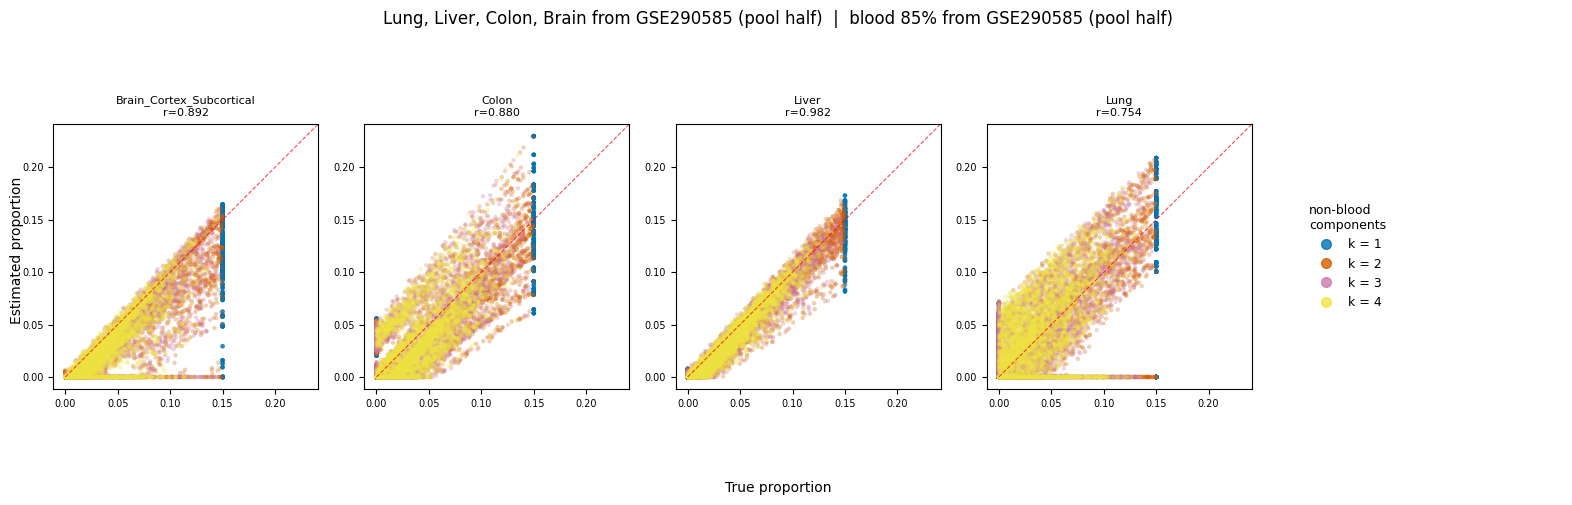

tissue                         k   median true   median est   median err
------------------------------------------------------------------------
Lung                           1        15.00%       13.73%       -1.27%
                               2         7.37%        6.22%       -0.34%
                               3         4.48%        3.86%       -0.28%
                               4         3.15%        3.32%        0.05%
Liver                          1        15.00%       14.29%       -0.71%
                               2         7.57%        6.69%       -0.65%
                               3         4.08%        3.39%       -0.54%
                               4         3.26%        2.66%       -0.48%
Colon                          1        15.00%       13.87%       -1.13%
                               2         7.59%        6.24%       -1.08%
                               3         4.37%        3.72%       -1.02%
                               4         3.16%     

In [41]:
TITLE_A = ("Lung, Liver, Colon, Brain from GSE290585 (pool half)  |  blood 85% from GSE290585 (pool half)")

# ---- Scenario A --------------------------------------------------------------
fig = plot_scenario(
    "A", TITLE_A,
    output_path=(FIG_DIR / f"scenario_A.{FIG_FORMAT}") if SAVE_FIGURES else None,
)
plt.show()

print(f"{'tissue':<28}{'k':>4}{'median true':>14}{'median est':>13}{'median err':>13}")
print("-" * 72)
for tissue in TISSUES_4:
    for k in K_VALUES:
        r = results[("A", tissue, k)]
        t, e = r["true"][tissue], r["est"][tissue]
        err = e.to_numpy() - t.to_numpy()
        print(f"{tissue if k == K_VALUES[0] else '':<28}{k:>4}"
              f"{t.median()*100:>13.2f}%{e.median()*100:>12.2f}%"
              f"{np.median(err)*100:>12.2f}%")

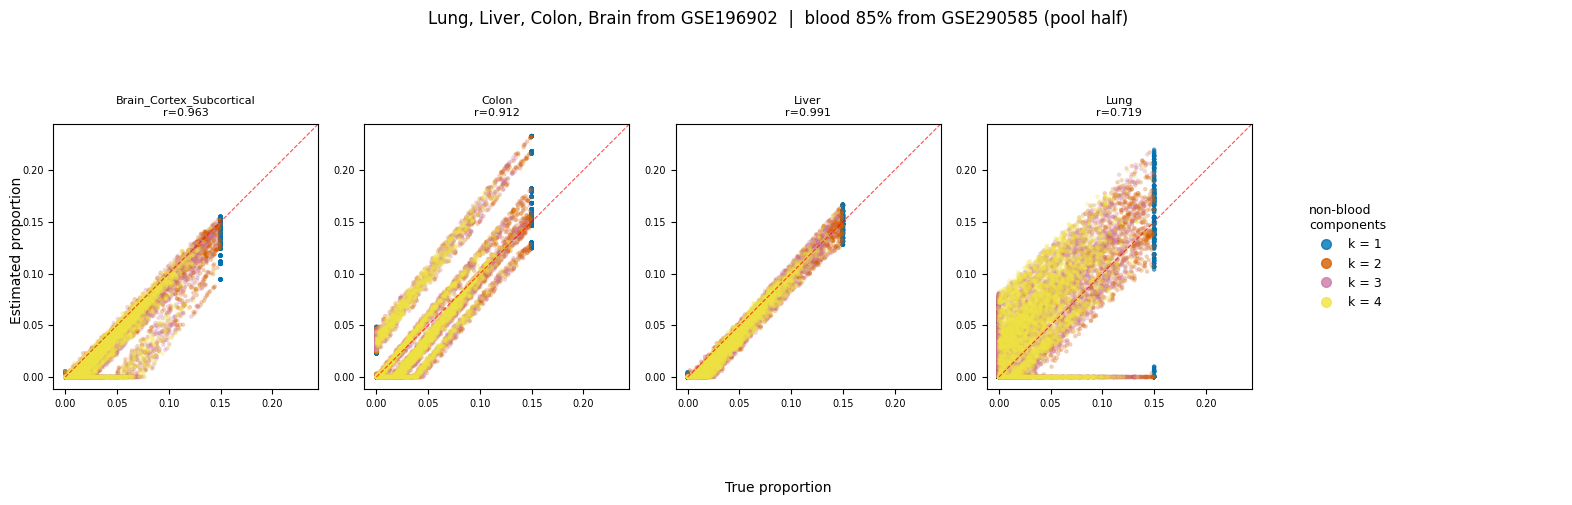

tissue                         k   median true   median est   median err
------------------------------------------------------------------------
Lung                           1        15.00%       14.37%       -0.63%
                               2         7.60%        7.54%        0.29%
                               3         4.33%        5.62%        1.19%
                               4         3.10%        4.60%        1.59%
Liver                          1        15.00%       14.82%       -0.18%
                               2         7.26%        6.56%       -0.54%
                               3         4.52%        3.75%       -0.61%
                               4         3.32%        2.57%       -0.65%
Colon                          1        15.00%       15.52%        0.52%
                               2         7.49%        7.16%       -0.51%
                               3         4.12%        3.92%       -0.75%
                               4         3.31%     

In [42]:
TITLE_B = ("Lung, Liver, Colon, Brain from GSE196902  |  blood 85% from GSE290585 (pool half)")

# ---- Scenario B --------------------------------------------------------------
fig = plot_scenario(
    "B", TITLE_B,
    output_path=(FIG_DIR / f"scenario_B.{FIG_FORMAT}") if SAVE_FIGURES else None,
)
plt.show()

print(f"{'tissue':<28}{'k':>4}{'median true':>14}{'median est':>13}{'median err':>13}")
print("-" * 72)
for tissue in TISSUES_4:
    for k in K_VALUES:
        r = results[("B", tissue, k)]
        t, e = r["true"][tissue], r["est"][tissue]
        err = e.to_numpy() - t.to_numpy()
        print(f"{tissue if k == K_VALUES[0] else '':<28}{k:>4}"
              f"{t.median()*100:>13.2f}%{e.median()*100:>12.2f}%"
              f"{np.median(err)*100:>12.2f}%")

---

## II.6 Where the missing mass goes

The 15 non-participating tissues have a true proportion of exactly 0 in every mixture, so anything
NNLS assigns them is a false positive. This matters here because `deconvolve_single` normalises
coefficients to sum to 1: mass parked on an absent tissue sits inside that denominator and
shrinks the four target tissues' estimates for reasons unrelated to their own markers.

At 85 % blood this is the worst case for `Femur`, which correlates r ≈ 0.58 with
`Blood_Spleen`.

In [43]:
# ---- Absent-tissue mass ------------------------------------------------------
rows = []
for scen in SCENARIOS:
    est = pd.concat([results[(scen, t, k)]["est"]
                     for t in TISSUES_4 for k in K_VALUES], ignore_index=True)
    absent = est[NON_PARTICIPATING]
    rows.append(pd.Series({
        "total absent mass (mean)": absent.sum(axis=1).mean(),
        "total absent mass (median)": absent.sum(axis=1).median(),
        **{t: absent[t].mean() for t in
           absent.mean().sort_values(ascending=False).head(5).index},
    }, name=f"Scenario {scen}"))

summary = pd.DataFrame(rows).T
print("Mean estimated proportion on tissues that CANNOT be present\n")
print((summary * 100).round(2).astype(str).add(" %").to_string())

print("\n\nBlood recovery (true = 85.00 % in every mixture)\n")
print(f"{'scenario':<12}{'median est':>13}{'median err':>13}")
print("-" * 40)
for scen in SCENARIOS:
    est = pd.concat([results[(scen, t, k)]["est"]
                     for t in TISSUES_4 for k in K_VALUES], ignore_index=True)
    b = est[BLOOD]
    print(f"{scen:<12}{b.median()*100:>12.2f}%{(b.median()-BLOOD_LEVEL)*100:>12.2f}%")

Mean estimated proportion on tissues that CANNOT be present

                           Scenario A Scenario B
total absent mass (mean)       5.61 %     5.34 %
total absent mass (median)     3.53 %     3.45 %
Femur                          1.49 %     2.03 %
Diaphragm                      1.35 %     1.16 %
Spinal_Cord                    1.03 %     0.71 %
Pancreas                       0.81 %     0.53 %
Testis                         0.29 %     0.28 %


Blood recovery (true = 85.00 % in every mixture)

scenario       median est   median err
----------------------------------------
A                  81.26%       -3.74%
B                  79.25%       -5.75%


---

## II.7 One-tissue recovery map

A compact overview of the **k=1** case: for a sample that is a single pure tissue, how much of its
signal does NNLS put back on the right tissue, and where does the rest go?

This reuses everything built in sections II.1–II.2 and adds no new loading, split or probe selection.
`_build_pool_lookup` already returned each replicate masked to `SHARED`, in `SHARED`'s order
(which is `W`'s row order), so **the pool lookups already are the k=1 design matrices**. A synthetic
k=1 mixture is arithmetically the sample itself at weight 1.0, the point section I.4
makes, so the arrays go straight into `deconvolve_batch`.

**No blood.** `W` already carries `Blood_Spleen` among its 20 columns; blood only ever enters on
the *mixture* side, and nothing here builds a mixture. Adding a fixed blood background would turn
this back into the section II.4–II.5 benchmark. This is the clean one-tissue problem.

### Cell value

`M[i, j]` = **mean estimated NNLS proportion assigned to tissue j, over samples whose true tissue
is i**, not a hard `argmax` call. `deconvolve_single` normalises every sample to sum 1, so the row
means also sum to 1: each row is a distribution over recovered tissues, which is the same property
`normalize='true'` gives a confusion matrix, on the same 0–1 scale. The diagonal is exactly the
quantity section I.4 calls `recovered`. A top-1 frequency was rejected because at
n = 2–3 samples per row it could only take values in {0, ½, 1} (decisive-looking and almost
uninformative) and because it would discard the quantitative output that is the point of NNLS.

### Coordinate system

One shared system, matrix indexing `[row, column]`, `[0, 0]` upper-left:

- **row** = true tissue, **column** = estimated / recovered tissue.

The four focal tissues (Lung, Liver, Colon, Brain) occupy rows/columns 0–3; the remaining 16
follow alphabetically, the ordering the classifier confusion matrices already use.

| region | source |
|---|---|
| `row > column` | GSE290585 |
| `row == column`, `row < 4` | GSE196902 |
| `row == column`, `row >= 4` | GSE290585 |
| `row < column`, both `< 4` | GSE196902 |
| `row < column`, otherwise | blank / not applicable |

The GSE290585 diagonal for the focal four is therefore computed but **deliberately not displayed**;
those values are printed below so the substitution is explicit rather than silent.

**Blank is not zero.** Every evaluated cell carries a printed value, `0.00` included; unevaluated
cells are left white, with no value and no grid. The two are different claims ("measured, and the
mass really is zero" versus "never evaluated") and the figure keeps them visually distinct rather
than collapsing both into one pale colour.

### This is not a confusion matrix

It shows neither cohort's complete directional matrix, and across the focal diagonal the two
directions come from different datasets. It is a compact recovery map with two cohorts encoded in
complementary regions of one coordinate system, and should be captioned that way.

Each row of the underlying matrix sums to 1 over all 20 columns, but the *displayed* cells are a
masked subset, so a displayed row does not; the `off_map` column below reports the difference.

In [44]:
# ---- Recovery map configuration ----------------------------------------------
# Reads the objects built in sections II.1-II.2 (W, SHARED, lookup_atlas, lookup_val, TISSUES_4).

N_FOCAL = len(TISSUES_4)

# Row/column order: the four focal tissues first, then the remaining 16 alphabetically.
# Alphabetical is the existing convention for the rest - it is what LabelEncoder.classes_
# gives the classifier confusion matrices - so this figure deviates only where intended.
ORDER = TISSUES_4 + [t for t in sorted(W.columns) if t not in TISSUES_4]
assert len(ORDER) == len(W.columns), "ORDER does not cover W's tissues"
assert set(ORDER) == set(W.columns), "ORDER does not match W's tissues"

# Display labels. Anything not listed has its underscores turned into spaces.
DISPLAY_NAMES = {
    "Brain_Cortex_Subcortical": "Brain",
    "Blood_Spleen":             "Blood/Spleen",
    "Skin_Ears_Tail":           "Skin/Ears/Tail",
    "Eye_Retina":               "Eye/Retina",
}

# Visual knobs - the only place the look of this figure is decided. Re-running this cell
# plus the plotting call is enough to change the design; the NNLS solves do not re-run.
CMAP_A         = "Blues"     # GSE290585 - lower triangle + diagonal rows 4..19
CMAP_B         = "Oranges"   # GSE196902 - the focal 4x4 block

BLOCK_EDGE     = "#C1440E"   # outline around the GSE196902 block
LABEL_A_COLOUR = "#1F4E79"

# Every evaluated cell carries a value, 0.00 included. The ones that print "0.00" are drawn
# fainter so the eye still lands on the real structure. Raise ANNOT_MIN to declutter again.
ANNOT_MIN   = 0.0            # proportions are always >= 0, so 0.0 labels every evaluated cell
ANNOT_SIZE  = 6
# Label colours are chosen per cell from the BACKGROUND luminance rather than from the value.
# On the sequential scales below that is equivalent to a "value > 0.5" test, but it also holds
# for a scale that is dark at both ends.
# Each pair is (on light fill, on dark fill).
VALUE_TEXT  = "0.15"         # normal label, on a light fill
ZERO_TEXT   = "0.55"         # de-emphasised "0.00", on a light fill
HIGH_TEXT   = "white"        # normal label, on a dark fill
ZERO_TEXT_D = "0.85"         # de-emphasised "0.00", on a dark fill

# The grid is per-cell borders rather than ax.grid(), so it stops at the staircase and leaves
# the blank region clean. White - the classifier convention - is invisible on pale fills.
GRID_COLOUR = "0.80"
GRID_WIDTH  = 0.4

RECOVERY_FIG_FORMATS = [FIG_FORMAT]        # follows config.FIGURE_FORMAT, like scenario_A/B
RECOVERY_STEM        = "tissue_recovery_map"


def display_name(tissue):
    """Short axis label for a merged tissue name."""
    return DISPLAY_NAMES.get(tissue, tissue.replace("_", " "))


print(f"focal ({N_FOCAL}) : {[display_name(t) for t in ORDER[:N_FOCAL]]}")
print(f"then  ({len(ORDER) - N_FOCAL}): {[display_name(t) for t in ORDER[N_FOCAL:]]}")

focal (4) : ['Lung', 'Liver', 'Colon', 'Brain']
then  (16): ['Adrenal', 'Bile Duct', 'Blood/Spleen', 'Cerebellum', 'Diaphragm', 'Eye/Retina', 'Femur', 'Heart', 'Kidney', 'Pancreas', 'Skin/Ears/Tail', 'Spinal Cord', 'Stomach', 'Testis', 'Urinary Bladder', 'Uterus']


In [45]:
# ---- k=1 deconvolution of pure samples ---------------------------------------
# The pool lookups ARE the k=1 design matrices: _build_pool_lookup already returned each
# replicate masked to SHARED, in SHARED's order, which is W's row order. A synthetic k=1
# mixture is that same vector at weight 1.0, so no mixture generation and no realignment
# is needed - the arrays go straight into deconvolve_batch.
#
# No blood is added anywhere in this section; see the note above.

def k1_recovery(lookup, tissues, W):
    """Mean estimated proportion per (true tissue, estimated tissue) for pure samples.

    Parameters
    ----------
    lookup : dict
        merged tissue -> (n_replicates, n_probes) array, already masked to W.index
        in W.index's order (from deconv_data._build_pool_lookup).
    tissues : list
        Tissues to include as true-tissue rows.
    W : pd.DataFrame
        Reference matrix (probes x tissues).

    Returns
    -------
    M     : pd.DataFrame   true tissue x estimated tissue, mean estimated proportion.
                           Rows sum to 1, because deconvolve_single normalises each sample.
    est   : pd.DataFrame   per-sample estimates, indexed by true tissue (labels repeat).
    resid : pd.Series      per-sample NNLS residual, same index.
    """
    missing = [t for t in tissues if t not in lookup]
    assert not missing, f"tissues absent from the lookup: {missing}"

    X   = np.vstack([lookup[t] for t in tissues])
    src = np.concatenate([[t] * lookup[t].shape[0] for t in tissues])

    assert X.shape[1] == W.shape[0], "probe count does not match W"
    assert np.isfinite(X).all(), (
        "NaN/Inf in the k=1 design matrix - NNLS cannot accept it. SHARED was filtered for "
        "NaN against GSE196902's four tissues only, so the other GSE290585 tissues were "
        "never checked. Drop the offending probes from BOTH cohorts before continuing, so "
        "the shared feature space is preserved."
    )

    with contextlib.redirect_stdout(io.StringIO()):
        est, resid = deconv_model.deconvolve_batch(W, X)
    est.index = src

    return est.groupby(level=0).mean(), est, pd.Series(resid, index=src)


# GSE290585: the pool half only. W was built from the reference half with a reference-only
# probe panel, so no atlas sample is ever scored against a W it helped build.
M29, est29, res29 = k1_recovery(lookup_atlas, ORDER, W)

# GSE196902: contributed nothing to W or the panel, so all of it is usable.
M19, est19, res19 = k1_recovery(lookup_val, TISSUES_4, W)

M29 = M29.reindex(index=ORDER,     columns=ORDER)
M19 = M19.reindex(index=TISSUES_4, columns=ORDER)

assert np.allclose(M29.sum(axis=1), 1.0), "GSE290585 rows are not stochastic"
assert np.allclose(M19.sum(axis=1), 1.0), "GSE196902 rows are not stochastic"

# replicate counts per row, for the y tick labels
N29 = {t: lookup_atlas[t].shape[0] for t in ORDER}
N19 = {t: lookup_val[t].shape[0]   for t in TISSUES_4}

print(f"GSE290585 pool: {len(est29):>3} pure samples over {len(ORDER):>2} tissues  "
      f"| median residual {res29.median():.4f}")
print(f"GSE196902     : {len(est19):>3} pure samples over {N_FOCAL:>2} tissues  "
      f"| median residual {res19.median():.4f}")
print(f"\nthinnest rows: "
      + ", ".join(f"{display_name(t)} n={N29[t]}"
                  for t in sorted(ORDER, key=lambda x: N29[x])[:3]))

GSE290585 pool: 124 pure samples over 20 tissues  | median residual 1.0169
GSE196902     :  22 pure samples over  4 tissues  | median residual 1.9521

thinnest rows: Uterus n=2, Adrenal n=3, Bile Duct n=3


In [46]:
# ---- Assemble the two display layers -----------------------------------------
# Matrix indexing throughout: [row, column], [0, 0] upper-left, row = true tissue and
# column = estimated tissue. Every displayed cell keeps that interpretation.
#
#   row >  column                   -> GSE290585
#   row == column, row <  N_FOCAL   -> GSE196902   (GSE290585's focal diagonal is
#   row == column, row >= N_FOCAL   -> GSE290585    computed but not displayed)
#   row <  column, both <  N_FOCAL  -> GSE196902
#   row <  column, otherwise        -> blank / not applicable, NOT zero

n = len(ORDER)
A = np.full((n, n), np.nan)      # GSE290585 layer
B = np.full((n, n), np.nan)      # GSE196902 layer

for i in range(n):
    for j in range(n):
        if i > j:
            A[i, j] = M29.iat[i, j]
        elif i == j:
            if i < N_FOCAL:
                B[i, j] = M19.iat[i, j]
            else:
                A[i, j] = M29.iat[i, j]
        elif i < N_FOCAL and j < N_FOCAL:
            B[i, j] = M19.iat[i, j]

# Cell counts are fully determined by the rule above, so they are a cheap, strong check
# on any indexing or transposition slip.
n_lower       = n * (n - 1) // 2                     # below the diagonal
n_upper_focal = N_FOCAL * (N_FOCAL - 1) // 2         # above the diagonal, inside the block
n_a, n_b      = int(np.isfinite(A).sum()), int(np.isfinite(B).sum())

assert not (np.isfinite(A) & np.isfinite(B)).any(), "a cell was assigned to both datasets"
assert n_a == n_lower + (n - N_FOCAL), "GSE290585 cell count is wrong"
assert n_b == n_upper_focal + N_FOCAL, "GSE196902 cell count is wrong"

# Orientation: a value must land at [true, estimated], never its transpose.
assert A[ORDER.index("Liver"), ORDER.index("Lung")] == M29.loc["Liver", "Lung"]
assert np.isnan(A[ORDER.index("Lung"), ORDER.index("Liver")]), \
    "[Lung, Liver] is above the focal diagonal and must not come from GSE290585"
assert B[0, 0] == M19.loc[ORDER[0], ORDER[0]], "focal diagonal is not GSE196902"
assert np.isnan(B[N_FOCAL, N_FOCAL]), "non-focal diagonal must not come from GSE196902"

print(f"GSE290585 cells : {n_a:>3}  ({n_lower} below diagonal + {n - N_FOCAL} diagonal)")
print(f"GSE196902 cells : {n_b:>3}  ({n_upper_focal} above diagonal + {N_FOCAL} diagonal)")
print(f"blank cells     : {n * n - n_a - n_b:>3}  (not evaluated - drawn white, never as zero)")

GSE290585 cells : 206  (190 below diagonal + 16 diagonal)
GSE196902 cells :  10  (6 above diagonal + 4 diagonal)
blank cells     : 184  (not evaluated - drawn white, never as zero)


In [47]:
# ---- The recovery map --------------------------------------------------------
# A custom heatmap rather than sns.heatmap / classifier_model.plot_confusion_matrix:
# seaborn cannot draw two masked layers with two colormaps on one axes, which is exactly
# what the split geometry needs. Everything else follows the classifier figure - 0-1 scale,
# .2f annotation, 14x12 canvas, true on y and estimated on x - so the result still belongs to
# that figure family. The grid is the one deliberate departure: ax.grid() would run across the
# blank region too, so borders are drawn per evaluated cell instead (see below).
#
# Returns fig and does NOT close it, exactly like plot_scenario above, so the panel renders
# inline and the returned handle stays pokeable for quick edits. Every visual choice is a
# keyword argument; call with output_paths=None to iterate on the design without touching
# disk, and without re-running the NNLS solves.

from matplotlib.patches import Rectangle
from matplotlib.colors import PowerNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable


def plot_recovery_map(
    A, B, order, n_focal,
    row_n_a=None, row_n_b=None,
    cmap_a=None, cmap_b=None, block_edge=None, label_a_colour=None,
    annot_min=None, annot_size=None,
    value_text=None, zero_text=None, high_text=None, zero_text_dark=None,
    grid_colour=None, grid_width=None,
    label_a="GSE290585", label_b="GSE196902",
    sublabel_a="atlas pool half", sublabel_b="independent validation",
    figsize=(14, 12), title=None, output_paths=None, dpi=None,
):
    """One-tissue recovery map: two masked layers, two colormaps, one coordinate system.

    Parameters
    ----------
    A, B : np.ndarray
        (n, n) arrays, NaN wherever that dataset does not populate the cell. A and B must
        not both be finite in the same cell.
    order : list
        Tissue names in row/column order - identical on both axes.
    n_focal : int
        Size of the leading focal block that dataset B occupies.
    row_n_a, row_n_b : dict, optional
        tissue -> replicate count, used for the y tick labels. row_n_b wins where both
        have an entry, since B populates those rows' diagonals.
    annot_min : float, optional
        Cells below this are coloured and bordered but left unlabelled. 0.0 labels every
        evaluated cell, 0.00s included.
    value_text, zero_text, high_text, zero_text_dark : optional
        Label colours, picked per cell from the background luminance: value_text/zero_text on
        light fills, high_text/zero_text_dark on dark ones. Both ends of a diverging map are
        dark, so the choice cannot be made from the value alone.
    grid_colour, grid_width : optional
        Per-cell border, drawn on evaluated cells only.
    output_paths : iterable, optional
        Paths to save to. None draws without saving.
    """
    cmap_a         = CMAP_A         if cmap_a         is None else cmap_a
    cmap_b         = CMAP_B         if cmap_b         is None else cmap_b
    block_edge     = BLOCK_EDGE     if block_edge     is None else block_edge
    label_a_colour = LABEL_A_COLOUR if label_a_colour is None else label_a_colour
    annot_min      = ANNOT_MIN      if annot_min      is None else annot_min
    annot_size     = ANNOT_SIZE     if annot_size     is None else annot_size
    value_text     = VALUE_TEXT     if value_text     is None else value_text
    zero_text      = ZERO_TEXT      if zero_text      is None else zero_text
    high_text      = HIGH_TEXT      if high_text      is None else high_text
    zero_text_dark = ZERO_TEXT_D    if zero_text_dark is None else zero_text_dark
    grid_colour    = GRID_COLOUR    if grid_colour    is None else grid_colour
    grid_width     = GRID_WIDTH     if grid_width     is None else grid_width
    dpi            = FIG_DPI        if dpi            is None else dpi

    n = len(order)

    ca = matplotlib.colormaps[cmap_a].copy() if isinstance(cmap_a, str) else cmap_a.copy()
    cb = matplotlib.colormaps[cmap_b].copy() if isinstance(cmap_b, str) else cmap_b.copy()
    ca.set_bad(color="white", alpha=1.0)   # blank cells read as absence, not as a value of 0
    cb.set_bad(alpha=0.0)                  # transparent, so layer A shows through

    fig, ax = plt.subplots(figsize=figsize)

    # origin="upper" is matplotlib's default and puts [0, 0] at the upper-left, matching
    # the [row, column] construction above with no flip anywhere in the pipeline.
    im_a = ax.imshow(np.ma.masked_invalid(A), cmap=ca,
                     norm=PowerNorm(gamma=0.45, vmin=0, vmax=1),
                     origin="upper", interpolation="nearest")
    im_b = ax.imshow(np.ma.masked_invalid(B), cmap=cb,
                     norm=PowerNorm(gamma=0.45, vmin=0, vmax=1),
                     origin="upper", interpolation="nearest")

    # ---- ticks and labels
    row_n_a, row_n_b = row_n_a or {}, row_n_b or {}
    ylabels = []
    for t in order:
        n_rep = row_n_b.get(t, row_n_a.get(t))
        ylabels.append(f"{display_name(t)}  (n={n_rep})" if n_rep is not None
                       else display_name(t))

    ax.set_xticks(range(n))
    ax.set_xticklabels([display_name(t) for t in order], rotation=90, fontsize=8)
    ax.set_yticks(range(n))
    ax.set_yticklabels(ylabels, fontsize=8)
    ax.set_xlabel("Estimated / recovered tissue", fontsize=11)
    ax.set_ylabel("True tissue", fontsize=11)

    # ---- per-cell borders and annotation
    # The grid is drawn per evaluated cell rather than with ax.grid(), which confines it to the
    # staircase: every evaluated cell reads as a discrete box even at 0.00, while the blank
    # region stays completely clean. White gridlines (the classifier convention) are invisible
    # against both the pale near-zero fills and the white blanks, hence a light grey border.
    for M in (A, B):
        for i in range(n):
            for j in range(n):
                v = M[i, j]
                if not np.isfinite(v):
                    continue                       # blank: no border, no label

                ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False,
                                       edgecolor=grid_colour, linewidth=grid_width,
                                       zorder=3))
                if v < annot_min:
                    continue

                # Which cells count as "0.00" is keyed off the formatted string, not a
                # separate rounding, so the cell that PRINTS "0.00" is always the one that
                # gets the faint treatment.
                #
                # Contrast comes from the cell's own background luminance (Rec. 709) rather
                # than from v. On a sequential scale the two agree; on a diverging one they do
                # not, since it runs dark at BOTH ends and "v > 0.5" would then leave dark text
                # sitting on a saturated low-end fill.
                label = f"{v:.2f}"
                _r, _g, _b = (cb if M is B else ca)(v)[:3]
                dark_bg = (0.2126 * _r + 0.7152 * _g + 0.0722 * _b) < 0.55
                if label == "0.00":
                    colour = zero_text_dark if dark_bg else zero_text
                else:
                    colour = high_text if dark_bg else value_text
                ax.text(j, i, label, ha="center", va="center",
                        fontsize=annot_size, color=colour, zorder=6)

    # ---- region boundaries: the B block, and a stepped rule along the diagonal
    ax.add_patch(Rectangle((-0.5, -0.5), n_focal, n_focal, fill=False,
                           edgecolor=block_edge, linewidth=2.0, zorder=5))

    step_x, step_y = [], []
    for i in range(n):
        step_x += [i - 0.5, i + 0.5]
        step_y += [i - 0.5, i - 0.5]
    step_x.append(n - 0.5)
    step_y.append(n - 0.5)
    ax.plot(step_x, step_y, color="0.25", linewidth=1.0, zorder=4)

    # ---- region labels, placed in the blank upper-right
    ax.annotate(f"{label_b}\n{sublabel_b}",
                xy=(n_focal - 1.3, 1.1), xytext=(n_focal + 2.5, 1.4),
                fontsize=10, color=block_edge, va="center", zorder=8,
                arrowprops=dict(arrowstyle="->", color=block_edge, lw=1.2))
    ax.annotate(f"{label_a}\n{sublabel_a}",
                # Tip sits just below the diagonal, anchor in the blank region. The two points
                # are chosen so the leader crosses at a cell corner rather than straight through
                # a diagonal cell - which shows now that every cell is bordered.
                xy=(n_focal + 3.0, n_focal + 4.0), xytext=(n_focal + 6.0, n_focal + 1.0),
                fontsize=10, color=label_a_colour, va="center", zorder=8,
                arrowprops=dict(arrowstyle="->", color=label_a_colour, lw=1.2))

    # ---- two colorbars, both on 0-1 so the two regions stay numerically comparable
    divider = make_axes_locatable(ax)
    cax_a   = divider.append_axes("right", size="2.5%", pad=0.12)
    cax_b   = divider.append_axes("right", size="2.5%", pad=0.60)
    bar_a   = fig.colorbar(im_a, cax=cax_a)
    bar_b   = fig.colorbar(im_b, cax=cax_b)
    bar_a.set_label(f"{label_a} — mean estimated proportion", fontsize=9)
    bar_b.set_label(f"{label_b} — mean estimated proportion", fontsize=9)
    for bar in (bar_a, bar_b):
        bar.ax.tick_params(labelsize=8)

    if title:
        ax.set_title(title, fontsize=11, pad=14)
    fig.tight_layout()

    for path in (output_paths or []):
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=dpi, bbox_inches="tight")
        print(f"Figure saved -> {Path(path).relative_to(config.PROJECT_ROOT)}")

    return fig

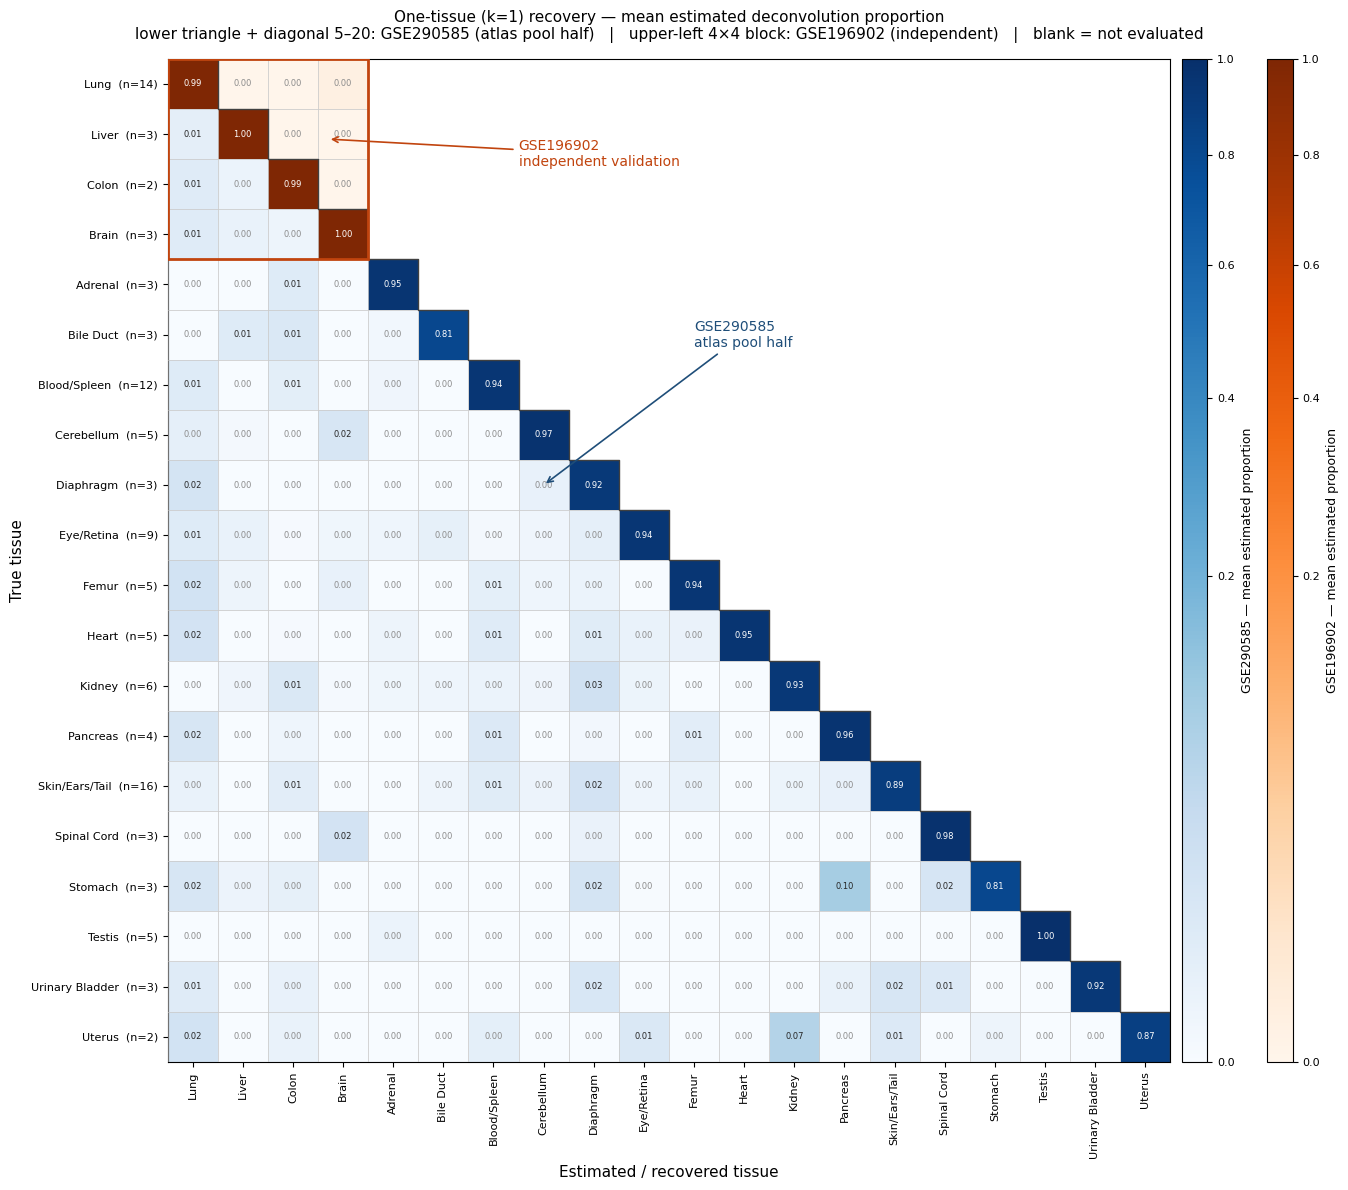

Per-row recovery — diagonal = mean proportion assigned to the correct tissue

         tissue    source  n  diagonal  top1_acc  off_map
           Lung GSE196902 14     0.993     1.000    0.006
          Liver GSE196902  3     1.000     1.000    0.000
          Colon GSE196902  2     0.994     1.000    0.006
          Brain GSE196902  3     1.000     1.000    0.000
        Adrenal GSE290585  3     0.949     1.000    0.042
      Bile Duct GSE290585  3     0.810     1.000    0.167
   Blood/Spleen GSE290585 12     0.944     1.000    0.040
     Cerebellum GSE290585  5     0.970     1.000    0.009
      Diaphragm GSE290585  3     0.916     1.000    0.059
     Eye/Retina GSE290585  9     0.943     1.000    0.033
          Femur GSE290585  5     0.942     1.000    0.022
          Heart GSE290585  5     0.949     1.000    0.005
         Kidney GSE290585  6     0.931     1.000    0.021
       Pancreas GSE290585  4     0.964     1.000    0.000
 Skin/Ears/Tail GSE290585 16     0.886     1.000    

In [48]:
# ---- Draw, save, report ------------------------------------------------------
TITLE_RECOVERY = (
    "One-tissue (k=1) recovery — mean estimated deconvolution proportion\n"
    "lower triangle + diagonal 5–20: GSE290585 (atlas pool half)   |   "
    "upper-left 4×4 block: GSE196902 (independent)   |   blank = not evaluated"
)

fig = plot_recovery_map(
    A, B, ORDER, N_FOCAL,
    row_n_a=N29, row_n_b=N19,
    title=TITLE_RECOVERY,
    output_paths=([FIG_DIR / f"{RECOVERY_STEM}.{ext}" for ext in RECOVERY_FIG_FORMATS]
                  if SAVE_FIGURES else None),
)
plt.show()


# ---- Per-row summary ---------------------------------------------------------
# Each row of M29 / M19 sums to 1 over all 20 columns, but the DISPLAYED cells are a masked
# subset, so a displayed row does not. "off_map" is how much of the row's mass falls in
# cells this figure does not show.
shown = np.isfinite(A) | np.isfinite(B)

rows = []
for i, tissue in enumerate(ORDER):
    focal = i < N_FOCAL
    M     = M19 if focal else M29
    est   = est19 if focal else est29
    sub   = est.loc[[tissue]]
    rows.append({
        "tissue":   display_name(tissue),
        "source":   "GSE196902" if focal else "GSE290585",
        "n":        (N19 if focal else N29)[tissue],
        "diagonal": M.loc[tissue, tissue],
        "top1_acc": (sub.idxmax(axis=1) == tissue).mean(),
        "off_map":  1.0 - M.loc[tissue, ORDER].to_numpy()[shown[i]].sum(),
    })

df_recovery = pd.DataFrame(rows)
print("Per-row recovery — diagonal = mean proportion assigned to the correct tissue\n")
print(df_recovery.to_string(index=False, float_format=lambda v: f"{v:.3f}"))


# ---- The suppressed GSE290585 focal diagonal ---------------------------------
# The figure shows GSE196902 on the focal diagonal, so these four GSE290585 values exist
# but are deliberately not displayed. Printed so the substitution is explicit, and so the
# two cohorts' focal recovery can still be compared numerically.
print("\n\nFocal-tissue diagonal, both cohorts "
      "(only the GSE196902 column appears on the figure)\n")
print(f"{'tissue':<16}{'GSE196902 (shown)':>20}{'GSE290585 (hidden)':>21}")
print("-" * 57)
for tissue in TISSUES_4:
    print(f"{display_name(tissue):<16}{M19.loc[tissue, tissue]:>20.3f}"
          f"{M29.loc[tissue, tissue]:>21.3f}")

acc29 = (est29.idxmax(axis=1).to_numpy() == est29.index.to_numpy()).mean()
acc19 = (est19.idxmax(axis=1).to_numpy() == est19.index.to_numpy()).mean()
print(f"\ntop-1 accuracy   GSE290585 pool: {acc29:.1%}   GSE196902: {acc19:.1%}")
print(f"median diagonal  GSE290585 pool: "
      f"{np.median([M29.loc[t, t] for t in ORDER[N_FOCAL:]]):.3f} (rows 5-20)   "
      f"GSE196902: {np.median([M19.loc[t, t] for t in TISSUES_4]):.3f} (focal 4)")

---

## II.8 Recovery map with a fit-error strip

The section II.7 map shows GSE196902 at 0.99–1.00 on the focal four and GSE290585 at 0.81–0.98
elsewhere, which reads as "the independent cohort performs better". It does not.

`deconvolve_single` **rescales every NNLS solution to sum to 1**. A sample that W fits poorly, here
because of a cross-cohort offset (different lab, processing, partly FFPE), cannot explain that
offset by mixing tissues, so NNLS puts nearly all of its mass on the single nearest column. After
rescaling, that looks like clean recovery. The cost is only visible in the residual, which the
section II.7 figure never shows.

This section adds that cost back as a strip next to the map:

- **value per row** = median, over the samples of the cohort shown on that row's diagonal, of the
  **RMS β error per CpG**: NNLS residual / √(number of probes). Same row rule as the diagonal:
  GSE196902 for the focal four, GSE290585 for the rest.
- Both cohorts are scored on the same `SHARED` probes against the same `W`, so the values are
  directly comparable. Lower = the fitted profile `W @ x` sits closer to the sample.
- the dashed line is the median over all GSE290585 pool samples.

The strip is added to the figure `plot_recovery_map` returns and saved as
`tissue_recovery_map_fit.*`.

In [49]:
# ---- Fit-error strip configuration -------------------------------------------
# Reads res29 / res19 from section II.7.

# RMS beta error per CpG: the NNLS residual is a Euclidean norm over all probes, so dividing by
# sqrt(n probes) puts it on the beta scale. Both cohorts share SHARED, so this is a constant.
N_PROBES_FIT = len(SHARED)
rms29 = res29 / np.sqrt(N_PROBES_FIT)      # GSE290585 pool, per sample
rms19 = res19 / np.sqrt(N_PROBES_FIT)      # GSE196902, per sample

# One value per row, in ORDER - the cohort shown on that row's diagonal, as in section II.7.
# .loc[[t]] rather than .loc[t]: tissue labels repeat in the index, one per sample.
FIT = np.array([
    (rms19 if i < N_FOCAL else rms29).loc[[t]].median()
    for i, t in enumerate(ORDER)
])
FIT_REF = rms29.median()                   # reference line: every GSE290585 pool sample

# Visual knobs
FIT_STRIP_IN = 2.4       # strip width, inches
FIT_GAP_IN   = 0.35      # gap heatmap -> strip, and strip -> colorbars, inches
FIT_BAR_H    = 0.62      # bar thickness, in row units (1.0 = touching)
FIT_SHADE    = 0.65      # where on each layer's colormap the bar colour is taken

FIT_STEM     = "tissue_recovery_map_fit"

print(f"probes: {N_PROBES_FIT}")
print(f"median RMS beta error per CpG   GSE290585 pool: {rms29.median():.4f}   "
      f"GSE196902: {rms19.median():.4f}   ratio {rms19.median() / rms29.median():.2f}x")

probes: 997
median RMS beta error per CpG   GSE290585 pool: 0.0322   GSE196902: 0.0618   ratio 1.92x


In [50]:
# ---- The fit-error strip -----------------------------------------------------
# Works on the figure plot_recovery_map returns.
# Its heatmap and colorbars are placed by an axes divider; here every axis is frozen at its
# drawn position, the figure is widened by the strip, the colorbars move right, and the strip
# goes into the gap. Positions are kept in inches, so nothing already drawn is stretched.


def add_fit_strip(
    fig, fit, n_focal, fit_ref=None,
    cmap_a=None, cmap_b=None, block_edge=None,
    strip_in=None, gap_in=None, bar_h=None, shade=None,
    label_ref="GSE290585\npool median",
    xlabel="NNLS fit error\n(RMS β per CpG)",
):
    """Insert a per-row fit-error strip between the recovery map and its colorbars.

    Parameters
    ----------
    fig : matplotlib.figure.Figure
        As returned by plot_recovery_map: axes[0] is the map, axes[1:3] the two colorbars.
    fit : array-like
        One value per row, in the map's row order.
    n_focal : int
        Rows < n_focal are coloured as dataset B, the rest as dataset A.
    fit_ref : float, optional
        Drawn as a dashed reference line.

    Returns
    -------
    The strip axes.
    """
    cmap_a     = CMAP_A       if cmap_a     is None else cmap_a
    cmap_b     = CMAP_B       if cmap_b     is None else cmap_b
    block_edge = BLOCK_EDGE   if block_edge is None else block_edge
    strip_in   = FIT_STRIP_IN if strip_in   is None else strip_in
    gap_in     = FIT_GAP_IN   if gap_in     is None else gap_in
    bar_h      = FIT_BAR_H    if bar_h      is None else bar_h
    shade      = FIT_SHADE    if shade      is None else shade

    assert len(fig.axes) == 3, "expected the map plus two colorbars"
    ax, cax_a, cax_b = fig.axes
    fit = np.asarray(fit, dtype=float)
    n   = len(fit)

    # ---- freeze every axis at its drawn position, in inches
    fig.canvas.draw()
    w_in, h_in = fig.get_size_inches()
    boxes = {}
    for a in (ax, cax_a, cax_b):
        p = a.get_position()
        boxes[a] = (p.x0 * w_in, p.y0 * h_in, p.width * w_in, p.height * h_in)
        a.set_axes_locator(None)          # the divider would otherwise re-place it

    shift = gap_in + strip_in + gap_in
    w_new = w_in + shift
    fig.set_size_inches(w_new, h_in)

    def place(a, x, y, w, h):
        a.set_position([x / w_new, y / h_in, w / w_new, h / h_in])

    x, y, w, h = boxes[ax]
    place(ax, x, y, w, h)
    for c in (cax_a, cax_b):
        cx, cy, cw, ch = boxes[c]
        place(c, cx + shift, cy, cw, ch)

    # ---- the strip: same height and row orientation as the map, so rows line up
    sax = fig.add_axes([0, 0, 1, 1])
    place(sax, x + w + gap_in, y, strip_in, h)

    def pick(cmap):
        cmap = matplotlib.colormaps[cmap] if isinstance(cmap, str) else cmap
        return cmap(shade)

    colours = [pick(cmap_b) if i < n_focal else pick(cmap_a) for i in range(n)]
    sax.barh(np.arange(n), fit, height=bar_h, color=colours, edgecolor="none", zorder=2)
    sax.set_ylim(n - 0.5, -0.5)           # row 0 on top, as in the map

    xmax = max(np.nanmax(fit), fit_ref or 0.0) * 1.40
    sax.set_xlim(0, xmax)
    for i, v in enumerate(fit):
        sax.text(v + xmax * 0.03, i, f"{v:.3f}", ha="left", va="center",
                 fontsize=7, color="0.30", zorder=3)

    if fit_ref is not None:
        sax.axvline(fit_ref, color="0.40", linewidth=0.9, linestyle=(0, (3, 3)), zorder=1)
        sax.text(fit_ref, -0.75, label_ref, ha="center", va="bottom",
                 fontsize=7.5, color="0.35", clip_on=False)

    # the focal block ends here - same colour as the block outline on the map
    sax.axhline(n_focal - 0.5, color=block_edge, linewidth=1.0, zorder=1)

    sax.set_yticks([])
    sax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(3))
    sax.tick_params(axis="x", labelsize=8)
    sax.set_xlabel(xlabel, fontsize=9)
    for side in ("top", "right"):
        sax.spines[side].set_visible(False)
    sax.spines["left"].set_color("0.6")

    return sax

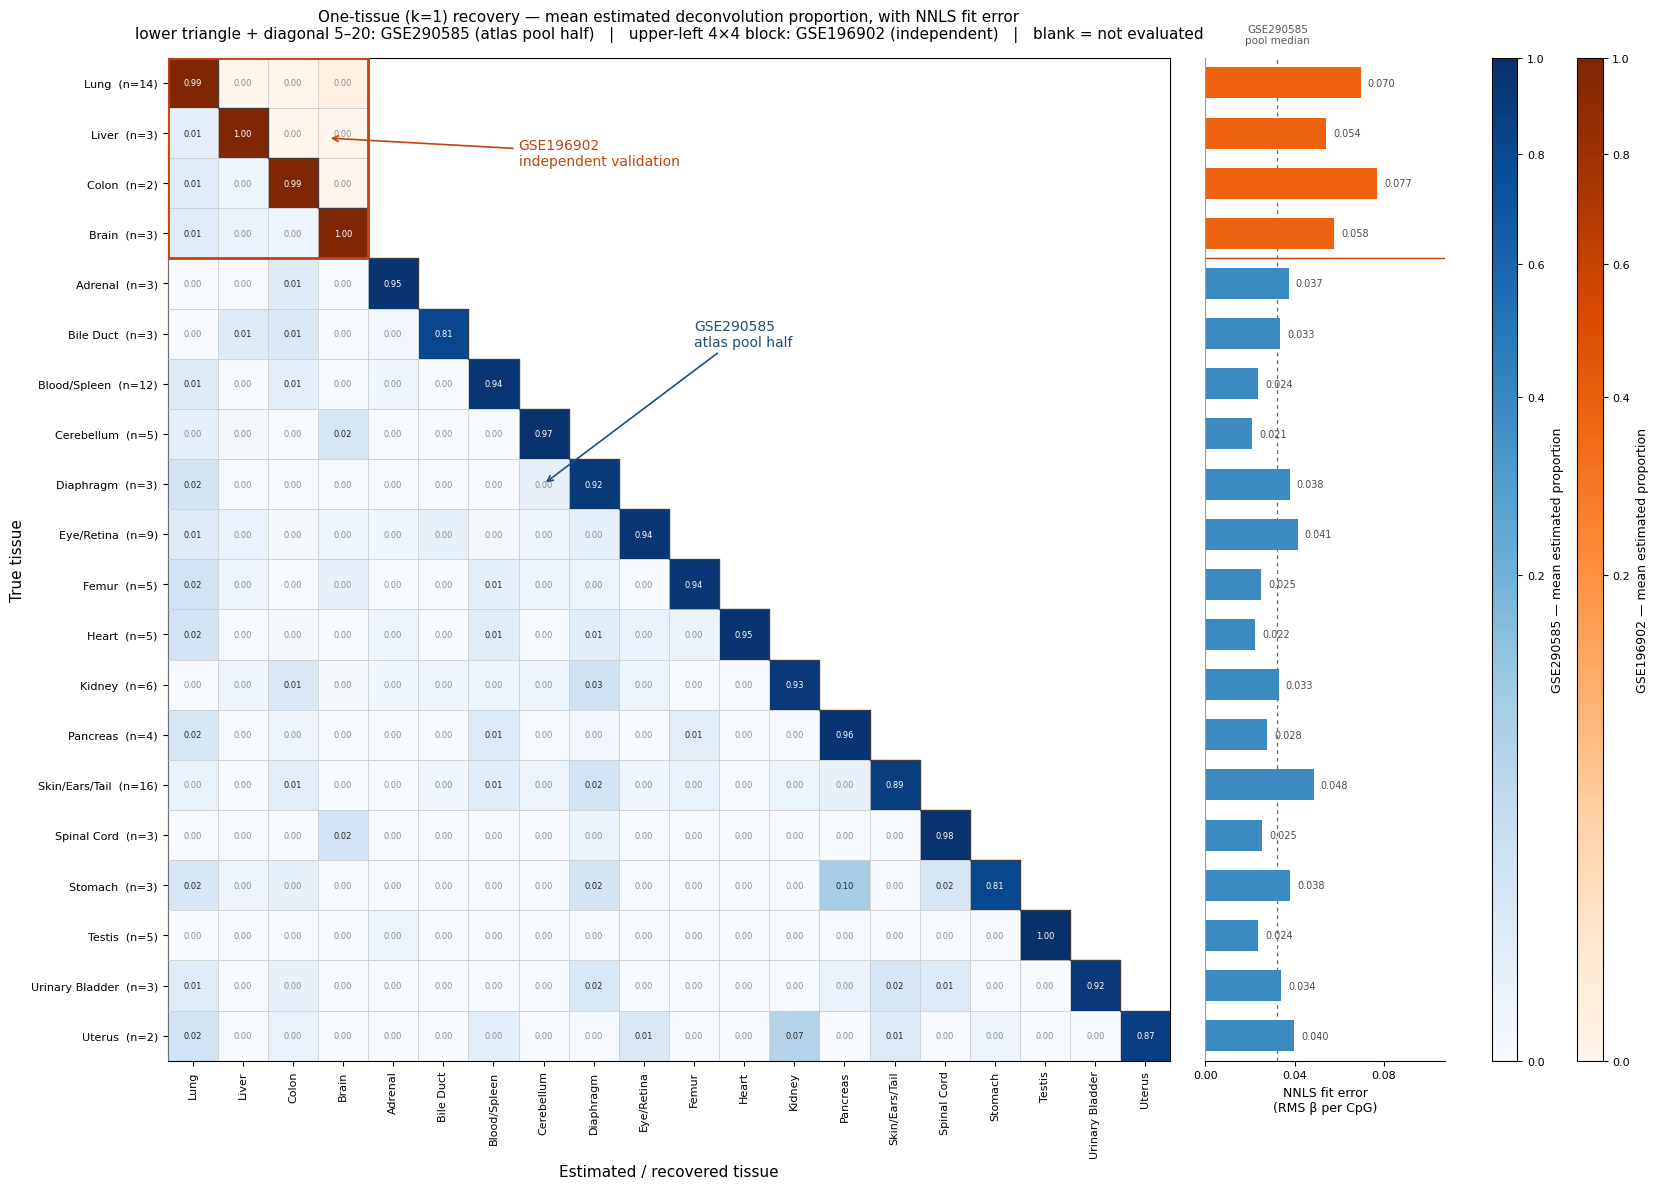


Focal tissues, both cohorts - recovered proportion and median RMS beta error per CpG

tissue                 recovered               fit error
            GSE196902  GSE290585   GSE196902   GSE290585   ratio
----------------------------------------------------------------
Lung            0.993      0.980      0.0695      0.0235   2.95x
Liver           1.000      0.965      0.0541      0.0277   1.95x
Colon           0.994      0.881      0.0768      0.0573   1.34x
Brain           1.000      0.851      0.0575      0.0376   1.53x


In [51]:
# ---- Draw, save, report ------------------------------------------------------
TITLE_RECOVERY_FIT = (
    "One-tissue (k=1) recovery — mean estimated deconvolution proportion, with NNLS fit error\n"
    "lower triangle + diagonal 5–20: GSE290585 (atlas pool half)   |   "
    "upper-left 4×4 block: GSE196902 (independent)   |   blank = not evaluated"
)

fig = plot_recovery_map(
    A, B, ORDER, N_FOCAL,
    row_n_a=N29, row_n_b=N19,
    title=TITLE_RECOVERY_FIT,
    output_paths=None,                     # saved below, once the strip is in
)
add_fit_strip(fig, FIT, N_FOCAL, fit_ref=FIT_REF)

if SAVE_FIGURES:
    for ext in RECOVERY_FIG_FORMATS:
        path = FIG_DIR / f"{FIT_STEM}.{ext}"
        fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
        print(f"Figure saved -> {path.relative_to(config.PROJECT_ROOT)}")
plt.show()


# ---- Like-for-like: the focal four, both cohorts -------------------------------
# The map shows only GSE196902 on these rows. Same tissues, same W, same probes - so this is
# the one direct comparison between the cohorts.
print("\nFocal tissues, both cohorts - recovered proportion and median RMS beta error per CpG\n")
print(f"{'tissue':<10}{'recovered':>22}{'fit error':>24}")
print(f"{'':<10}{'GSE196902':>11}{'GSE290585':>11}{'GSE196902':>12}{'GSE290585':>12}{'ratio':>8}")
print("-" * 64)
for t in TISSUES_4:
    e19, e29 = rms19.loc[[t]].median(), rms29.loc[[t]].median()
    print(f"{display_name(t):<10}{M19.loc[t, t]:>11.3f}{M29.loc[t, t]:>11.3f}"
          f"{e19:>12.4f}{e29:>12.4f}{e19 / e29:>7.2f}x")

---

## II.9 cfDNA-hard: selected mixtures on a log scale, with per-mixture residuals

Rebuilds the src **cfDNA-hard** regime (`run_deconvolution.py --regimes cfdna_hard`) 1:1: same
split, same reference-half probe selection and W, same mixture seed, same barplot selection seed.
This is src's W, **not** the `SHARED`-probe W of sections II.1–II.8, so every object here is prefixed
`_src` / `hard_`.

Two additions over `hard/selected_barplots`:

- **Log y-axis.** src hard-codes `ylim(0, 1)`; a log axis needs a positive floor (`LOG_YMIN`).
  Bars below the floor (including a true 0 next to a non-zero prediction) are not drawn.
- **Per-mixture residuals.** `hard/eval_residuals` is a histogram of one NNLS residual *norm per
  mixture* over all 1000 mixtures. For a single mixture the distribution is over probes:
  `r = x − W·c`, with `c` the raw NNLS coefficients (before src rescales them to sum to 1), so
  `‖r‖` is exactly the residual src reports for that mixture.

Mixtures 436 and 855 are two of the ten panels in `hard/selected_barplots`. Figures go to
`figures/publication/cfdna_hard/` as `selected_barplots_log`, `<mixture_id>_barplot` and
`<mixture_id>_residuals`.

In [52]:
# ---- cfDNA-hard configuration ------------------------------------------------
# Rebuilds the src cfDNA-hard regime 1:1 (run_deconvolution.py --regimes cfdna_hard).
# Everything here is prefixed _src / hard_ : sections II.1-II.8 use a different W (the SHARED
# probe list).
import diff_analysis
import deconv_regimes
from scipy.optimize import nnls
from IPython.display import display

HARD_REGIME  = "cfdna_hard"
HARD_CFG     = deconv_regimes.REGIMES[HARD_REGIME]
MIXTURE_IDS  = ["mixture_436", "mixture_855"]   # panels picked from hard/selected_barplots
LOG_YMIN     = 1e-3                             # log-axis floor; values below are not drawn
HARD_FIG_DIR = config.FIGURES_DIR / "publication" / "cfdna_hard"

# the ten panels in the current src figure hard/selected_barplots.*
EXPECTED_SELECTED = [f"mixture_{i}" for i in (85, 88, 94, 201, 430, 436, 649, 695, 767, 855)]

In [53]:
# ---- src steps 1-5 (run_deconvolution._run_shared_setup, minus its plots) ----
# Same calls, same config values. The reference heatmap / atlas-correlation plots are
# skipped, so figures/deconvolution/reference/ is untouched. load_deconv_data rewrites
# results/deconvolution/split.json - same seed, same content. verbose=False only silences
# create_heatmap_matrix's region counts; it does not change the selection.
with contextlib.redirect_stdout(io.StringIO()):
    (df_raw_src, ref_cols_src, pool_cols_src,
     labels_src, label_map_src) = deconv_data.load_deconv_data(
        reference_fraction=config.DECONV_REFERENCE_FRACTION,
        split_seed=config.DECONV_SPLIT_SEED,
    )

    # probe selection sees reference-half centroids only
    centroids_src = build_centroids(
        df_raw=df_raw_src,
        sample_cols=ref_cols_src,
        original_labels=labels_src,
        merge_groups=data_loading.MERGE_GROUPS,
    )
    diff_src = diff_analysis.build_tissue_diff_table(
        df=centroids_src, use_filtering=config.USE_FILTERING)
    top_src = diff_analysis.extract_top_regions(diff_src, top_n=config.TOP_N)
    heat_src, _ = diff_analysis.create_heatmap_matrix(
        df=centroids_src,
        df_top_regions=top_src,
        region_mode=config.REGION_MODE,
        max_per_tissue=config.MAX_PER_TISSUE,
        verbose=False,
    )
    probes_src = heat_src.columns.tolist()

    W_src = deconv_data.build_reference_matrix(
        df_raw=df_raw_src,
        reference_cols=ref_cols_src,
        original_labels=labels_src,
        selected_probes=probes_src,
    )
    eligible_src = deconv_data.get_eligible_tissues(
        pool_cols=pool_cols_src,
        original_labels=labels_src,
        label_map=label_map_src,
        min_pool_replicates=config.DECONV_MIN_POOL_REPLICATES,
    )

assert not (set(ref_cols_src) & set(pool_cols_src)), "reference and pool overlap - leakage"
print(f"W_src: {W_src.shape[0]} probes x {W_src.shape[1]} tissues | "
      f"{len(eligible_src)} eligible tissues")

W_src: 1000 probes x 20 tissues | 19 eligible tissues


In [54]:
# ---- cfDNA-hard mixtures, deconvolution, panel selection ---------------------
# deconv_regimes.run_regime steps 6-8 and its barplot selection, same seeds.
hard_seed = config.DECONV_MIXTURE_SEED + deconv_regimes._SEED_OFFSET[HARD_REGIME]

with contextlib.redirect_stdout(io.StringIO()):
    X_hard, true_hard = deconv_regimes.generate_blood_dominant_mixtures(
        df_raw=df_raw_src,
        pool_cols=pool_cols_src,
        original_labels=labels_src,
        label_map=label_map_src,
        selected_probes=probes_src,
        eligible_tissues=eligible_src,
        regime_cfg=HARD_CFG,
        n_mixtures=config.DECONV_N_MIXTURES,
        random_state=hard_seed,
    )
    deconv_data.validate_mixtures(X_hard, true_hard)      # asserts; output silenced
    est_hard, res_hard = deconv_model.deconvolve_batch(W_src, X_hard)

# cfDNA regimes: k_total = 1 blood + k_nb non-blood
selected_hard = deconv_model.select_random_k_mixtures(
    df_proportions=true_hard,
    k_min=HARD_CFG["k_nb_min"] + 1,
    k_max=HARD_CFG["k_nb_max"] + 1,
    n_plots=config.DECONV_BARPLOT_N_PLOTS,
    random_seed=config.DECONV_BARPLOT_SEED,
)

assert selected_hard == EXPECTED_SELECTED, f"selection differs from src figure: {selected_hard}"
assert set(MIXTURE_IDS) <= set(selected_hard), "MIXTURE_IDS not among the src panels"
print(f"{len(X_hard)} hard mixtures | median NNLS residual {np.median(res_hard):.4f}")
print(f"selected panels match src: {selected_hard}")

1000 hard mixtures | median NNLS residual 0.6585
selected panels match src: ['mixture_85', 'mixture_88', 'mixture_94', 'mixture_201', 'mixture_430', 'mixture_436', 'mixture_649', 'mixture_695', 'mixture_767', 'mixture_855']


In [55]:
# ---- Helpers -----------------------------------------------------------------
# src draws every figure; _save_or_close is patched to a no-op so the figure survives
# (same pattern as plot_scenario), then only what src cannot express is changed.

def _draw_with_src(plot_fn, **kwargs):
    """Run a deconv_model plot function and return its figure instead of closing it."""
    keep = {}
    original = deconv_model._save_or_close
    deconv_model._save_or_close = lambda output_path=None, dpi=150: keep.setdefault("f", plt.gcf())
    try:
        plot_fn(**kwargs)
    finally:
        deconv_model._save_or_close = original
    return keep["f"]


def _save(fig, output_path, dpi=None):
    """dpi only applies to raster formats, matching src/deconv_model._save_or_close."""
    if SAVE_FIGURES and output_path is not None:
        output_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(output_path, dpi=FIG_DPI if dpi is None else dpi, bbox_inches="tight")
        print(f"Figure saved -> {output_path.relative_to(config.PROJECT_ROOT)}")


def plot_barplots_log(mixture_ids, title, output_path=None, ymin=LOG_YMIN):
    """deconv_model.plot_selected_mixture_barplots with a log y-axis.

    src hard-codes ylim(0, 1); a log axis needs a positive floor. Bars below `ymin`
    (including a true 0 next to a non-zero prediction) are not drawn.
    """
    fig = _draw_with_src(
        deconv_model.plot_selected_mixture_barplots,
        df_proportions=true_hard,
        df_estimated=est_hard,
        mixture_ids=mixture_ids,
        title=title,
    )
    for ax in fig.axes:
        if ax.get_visible():
            ax.set_yscale("log")
            ax.set_ylim(ymin, 1)
            ax.set_ylabel("Proportion (log)", fontsize=9)
    _save(fig, output_path)
    return fig


def per_probe_residual(mix_id):
    """Observed minus fitted beta per probe, x - W @ c, for one hard mixture.

    c are the raw NNLS coefficients (before src rescales them to sum to 1), so
    ||x - W @ c|| is exactly the residual deconvolve_batch reported.
    """
    i = int(mix_id.split("_")[1])
    assert true_hard.index[i] == mix_id, f"{mix_id} is not row {i}"
    coeffs, _ = nnls(W_src.values, X_hard[i])
    r = X_hard[i] - W_src.values @ coeffs
    assert np.isclose(np.linalg.norm(r), res_hard[i]), f"{mix_id}: residual norm differs from src"
    return pd.Series(r, index=W_src.index, name=mix_id)


def plot_mixture_residuals(mix_id, output_path=None):
    """deconv_model.plot_residual_distribution on one mixture's per-probe residuals."""
    r = per_probe_residual(mix_id)
    fig = _draw_with_src(
        deconv_model.plot_residual_distribution,
        residuals=r.values,
        title=(f"Per-probe NNLS residual — {mix_id} — regime: {HARD_CFG['label']}\n"
               f"{len(r)} probes, ‖r‖ = {np.linalg.norm(r):.4f}"),
    )
    fig.axes[0].set_xlabel("Per-probe residual (β, observed − fitted)")
    _save(fig, output_path)
    return fig, r


print("helpers ready — src draws, we only change the y-scale / x-label")

helpers ready — src draws, we only change the y-scale / x-label


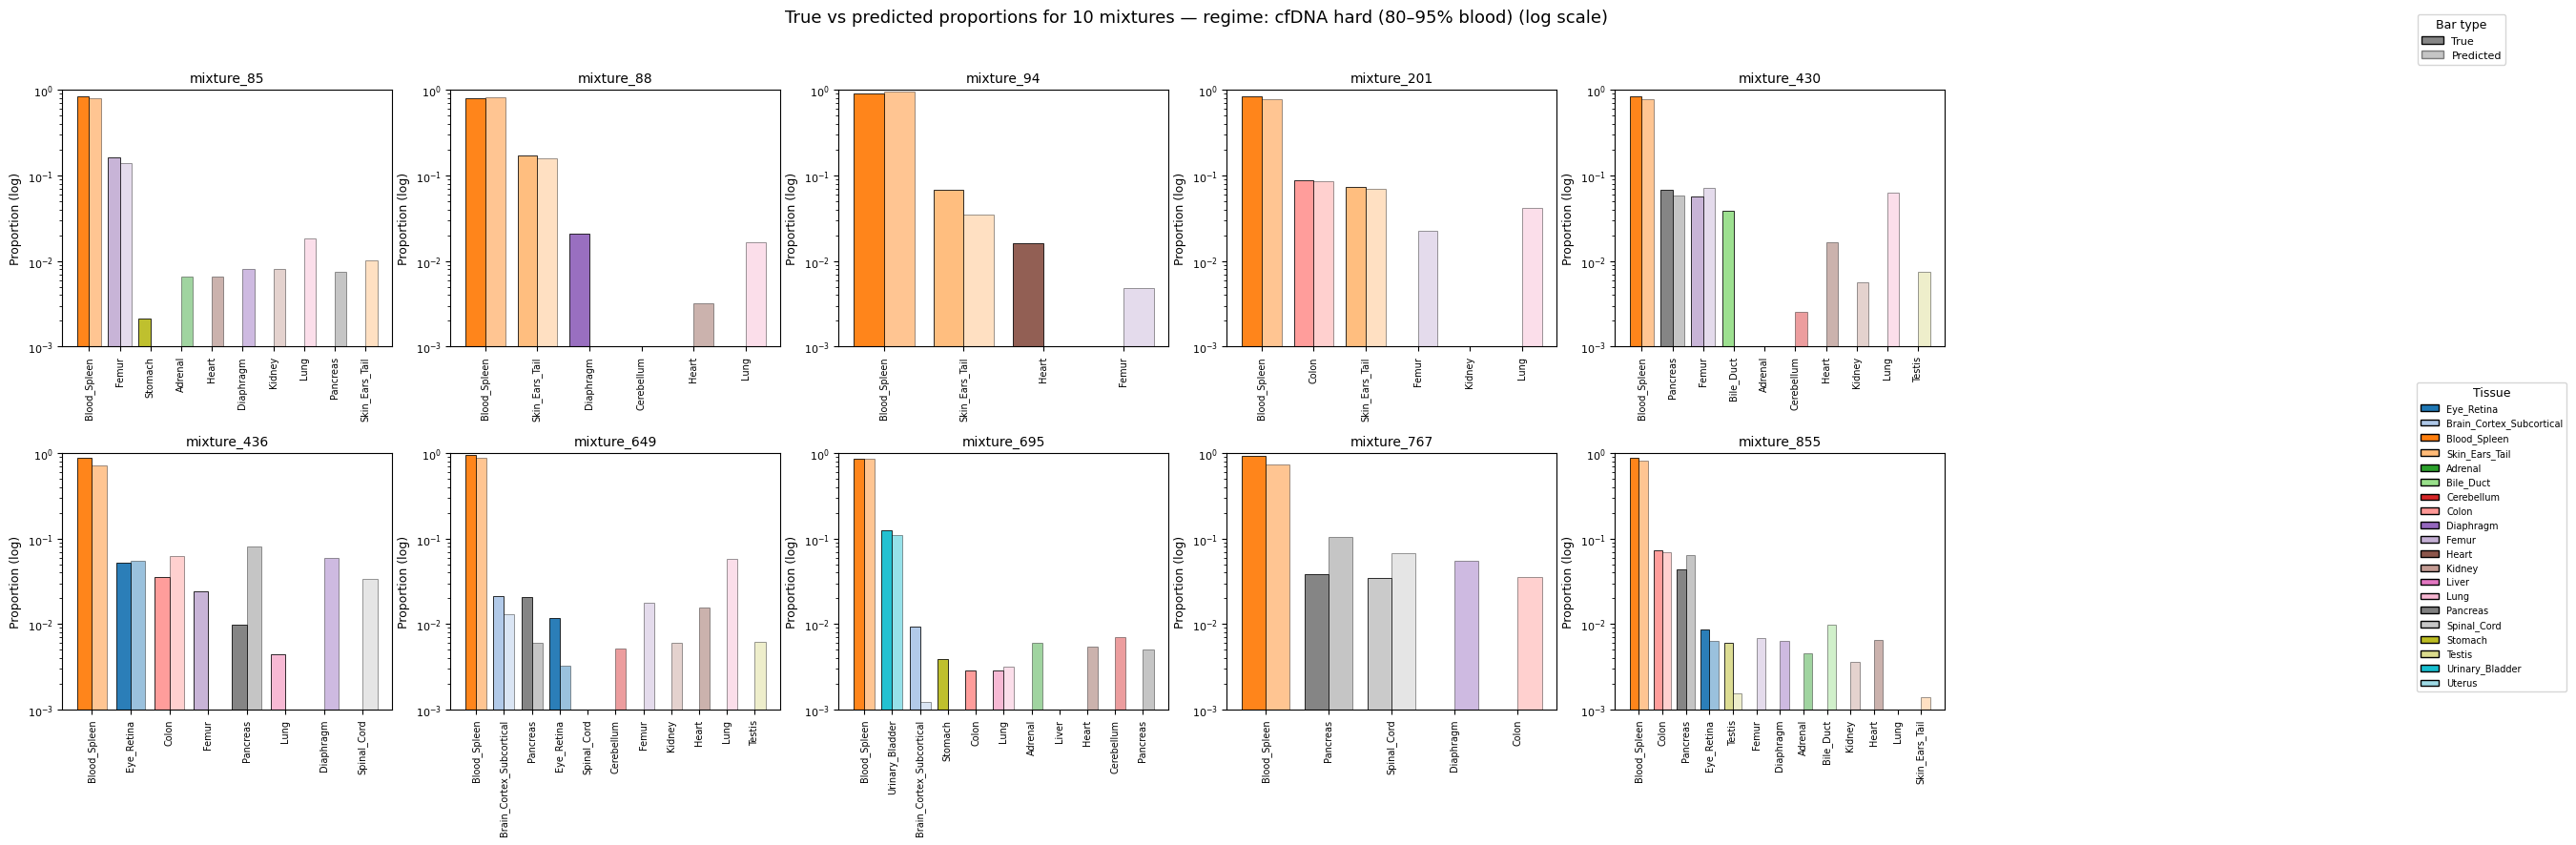

In [56]:
# ---- All ten src panels, log y -----------------------------------------------
fig = plot_barplots_log(
    selected_hard,
    title=(f"True vs predicted proportions for {len(selected_hard)} mixtures "
           f"— regime: {HARD_CFG['label']} (log scale)"),
    output_path=HARD_FIG_DIR / f"selected_barplots_log.{FIG_FORMAT}",
)
display(fig)
plt.close(fig)

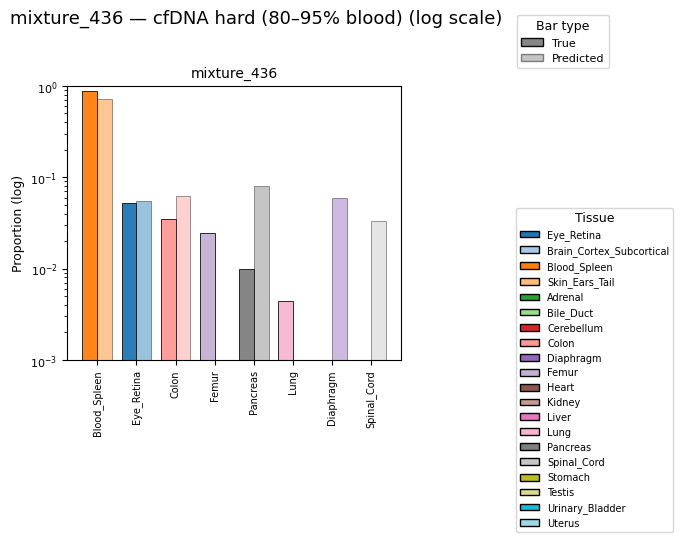

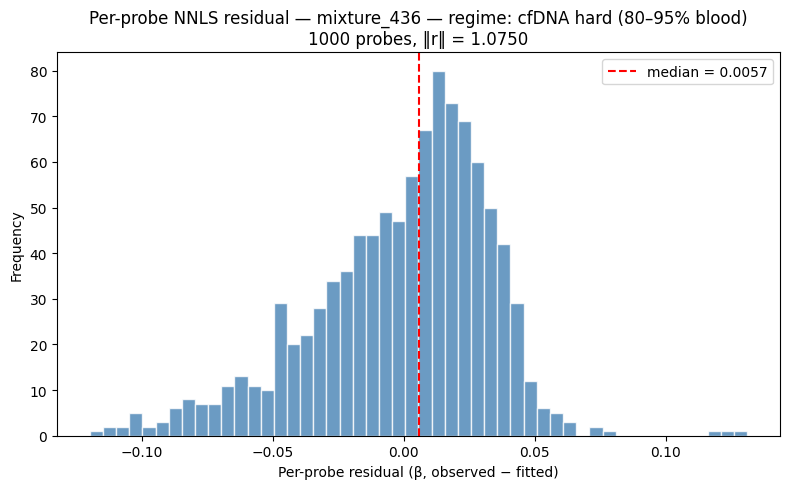

mixture_436: ‖r‖ = 1.0750 | median r = +0.0057 | |r| > 0.1 on 13 of 1000 probes
                true  estimated   error
Blood_Spleen  0.8738     0.7102 -0.1636
Eye_Retina    0.0525     0.0547  0.0022
Colon         0.0352     0.0620  0.0269
Femur         0.0243     0.0000 -0.0243
Pancreas      0.0098     0.0809  0.0711
Lung          0.0044     0.0000 -0.0044
Diaphragm     0.0000     0.0588  0.0588
Spinal_Cord   0.0000     0.0333  0.0333



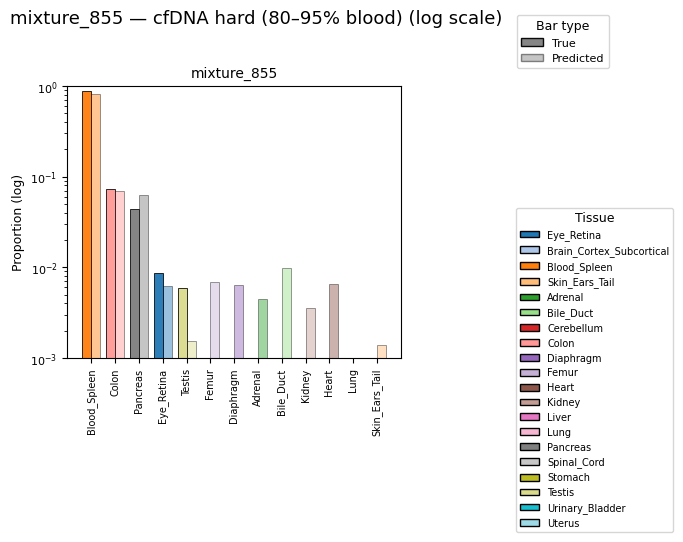

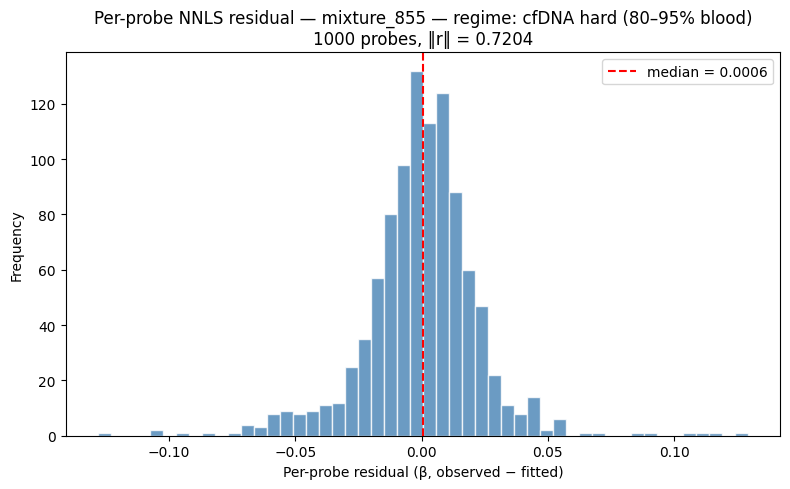

mixture_855: ‖r‖ = 0.7204 | median r = +0.0006 | |r| > 0.1 on 7 of 1000 probes
                  true  estimated   error
Blood_Spleen    0.8686     0.8196 -0.0490
Colon           0.0728     0.0700 -0.0028
Pancreas        0.0436     0.0633  0.0197
Eye_Retina      0.0086     0.0063 -0.0023
Testis          0.0060     0.0016 -0.0044
Femur           0.0004     0.0069  0.0066
Diaphragm       0.0000     0.0064  0.0064
Adrenal         0.0000     0.0045  0.0045
Bile_Duct       0.0000     0.0097  0.0097
Kidney          0.0000     0.0036  0.0036
Heart           0.0000     0.0065  0.0065
Lung            0.0000     0.0002  0.0002
Skin_Ears_Tail  0.0000     0.0014  0.0014



In [57]:
# ---- Mixtures 436 and 855: log barplot + per-probe residuals ----------------
for mix_id in MIXTURE_IDS:
    fig = plot_barplots_log(
        [mix_id],
        title=f"{mix_id} — {HARD_CFG['label']} (log scale)",
        output_path=HARD_FIG_DIR / f"{mix_id}_barplot.{FIG_FORMAT}",
    )
    display(fig)
    plt.close(fig)

    fig, r = plot_mixture_residuals(
        mix_id,
        output_path=HARD_FIG_DIR / f"{mix_id}_residuals.{FIG_FORMAT}",
    )
    display(fig)
    plt.close(fig)

    # tissues present in truth or estimate, largest true share first
    tbl = pd.DataFrame({"true": true_hard.loc[mix_id], "estimated": est_hard.loc[mix_id]})
    tbl = tbl[(tbl != 0).any(axis=1)].sort_values("true", ascending=False)
    tbl["error"] = tbl["estimated"] - tbl["true"]
    print(f"{mix_id}: ‖r‖ = {np.linalg.norm(r):.4f} | median r = {r.median():+.4f} | "
          f"|r| > 0.1 on {(r.abs() > 0.1).sum()} of {len(r)} probes")
    print(tbl.round(4).to_string())
    print()

### II.9b All hard mixtures pooled

The same per-probe residual `r = x − W·c` as above, for every cfDNA-hard mixture at once:
1000 mixtures × 1000 probes. Each mixture's residuals still have norm equal to its value in
`hard/eval_residuals` (asserted per row), so this is the per-probe view behind that per-mixture
histogram. Saved as `figures/publication/cfdna_hard/all_mixtures_residuals`.

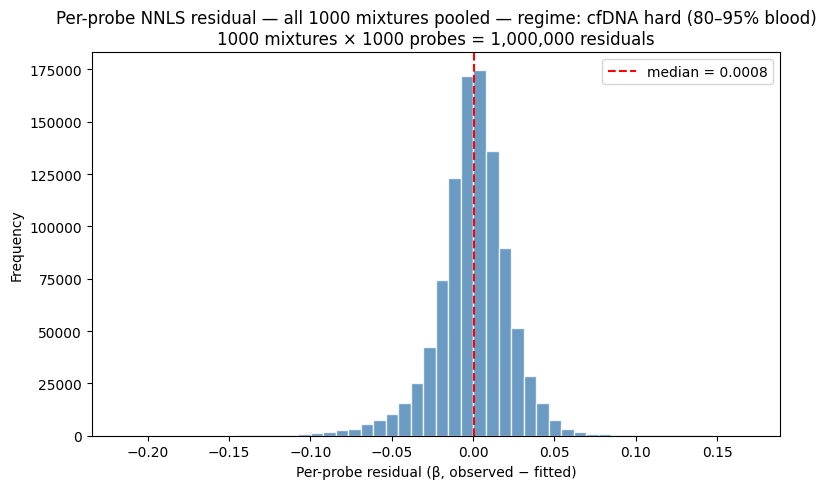

all 1000 mixtures: median r = +0.0008 | |r| > 0.1 on 0.37% of 1,000,000 residuals | 1st / 99th percentile = -0.0709 / +0.0527


In [58]:
# ---- Per-probe residuals, all hard mixtures pooled ---------------------------
# per_probe_residual asserts each row's norm == res_hard[i] (the src residual)
R_hard = pd.concat([per_probe_residual(m) for m in true_hard.index], axis=1).T   # mixtures x probes

fig = _draw_with_src(
    deconv_model.plot_residual_distribution,
    residuals=R_hard.to_numpy().ravel(),
    title=(f"Per-probe NNLS residual — all {len(R_hard)} mixtures pooled — "
           f"regime: {HARD_CFG['label']}\n"
           f"{R_hard.shape[0]} mixtures × {R_hard.shape[1]} probes = {R_hard.size:,} residuals"),
)
fig.axes[0].set_xlabel("Per-probe residual (β, observed − fitted)")
_save(fig, HARD_FIG_DIR / f"all_mixtures_residuals.{FIG_FORMAT}")
display(fig)
plt.close(fig)

# summary, comparable with the 436 / 855 lines above
r_all = R_hard.to_numpy().ravel()
p01, p99 = np.percentile(r_all, [1, 99])
print(f"all {len(R_hard)} mixtures: median r = {np.median(r_all):+.4f} | "
      f"|r| > 0.1 on {(np.abs(r_all) > 0.1).mean():.2%} of {r_all.size:,} residuals | "
      f"1st / 99th percentile = {p01:+.4f} / {p99:+.4f}")

# Part III. NNLS deconvolution of external mm10 datasets

Deconvolves four external mouse methylation datasets against the **full-atlas** reference W
(GSE290585, 1000 panel probes x 20 tissues) and collects every sample in one table:
rows = atlas tissues, columns = samples.

| Dataset | Assay | Samples | Row key |
|---|---|---|---|
| GSE42836  | WGBS              | 17   | `chr:pos`, strands merged |
| GSE106379 | WGBS (liver)      | 24   | `chr:pos`, strands merged |
| GSE93957  | RRBS (0.4X WGBS?) | 62   | `chr:pos`, **one row per strand** |
| GSE184410 | MM285 array       | 1239 | `ID_REF` (MM285 probe ID) |

None of these datasets contributed to the atlas, so W uses all atlas samples (no reference/pool
split), exactly as in Part I.

**Coordinate convention.** `chr:pos` is the 1-based position of the CpG's C on the + strand. In
the MM285 annotation (`CpG_beg` 0-based, `CpG_end` exclusive) that is `CpG_beg + 1`; the
minus-strand C sits on the G, at `CpG_beg + 2`. No BED conversion is needed, the annotation
returned by `data_loading.load_all()` already carries these columns.

In [59]:
# ---- Setup -------------------------------------------------------------------
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, HTML, SVG, Image

sys.path.insert(0, "../src")

import config
import data_loading
import deconv_data
import deconv_model
from utils import (
    extract_sample_labels,
    build_centroids,
    select_probes_from_centroids,
)

EXT_DIR   = config.DATA_DIR / "external" / "Meth_mice"
META_PATH = EXT_DIR / "GEO_mouse_methylation_metadata.xlsx"   # one sheet per GSE

# key: "coord" -> rows keyed by chr:pos (1-based C of the CpG), "probe" -> rows keyed by MM285 probe ID
DATASETS = {
    "GSE42836":  {"file": EXT_DIR / "GSE42836_CpG.BETA.mm10.txt",  "key": "coord"},   # WGBS, 17 tissues
    "GSE106379": {"file": EXT_DIR / "GSE106379_CpG.BETA.mm10.txt", "key": "coord"},   # WGBS, liver
    "GSE93957":  {"file": EXT_DIR / "GSE93957_CpG.BETA.mm10.txt",  "key": "coord"},   # RRBS, strand-split
    "GSE184410": {"file": EXT_DIR / "GSE184410_CpG.BETA.mm10.txt", "key": "probe"},   # MM285 array
}

# NaN QC thresholds (provisional, revisit once the QC tables below have been inspected)
MIN_SAMPLE_COVERAGE = 0.1    # fraction of panel probes a sample must have non-NaN
MAX_PROBE_MISSING   = 1.0    # max NaN fraction of a probe across a dataset's QC-passing samples
# MAX_PROBE_MISSING EXPLANATION:
# 0.0 = Identical probe set for all samples: only probes present in every passing sample. This is the only setting that gives all samples the same probe set.
# 0.5 = (Slightly) different probe set for all samples, but probes missing in most samples are removed.
# 1.0 (filter off) = Different probe set for each sample, and each sample uses everything it has. This gives the widest spread and the most probes per sample.



# The input files are 1.4-3.5 GB. They are read in chunks of roughly this many cells
# (rows x columns), keeping only panel rows, so no file is ever fully in memory.
CHUNK_CELLS = 50_000_000

# Write tables to OUT_DIR only when set to True
SAVE_QC      = True
SAVE_RESULTS = True

OUT_DIR  = config.DECONV_OUTPUT_DIR / "validation_publication"
FIG_DIR  = config.FIGURES_DIR / "publication" / "external_datasets"
FMT, DPI = config.FIGURE_FORMAT, config.FIGURE_DPI

if SAVE_FIGURES:
    FIG_DIR.mkdir(parents=True, exist_ok=True)


def show_table(df: pd.DataFrame, max_height: int = 420, float_format=None) -> None:
    """Display df as an HTML table that scrolls in both directions, header row kept visible."""
    float_format = float_format or "{:.3f}".format
    html = df.to_html(float_format=float_format, na_rep="NaN", index_names=False,
                      classes="scroll-tbl")
    display(HTML(
        "<style>table.scroll-tbl thead th {position: sticky; top: 0; z-index: 1;"
        " background: var(--vscode-editor-background, white);}</style>"
        f"<div style='max-height:{max_height}px; overflow:auto'>{html}</div>"
    ))

print(f"figures -> {FIG_DIR.relative_to(config.PROJECT_ROOT)}")
print(f"tables  -> {OUT_DIR.relative_to(config.PROJECT_ROOT)}  (SAVE_QC={SAVE_QC}, SAVE_RESULTS={SAVE_RESULTS})")

figures -> figures/publication/external_datasets
tables  -> results/deconvolution/validation_publication  (SAVE_QC=True, SAVE_RESULTS=True)


## III.1 Reference matrix W

Built from all GSE290585 samples (excluded tissues removed), identical to
section I.1. `df_annot` from `load_all()` is kept this time: it is the
probe -> coordinate map used in section III.2.

In [60]:
# ---- Build W from the full atlas ---------------------------------------------
df_atlas_raw, df_annot, _, _ = data_loading.load_all()

atlas_labels = extract_sample_labels(df_atlas_raw)
atlas_labels = atlas_labels[~atlas_labels.isin(data_loading.EXCLUDED_TISSUES)]
print(f"atlas samples used: {len(atlas_labels)} (excluded: {sorted(data_loading.EXCLUDED_TISSUES)})")

# merged tissue centroids over every remaining replicate
df_atlas_centroids = build_centroids(
    df_raw=df_atlas_raw,
    sample_cols=atlas_labels.index.tolist(),
    original_labels=atlas_labels,
    merge_groups=data_loading.MERGE_GROUPS,
)

# probe panel: top MAX_PER_TISSUE unique regions per tissue
panel_probes = select_probes_from_centroids(df_atlas_centroids)

W_full = df_atlas_centroids.set_index("probe_ID").loc[panel_probes]
print(f"\nW_full: {W_full.shape[0]} probes x {W_full.shape[1]} tissues")

atlas samples used: 240 (excluded: ['Mammary_Glands', 'Optic_Nerve', 'Sciatic_Nerve', 'Thymus'])



W_full: 1000 probes x 20 tissues


In [61]:
# ---- Validate W --------------------------------------------------------------
cond_number = deconv_data.validate_reference(W_full)

Condition number of W: 94.6

Per-tissue beta value summary (across selected probes):
                              mean       std       min       max
Eye_Retina                0.832799  0.139477  0.167157  0.973786
Brain_Cortex_Subcortical  0.842054  0.098701  0.448927  0.979264
Blood_Spleen              0.869258  0.103455  0.119894  0.976814
Skin_Ears_Tail            0.808759  0.108548  0.331568  0.975861
Adrenal                   0.835692  0.106930  0.286000  0.976167
Bile_Duct                 0.838123  0.068678  0.510167  0.975833
Cerebellum                0.843233  0.164169  0.137778  0.985111
Colon                     0.812228  0.103847  0.388455  0.975818
Diaphragm                 0.817050  0.081086  0.505500  0.969833
Femur                     0.798713  0.090799  0.242800  0.972000
Heart                     0.857983  0.075740  0.488000  0.979300
Kidney                    0.833935  0.099152  0.373917  0.979167
Liver                     0.844082  0.130390  0.238538  0.980308
Lung 

In [62]:
# ---- Cross-check against the saved atlas panel (optional sanity check) -------
# W_full should equal top_50_regions_df.csv transposed. A mismatch is not an error:
# it means config.py has changed since that file was last written.
saved_path = config.DECONV_ATLAS_PROBES_PATH
if saved_path.exists():
    saved = pd.read_csv(saved_path, index_col=0).T
    probes  = W_full.index.intersection(saved.index)
    tissues = W_full.columns.intersection(saved.columns)
    if len(probes) and len(tissues):
        diff = (W_full.loc[probes, tissues] - saved.loc[probes, tissues]).abs().to_numpy().max()
        print(f"shared with saved panel: {len(probes)} probes x {len(tissues)} tissues")
        print(f"max |difference|: {diff:.2e}"
              + ("  — identical" if diff < 1e-9 else "  ⚠ config.py has changed since that file was written"))
    else:
        print("⚠ no overlap with the saved panel — probe selection has changed substantially")
else:
    print(f"saved panel not found at DATA_DIR/{saved_path.relative_to(config.DATA_DIR)}, skipping cross-check")

shared with saved panel: 1000 probes x 20 tissues
max |difference|: 1.11e-16  — identical


## III.2 Bring all datasets onto the panel's probe_ID index

**Coordinate -> probe keys.** Two keys per panel probe: `chr:CpG_beg+1` (+ strand C) and
`chr:CpG_beg+2` (- strand C). One rule covers both file layouts: in strand-merged files the
`CpG_beg+2` position is a G and never appears, while in GSE93957 both strands are picked up and
averaged per probe. A few panel probes share a CpG with another panel probe; the merge below gives
each of them the same beta.

**Loader.** Each file is read in chunks and only panel rows are kept. The result is a
probes x samples block reindexed to `W_full.index`, so probes absent from a file are NaN rows,
handled by the QC in section III.3, not here.

In [63]:
# ---- Coordinate -> probe key table (panel probes only) -----------------------
annot_panel = df_annot.set_index("Probe_ID").loc[W_full.index, ["CpG_chrm", "CpG_beg", "target"]]

# every panel probe must be a CG probe, otherwise CpG_beg+1 / +2 are not the two strand Cs
assert (annot_panel["target"] == "CG").all(), "non-CG probe in the panel — key rule does not apply"

beg = annot_panel["CpG_beg"].astype(int)
df_keys = pd.concat(
    [
        pd.DataFrame({"key":      (annot_panel["CpG_chrm"] + ":" + (beg + 1).astype(str)).to_numpy(),
                      "probe_ID": annot_panel.index.to_numpy(),
                      "strand":   "+"}),
        pd.DataFrame({"key":      (annot_panel["CpG_chrm"] + ":" + (beg + 2).astype(str)).to_numpy(),
                      "probe_ID": annot_panel.index.to_numpy(),
                      "strand":   "-"}),
    ],
    ignore_index=True,
)

n_shared_cpg = int(df_keys[df_keys["strand"] == "+"]["key"].duplicated(keep=False).sum())
print(f"keys: {len(df_keys)} ({df_keys['probe_ID'].nunique()} probes x 2 strands)")
print(f"panel probes sharing a CpG with another panel probe: {n_shared_cpg}")

keys: 2000 (1000 probes x 2 strands)
panel probes sharing a CpG with another panel probe: 10


In [64]:
# ---- Panel-only loader -------------------------------------------------------
def load_panel_block(path: Path, key: str, df_keys: pd.DataFrame, panel_probes,
                     chunk_cells: int = CHUNK_CELLS) -> pd.DataFrame:
    '''
    Read one external beta file and return its panel rows as a probes x samples block.

    Parameters
    ----------
    path : Path
        Tab-separated beta file. First column is the row key; an optional "context" column
        is ignored; every other column is one sample.
    key : {"coord", "probe"}
        "coord": first column is chr:pos, mapped to probe IDs through df_keys.
        "probe": first column is already the MM285 probe ID.
    df_keys : pd.DataFrame
        key / probe_ID / strand table from the previous cell.
    panel_probes : list-like
        Panel probe IDs; the returned block is reindexed to exactly this order.

    Returns
    -------
    pd.DataFrame
        Index = panel_probes (NaN rows for probes absent from the file), columns = samples.
    '''
    header      = pd.read_csv(path, sep="\t", nrows=0).columns.tolist()
    id_col      = header[0]
    sample_cols = [c for c in header[1:] if c != "context"]
    assert len(sample_cols) == len(set(sample_cols)), f"duplicate sample columns in {path.name}"

    wanted    = set(df_keys["key"]) if key == "coord" else set(panel_probes)
    chunksize = max(1, chunk_cells // len(header))

    kept = []
    for chunk in pd.read_csv(path, sep="\t", usecols=[id_col] + sample_cols,
                             dtype={id_col: str}, na_values="NA", chunksize=chunksize):
        kept.append(chunk[chunk[id_col].isin(wanted)])
    df_hits = pd.concat(kept, ignore_index=True)
    assert df_hits[id_col].is_unique, f"duplicate row keys among panel rows of {path.name}"

    if key == "coord":
        # inner merge: one row per (file row, probe); a shared CpG fans out to each of its probes
        df_hits = df_hits.merge(df_keys, left_on=id_col, right_on="key", how="inner")
        n_plus  = df_hits.loc[df_hits["strand"] == "+", "probe_ID"].nunique()
        n_minus = df_hits.loc[df_hits["strand"] == "-", "probe_ID"].nunique()
        print(f"  rows matched: + strand {n_plus} probes, - strand {n_minus} probes")
        # average the two strands per probe (skipna: a single strand is used as is)
        block = df_hits.groupby("probe_ID")[sample_cols].mean()
    else:
        block = df_hits.set_index(id_col)[sample_cols]

    print(f"  panel probes in file: {len(block)}/{len(panel_probes)}  |  samples: {len(sample_cols)}")

    block = block.reindex(panel_probes)
    lo, hi = np.nanmin(block.to_numpy()), np.nanmax(block.to_numpy())
    assert 0.0 <= lo and hi <= 1.0, f"beta values out of range in {path.name}: [{lo}, {hi}]"
    return block

In [65]:
# ---- Load every dataset --------------------------------------------------------
blocks = {}
for gse, spec in DATASETS.items():
    print(f"{gse}  ({spec['file'].name})")
    blocks[gse] = load_panel_block(spec["file"], spec["key"], df_keys, W_full.index)

GSE42836  (GSE42836_CpG.BETA.mm10.txt)


  rows matched: + strand 977 probes, - strand 0 probes
  panel probes in file: 977/1000  |  samples: 17
GSE106379  (GSE106379_CpG.BETA.mm10.txt)


  rows matched: + strand 980 probes, - strand 0 probes
  panel probes in file: 980/1000  |  samples: 24
GSE93957  (GSE93957_CpG.BETA.mm10.txt)


  rows matched: + strand 97 probes, - strand 94 probes
  panel probes in file: 97/1000  |  samples: 62
GSE184410  (GSE184410_CpG.BETA.mm10.txt)


  panel probes in file: 972/1000  |  samples: 1239


In [66]:
# ---- Sample metadata -----------------------------------------------------------
# Each dataset names its columns differently; one rule per dataset maps a column to its
# metadata row. Every column must match exactly one row.
meta_book = pd.ExcelFile(META_PATH)

def column_key(gse: str, meta: pd.DataFrame) -> pd.Series:
    '''Series of strings, aligned to meta's rows, equal to that sample's column name.'''
    if gse == "GSE42836":     # column = tissue with spaces as underscores ("bone_marrow")
        return meta["tissue"].str.replace(" ", "_")
    if gse == "GSE106379":    # column = title ("B6_M_1")
        return meta["title"]
    if gse == "GSE93957":     # column = supplementary file without GSM prefix and suffix
        return (meta["supplementary_file"].str.split("_", n=1).str[1]
                .str.replace(r"\.cov\.txt\.gz$", "", regex=True))
    if gse == "GSE184410":    # column = array position ("204875570025_R03C01")
        return meta["array_position"]
    raise KeyError(gse)

META_COLS = ["gsm", "title", "tissue", "pathology", "experiment_group"]

meta_rows = []
for gse, block in blocks.items():
    meta = meta_book.parse(gse)
    meta = meta.assign(_col=column_key(gse, meta).to_numpy())
    assert meta["_col"].is_unique, f"{gse}: metadata keys not unique"

    unmatched = sorted(set(block.columns) - set(meta["_col"]))
    assert not unmatched, f"{gse}: {len(unmatched)} columns without metadata, e.g. {unmatched[:3]}"

    meta = meta.set_index("_col").loc[block.columns].reindex(columns=META_COLS)
    meta.insert(0, "dataset", gse)
    meta.index = [f"{gse}|{c}" for c in block.columns]
    meta_rows.append(meta)

    # "<GSE>|<sample>" keeps sample names unique across datasets
    blocks[gse] = block.set_axis(meta.index, axis=1)

df_meta = pd.concat(meta_rows)
df_meta.index.name = "sample"
assert df_meta.index.is_unique

print(f"samples with metadata: {len(df_meta)}")
print(df_meta["dataset"].value_counts().reindex(DATASETS).to_string())

samples with metadata: 1342
dataset
GSE42836       17
GSE106379      24
GSE93957       62
GSE184410    1239


## III.3 NaN QC

Two filters, in this order:

1. **Samples**: keep a sample only if at least `MIN_SAMPLE_COVERAGE` of the 1000 panel probes are
   non-NaN in it.
2. **Probes**: per dataset, over that dataset's QC-passing samples, keep a probe only if its NaN
   fraction is at most `MAX_PROBE_MISSING`. Done per dataset because missingness is assay-driven
   (RRBS coverage differs completely from an array's).

Samples that fail are kept in every output table with `qc_pass = False` and NaN proportions.

**What the QC tables contain** (each is shown below and written to `OUT_DIR` when `SAVE_QC`):

| Table | One row per | Columns |
|---|---|---|
| `qc_samples` | sample (all 1342) | `n_present`, `coverage`, `qc_pass`, sample metadata |
| `qc_probes`  | panel probe x dataset (1000 x 4) | `n_samples_qc` (QC-passing samples in that dataset), `missing_rate` (NaN fraction over them), `keep` |
| `qc_summary` | dataset | samples, passing / failing, median / min / max coverage, probes kept |

**Coverage** = `n_present / 1000`: the fraction of the panel probes with a non-NaN beta in that
sample, measured before the probe filter. A dataset with no passing samples has
`n_samples_qc = 0`, `missing_rate = NaN` and `keep = False` for every probe.

**Empty vs 0.0 in the proportions table.** An empty cell (NaN) means the sample failed QC and
was never deconvolved. `0.0` means it was deconvolved and NNLS gave that tissue zero weight.

In [67]:
# ---- Per-sample coverage -------------------------------------------------------
n_panel = len(W_full)

qc_samples = pd.concat(
    [pd.DataFrame({"dataset": gse, "n_present": block.notna().sum()}) for gse, block in blocks.items()]
)
qc_samples.index.name = "sample"
qc_samples["coverage"] = qc_samples["n_present"] / n_panel
qc_samples["qc_pass"]  = qc_samples["coverage"] >= MIN_SAMPLE_COVERAGE

show_table(qc_samples.join(df_meta.drop(columns="dataset")))

,dataset,n_present,coverage,qc_pass,gsm,title,tissue,pathology,experiment_group
GSE42836|bone_marrow,GSE42836,487,0.487,True,GSM1051150,mouse bone marrow,bone marrow,NaN,NaN
GSE42836|cerebellum,GSE42836,669,0.669,True,GSM1051151,mouse cerebellum,cerebellum,NaN,NaN
GSE42836|colon,GSE42836,653,0.653,True,GSM1051152,mouse colon,colon,NaN,NaN
GSE42836|cortex,GSE42836,782,0.782,True,GSM1051153,mouse cortex,cortex,NaN,NaN
GSE42836|heart,GSE42836,394,0.394,True,GSM1051154,mouse heart,heart,NaN,NaN
GSE42836|intestine,GSE42836,694,0.694,True,GSM1051155,mouse intestine,intestine,NaN,NaN
GSE42836|kidney,GSE42836,352,0.352,True,GSM1051156,mouse kidney,kidney,NaN,NaN
GSE42836|liver,GSE42836,159,0.159,True,GSM1051157,mouse liver,liver,NaN,NaN
GSE42836|lung,GSE42836,524,0.524,True,GSM1051158,mouse lung,lung,NaN,NaN
GSE42836|olfactory_bulb,GSE42836,808,0.808,True,GSM1051159,mouse olfactory bulb,olfactory bulb,NaN,NaN


In [68]:
# ---- Per-probe missing rate (per dataset, QC-passing samples only) --------------
probe_rows = []
keep_probes = {}
for gse, block in blocks.items():
    passing = qc_samples.index[(qc_samples["dataset"] == gse) & qc_samples["qc_pass"]]
    if len(passing):
        missing = block[passing].isna().mean(axis=1)
    else:
        missing = pd.Series(np.nan, index=block.index)      # nothing to assess
    keep = missing <= MAX_PROBE_MISSING                     # NaN -> False
    keep_probes[gse] = block.index[keep].tolist()
    probe_rows.append(pd.DataFrame({
        "probe_ID":     block.index,
        "dataset":      gse,
        "n_samples_qc": len(passing),
        "missing_rate": missing.to_numpy(),
        "keep":         keep.to_numpy(),
    }))

qc_probes = pd.concat(probe_rows, ignore_index=True)

show_table(qc_probes)

,probe_ID,dataset,n_samples_qc,missing_rate,keep
0,cg46037634_TC11,GSE42836,17,0.353,True
1,cg45190349_TC11,GSE42836,17,0.706,True
2,cg30114922_TC11,GSE42836,17,0.235,True
3,cg45888439_TC11,GSE42836,17,0.412,True
4,cg43303701_TC11,GSE42836,17,0.235,True
5,cg31153580_TC11,GSE42836,17,0.118,True
6,cg38472839_TC21,GSE42836,17,0.588,True
7,cg43753330_TC11,GSE42836,17,0.235,True
8,cg44021726_TC21,GSE42836,17,0.647,True
9,cg38576506_BC21,GSE42836,17,0.235,True


In [69]:
# ---- QC summary ------------------------------------------------------------------
qc_summary = pd.DataFrame({
    gse: {
        "samples":          int((qc_samples["dataset"] == gse).sum()),
        "samples_pass":     int(qc_samples.loc[qc_samples["dataset"] == gse, "qc_pass"].sum()),
        "median_coverage":  qc_samples.loc[qc_samples["dataset"] == gse, "coverage"].median(),
        "min_coverage":     qc_samples.loc[qc_samples["dataset"] == gse, "coverage"].min(),
        "max_coverage":     qc_samples.loc[qc_samples["dataset"] == gse, "coverage"].max(),
        "probes_kept":      len(keep_probes[gse]),
    }
    for gse in blocks
}).T
qc_summary["samples_fail"] = qc_summary["samples"] - qc_summary["samples_pass"]

print(f"thresholds: sample coverage >= {MIN_SAMPLE_COVERAGE:.0%}, probe missing <= {MAX_PROBE_MISSING:.0%}\n")
show_table(qc_summary[["samples", "samples_pass", "samples_fail", "median_coverage",
                       "min_coverage", "max_coverage", "probes_kept"]])

for gse, row in qc_summary.iterrows():
    if row["samples_pass"] == 0:
        print(f"\n⚠ {gse}: no sample reaches {MIN_SAMPLE_COVERAGE:.0%} panel coverage "
              f"(max {row['max_coverage']:.1%}) — excluded from NNLS")

thresholds: sample coverage >= 10%, probe missing <= 100%



,samples,samples_pass,samples_fail,median_coverage,min_coverage,max_coverage,probes_kept
GSE42836,17.000,17.000,0.000,0.583,0.159,0.808,1000.000
GSE106379,24.000,24.000,0.000,0.968,0.913,0.977,1000.000
GSE93957,62.000,0.000,62.000,0.086,0.061,0.094,0.000
GSE184410,1239.000,1239.000,0.000,0.972,0.972,0.972,1000.000



⚠ GSE93957: no sample reaches 10% panel coverage (max 9.4%) — excluded from NNLS


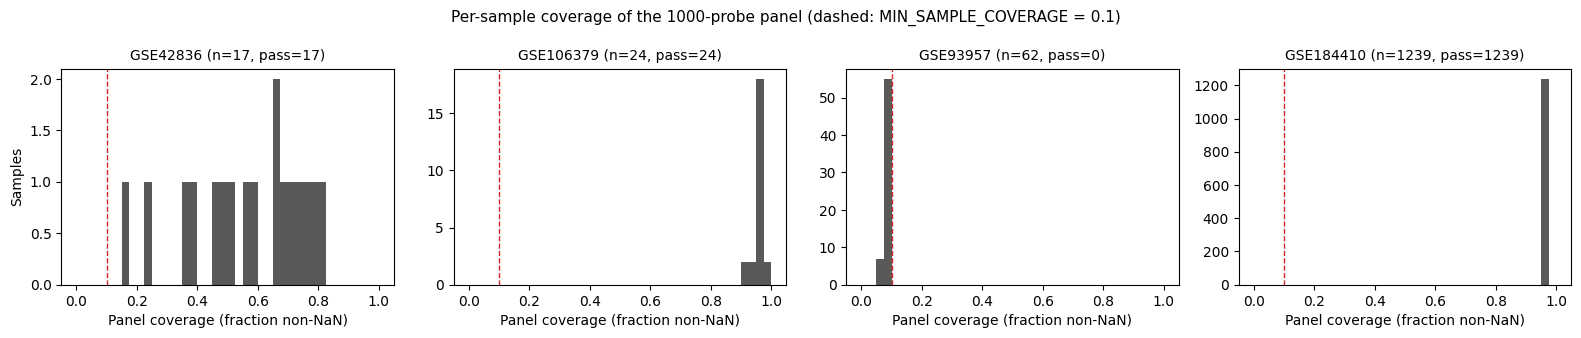

In [70]:
# ---- QC figure: per-sample panel coverage ----------------------------------------
fig, axes = plt.subplots(1, len(blocks), figsize=(4 * len(blocks), 3.4), sharex=True)
for ax, gse in zip(np.atleast_1d(axes), blocks):
    cov = qc_samples.loc[qc_samples["dataset"] == gse, "coverage"]
    ax.hist(cov, bins=np.linspace(0, 1, 41), color="0.35")
    ax.axvline(MIN_SAMPLE_COVERAGE, ls="--", c="tab:red", lw=1)
    ax.set_title(f"{gse} (n={len(cov)}, pass={int((cov >= MIN_SAMPLE_COVERAGE).sum())})", fontsize=10)
    ax.set_xlabel("Panel coverage (fraction non-NaN)")
np.atleast_1d(axes)[0].set_ylabel("Samples")
fig.suptitle(f"Per-sample coverage of the {n_panel}-probe panel "
             f"(dashed: MIN_SAMPLE_COVERAGE = {MIN_SAMPLE_COVERAGE})", fontsize=11)
fig.tight_layout()

qc_fig_path = FIG_DIR / f"qc_sample_coverage.{FMT}"
if SAVE_FIGURES:
    fig.savefig(qc_fig_path, dpi=DPI, bbox_inches="tight")
    plt.close(fig)
    print(f"saved -> {qc_fig_path.relative_to(config.PROJECT_ROOT)}")

    # show the saved file inline (the figure itself is already closed)
    if FMT == "svg":
        display(SVG(filename=str(qc_fig_path)))
    elif FMT == "png":
        display(Image(filename=str(qc_fig_path)))
    else:
        print(f"{FMT} cannot be shown inline — open {qc_fig_path.relative_to(config.PROJECT_ROOT)}")
else:
    display(fig)
    plt.close(fig)

In [71]:
# ---- Save QC tables (toggle) -------------------------------------------------------
if SAVE_QC:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    qc_samples.join(df_meta.drop(columns="dataset")).to_csv(OUT_DIR / "qc_samples.csv")
    qc_probes.to_csv(OUT_DIR / "qc_probes.csv", index=False)
    qc_summary.to_csv(OUT_DIR / "qc_summary.csv", index_label="dataset")
    print(f"QC tables written -> {OUT_DIR.relative_to(config.PROJECT_ROOT)}")
else:
    print("SAVE_QC is False — QC tables not written")

QC tables written -> results/deconvolution/validation_publication


## III.4 NNLS deconvolution

Every QC-passing sample is deconvolved on **its own** non-NaN probes among its dataset's kept
probes, via `deconv_model.deconvolve_single`. W and the sample vector are both selected through
the same explicit probe index, so row *i* of W always matches element *i* of y.

Because the probe set differs between samples, the raw NNLS residual is not comparable across
samples. `rmse = residual / sqrt(n_probes_used)` is recorded alongside it for that purpose.

In [72]:
# ---- Per-sample NNLS helper ------------------------------------------------------
def deconvolve_per_sample(block: pd.DataFrame, W: pd.DataFrame, keep: list) -> tuple:
    '''
    Deconvolve every column of block on that column's own non-NaN probes within keep.

    Returns
    -------
    df_props : pd.DataFrame   tissues x samples (proportions sum to 1 per sample)
    df_stats : pd.DataFrame   samples x [n_probes_used, residual, rmse]
    '''
    W_keep = W.loc[keep]
    props, stats = {}, {}
    for col in block.columns:
        y    = block.loc[keep, col]
        used = y.index[y.notna()]          # explicit index, applied identically to W and y
        if len(used) < W.shape[1]:
            warnings.warn(f"{col}: {len(used)} probes < {W.shape[1]} tissues — skipped")
            continue
        p, res = deconv_model.deconvolve_single(W_keep.loc[used].to_numpy(),
                                                y.loc[used].to_numpy(dtype=float))
        props[col] = pd.Series(p, index=W.columns)
        stats[col] = {"n_probes_used": len(used), "residual": res, "rmse": res / np.sqrt(len(used))}
    return pd.DataFrame(props, index=W.columns), pd.DataFrame.from_dict(stats, orient="index")

In [73]:
# ---- Deconvolve all datasets -------------------------------------------------------
props_parts, stats_parts = [], []
for gse, block in blocks.items():
    passing = qc_samples.index[(qc_samples["dataset"] == gse) & qc_samples["qc_pass"]]
    if not len(passing):
        print(f"{gse}: 0 QC-passing samples — skipped")
        continue
    p, s = deconvolve_per_sample(block[passing], W_full, keep_probes[gse])
    props_parts.append(p)
    stats_parts.append(s)
    print(f"{gse}: {p.shape[1]} samples deconvolved  |  probes used "
          f"{int(s['n_probes_used'].min())}-{int(s['n_probes_used'].max())}  |  "
          f"median rmse {s['rmse'].median():.4f}")

# one table: rows = atlas tissues, columns = every sample (QC-failed samples as NaN columns)
df_props = pd.concat(props_parts, axis=1).reindex(index=W_full.columns, columns=df_meta.index)
df_props.index.name = "tissue"
df_stats = pd.concat(stats_parts)

done = df_stats.index
assert np.allclose(df_props[done].sum(axis=0), 1.0), "proportions do not sum to 1"
assert (df_stats["n_probes_used"] <= n_panel).all()
print(f"\ndf_props: {df_props.shape[0]} tissues x {df_props.shape[1]} samples "
      f"({len(done)} deconvolved, {df_props.shape[1] - len(done)} NaN)")

show_table(df_props)

GSE42836: 17 samples deconvolved  |  probes used 159-808  |  median rmse 0.1239
GSE106379: 24 samples deconvolved  |  probes used 913-977  |  median rmse 0.1016
GSE93957: 0 QC-passing samples — skipped


GSE184410: 1239 samples deconvolved  |  probes used 972-972  |  median rmse 0.0908

df_props: 20 tissues x 1342 samples (1280 deconvolved, 62 NaN)


In [74]:
# ---- Per-sample summary ------------------------------------------------------------
df_sample_summary = (
    df_meta
    .join(qc_samples.drop(columns="dataset"))
    .join(df_stats)
)
df_sample_summary["top_call"]  = df_props[done].idxmax(axis=0).reindex(df_sample_summary.index)
df_sample_summary["top_value"] = df_props[done].max(axis=0).reindex(df_sample_summary.index)

assert df_sample_summary.index.equals(df_props.columns), "summary and proportions out of sync"
show_table(df_sample_summary.groupby("dataset", sort=False).agg(
    samples=("qc_pass", "size"),
    deconvolved=("n_probes_used", "count"),
    median_probes=("n_probes_used", "median"),
    median_rmse=("rmse", "median"),
))
show_table(df_sample_summary)

,samples,deconvolved,median_probes,median_rmse
GSE42836,17,17,583.000,0.124
GSE106379,24,24,967.500,0.102
GSE93957,62,0,NaN,NaN
GSE184410,1239,1239,972.000,0.091


,dataset,gsm,title,tissue,pathology,experiment_group,n_present,coverage,qc_pass,n_probes_used,residual,rmse,top_call,top_value
GSE42836|bone_marrow,GSE42836,GSM1051150,mouse bone marrow,bone marrow,NaN,NaN,487,0.487,True,487.000,2.689,0.122,Femur,0.957
GSE42836|cerebellum,GSE42836,GSM1051151,mouse cerebellum,cerebellum,NaN,NaN,669,0.669,True,669.000,2.861,0.111,Cerebellum,1.000
GSE42836|colon,GSE42836,GSM1051152,mouse colon,colon,NaN,NaN,653,0.653,True,653.000,3.535,0.138,Colon,0.907
GSE42836|cortex,GSE42836,GSM1051153,mouse cortex,cortex,NaN,NaN,782,0.782,True,782.000,3.256,0.116,Brain_Cortex_Subcortical,0.946
GSE42836|heart,GSE42836,GSM1051154,mouse heart,heart,NaN,NaN,394,0.394,True,394.000,2.397,0.121,Heart,0.945
GSE42836|intestine,GSE42836,GSM1051155,mouse intestine,intestine,NaN,NaN,694,0.694,True,694.000,3.864,0.147,Colon,1.000
GSE42836|kidney,GSE42836,GSM1051156,mouse kidney,kidney,NaN,NaN,352,0.352,True,352.000,2.439,0.130,Kidney,0.827
GSE42836|liver,GSE42836,GSM1051157,mouse liver,liver,NaN,NaN,159,0.159,True,159.000,1.504,0.119,Liver,0.859
GSE42836|lung,GSE42836,GSM1051158,mouse lung,lung,NaN,NaN,524,0.524,True,524.000,2.706,0.118,Lung,0.973
GSE42836|olfactory_bulb,GSE42836,GSM1051159,mouse olfactory bulb,olfactory bulb,NaN,NaN,808,0.808,True,808.000,3.984,0.140,Brain_Cortex_Subcortical,0.807


In [75]:
# ---- Save results (toggle) ---------------------------------------------------------
if SAVE_RESULTS:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    df_props.to_csv(OUT_DIR / "deconv_proportions.csv")
    df_sample_summary.to_csv(OUT_DIR / "deconv_sample_summary.csv")
    print(f"results written -> {OUT_DIR.relative_to(config.PROJECT_ROOT)}")
else:
    print("SAVE_RESULTS is False — results not written")

results written -> results/deconvolution/validation_publication


In [76]:
# ---- Combined Excel workbook (one sheet per saved CSV) ----------------------------
# Reads the CSVs just written, so the workbook always matches them exactly.
from openpyxl.styles import Font
from openpyxl.utils import get_column_letter

EXCEL_SHEETS = ["deconv_proportions", "deconv_sample_summary",
                "qc_samples", "qc_probes", "qc_summary"]
EXCEL_PATH   = OUT_DIR / "validation_publication.xlsx"

if SAVE_QC and SAVE_RESULTS:
    with pd.ExcelWriter(EXCEL_PATH, engine="openpyxl") as writer:
        for name in EXCEL_SHEETS:
            df = pd.read_csv(OUT_DIR / f"{name}.csv")
            df.to_excel(writer, sheet_name=name, index=False)
            ws = writer.sheets[name]
            for cell in ws[1]:                                   # bold header row
                cell.font = Font(bold=True)
            for i, col in enumerate(df.columns, start=1):        # auto-fit width (capped)
                width = max(len(str(col)), df[col].astype(str).str.len().max())
                ws.column_dimensions[get_column_letter(i)].width = min(width + 2, 50)
            ws.freeze_panes = "A2"                               # header stays visible
    print(f"Excel written -> {EXCEL_PATH.relative_to(config.PROJECT_ROOT)}")
else:
    print("SAVE_QC and SAVE_RESULTS must both be True — Excel not written")

Excel written -> results/deconvolution/validation_publication/validation_publication.xlsx


## III.5 Sanity readout

Informative only: the top atlas call per sample next to the sample's own tissue label. The
dataset labels are not mapped onto atlas tissue names, so this is read by eye.

In [77]:
# ---- Top call vs sample tissue -----------------------------------------------------
for gse in ["GSE42836", "GSE106379", "GSE93957"]:
    sub = df_sample_summary[(df_sample_summary["dataset"] == gse) & df_sample_summary["qc_pass"]]
    print(f"\n{gse}")
    if sub.empty:
        print("  no QC-passing samples")
        continue
    show_table(sub[["tissue", "top_call", "top_value", "n_probes_used", "rmse"]])

# GSE184410 is large: most frequent top call per tissue label, normal samples only
sub = df_sample_summary[(df_sample_summary["dataset"] == "GSE184410")
                        & df_sample_summary["qc_pass"]
                        & (df_sample_summary["pathology"] == "Normal")]
print(f"\nGSE184410 (pathology == Normal, n={len(sub)}): most frequent top call per tissue")
show_table(sub.groupby("tissue").agg(
    n=("top_call", "size"),
    top_call=("top_call", lambda s: s.value_counts().index[0]),
    share=("top_call", lambda s: s.value_counts(normalize=True).iloc[0]),
    median_top_value=("top_value", "median"),
).sort_values("n", ascending=False), float_format="{:.2f}".format)


GSE42836


,tissue,top_call,top_value,n_probes_used,rmse
GSE42836|bone_marrow,bone marrow,Femur,0.957,487.000,0.122
GSE42836|cerebellum,cerebellum,Cerebellum,1.000,669.000,0.111
GSE42836|colon,colon,Colon,0.907,653.000,0.138
GSE42836|cortex,cortex,Brain_Cortex_Subcortical,0.946,782.000,0.116
GSE42836|heart,heart,Heart,0.945,394.000,0.121
GSE42836|intestine,intestine,Colon,1.000,694.000,0.147
GSE42836|kidney,kidney,Kidney,0.827,352.000,0.130
GSE42836|liver,liver,Liver,0.859,159.000,0.119
GSE42836|lung,lung,Lung,0.973,524.000,0.118
GSE42836|olfactory_bulb,olfactory bulb,Brain_Cortex_Subcortical,0.807,808.000,0.140



GSE106379


,tissue,top_call,top_value,n_probes_used,rmse
GSE106379|B6_M_1,liver,Liver,1.000,973.000,0.095
GSE106379|B6_M_2,liver,Liver,1.000,975.000,0.095
GSE106379|B6_M_3,liver,Liver,1.000,957.000,0.101
GSE106379|B6_F_1,liver,Liver,1.000,977.000,0.096
GSE106379|B6_F_2,liver,Liver,1.000,971.000,0.102
GSE106379|B6_F_3,liver,Liver,1.000,977.000,0.099
GSE106379|C3_M_1,liver,Liver,1.000,951.000,0.111
GSE106379|C3_M_2,liver,Liver,1.000,944.000,0.110
GSE106379|C3_M_3,liver,Liver,1.000,954.000,0.108
GSE106379|C3_F_1,liver,Liver,1.000,955.000,0.108



GSE93957
  no QC-passing samples

GSE184410 (pathology == Normal, n=743): most frequent top call per tissue


,n,top_call,share,median_top_value
Small Intestine,152,Colon,0.97,0.94
Liver,99,Liver,1.00,0.98
Tail,70,Skin_Ears_Tail,0.83,0.93
Spleen,61,Blood_Spleen,0.72,0.71
Frontal Lobe Brain,59,Brain_Cortex_Subcortical,0.95,0.97
Colon,55,Colon,1.00,1.00
Cecum,22,Colon,1.00,0.93
Stomach,20,Stomach,1.00,0.93
Placenta,16,Femur,1.00,0.31
Lung,15,Lung,0.80,0.93
